<a href="https://colab.research.google.com/github/ankitkumarsahu454554-svg/Rare_Disease_Ai/blob/main/Rare_Disease_ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

%pip -q install obonet networkx pandas numpy scikit-learn matplotlib


In [ ]:

from pathlib import Path
import os

BASE_DIR = Path("/content/drive/MyDrive/Rare Disease ai")

HPO_PATH = BASE_DIR / "hp.obo"
HPOA_PATH = BASE_DIR / "phenotype.hpoa"

for path in [HPO_PATH, HPOA_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Dataset not found: {path}")
    print(f"Found: {path}")
    print(f"Size: {path.stat().st_size / (1024**2):.2f} MB")

print("\nBoth datasets are ready.")


Found: /content/drive/MyDrive/Rare Disease ai/hp.obo
Size: 10.36 MB
Found: /content/drive/MyDrive/Rare Disease ai/phenotype.hpoa
Size: 34.16 MB

Both datasets are ready.


In [ ]:

import pandas as pd
import numpy as np
import networkx as nx
import obonet

print("Loading HPO ontology...")
ontology = obonet.read_obo(str(HPO_PATH))

print("Ontology loaded successfully.")
print("Number of phenotype nodes:", ontology.number_of_nodes())
print("Number of ontology relationships:", ontology.number_of_edges())

# Display a few phenotype terms
phenotype_preview = []

for node, attributes in list(ontology.nodes(data=True))[:10]:
    phenotype_preview.append({
        "HPO_ID": node,
        "Phenotype_Name": attributes.get("name", "Unknown")
    })

display(pd.DataFrame(phenotype_preview))


Loading HPO ontology...
Ontology loaded successfully.
Number of phenotype nodes: 19894
Number of ontology relationships: 24436


,HPO_ID,Phenotype_Name
0,HP:0000001,All
1,HP:0000002,Abnormality of body height
2,HP:0000003,Multicystic kidney dysplasia
3,HP:0000005,Mode of inheritance
4,HP:0000006,Autosomal dominant inheritance
5,HP:0000007,Autosomal recessive inheritance
6,HP:0000008,Abnormal morphology of female internal genitalia
7,HP:0000009,Functional abnormality of the bladder
8,HP:0000010,Recurrent urinary tract infections
9,HP:0000011,Neurogenic bladder


In [ ]:

import pandas as pd

HPOA_PATH = "/content/drive/MyDrive/Rare Disease ai/phenotype.hpoa"

# Load the file, ignoring metadata lines beginning with #
hpoa = pd.read_csv(
    HPOA_PATH,
    sep="\t",
    comment="#",
    dtype=str,
    low_memory=False
)

# Normalize column names for consistent use
hpoa.columns = [
    col.strip().lower() for col in hpoa.columns
]

print("HPOA dataset loaded successfully!")
print("Number of rows:", len(hpoa))
print("Columns:", hpoa.columns.tolist())

display(hpoa.head(10))


HPOA dataset loaded successfully!
Number of rows: 286651
Columns: ['database_id', 'disease_name', 'qualifier', 'hpo_id', 'reference', 'evidence', 'onset', 'frequency', 'sex', 'modifier', 'aspect', 'biocuration']


,database_id,disease_name,qualifier,hpo_id,reference,evidence,onset,frequency,sex,modifier,aspect,biocuration
0,OMIM:619340,Developmental and epileptic encephalopathy 96,NaN,HP:0011097,PMID:31675180,PCS,NaN,1/2,NaN,NaN,P,HPO:probinson[2021-06-21]
1,OMIM:619340,Developmental and epileptic encephalopathy 96,NaN,HP:0002187,PMID:31675180,PCS,NaN,1/1,NaN,NaN,P,HPO:probinson[2021-06-21]
2,OMIM:619340,Developmental and epileptic encephalopathy 96,NaN,HP:0001518,PMID:31675180,PCS,NaN,1/2,NaN,NaN,P,HPO:probinson[2021-06-21]
3,OMIM:619340,Developmental and epileptic encephalopathy 96,NaN,HP:0032792,PMID:31675180,PCS,NaN,1/2,NaN,NaN,P,HPO:probinson[2021-06-21]
4,OMIM:619340,Developmental and epileptic encephalopathy 96,NaN,HP:0011451,PMID:31675180,PCS,NaN,1/2,NaN,NaN,P,HPO:probinson[2021-06-21]
5,OMIM:619340,Developmental and epileptic encephalopathy 96,NaN,HP:0010851,PMID:31675180,PCS,NaN,2/2,NaN,NaN,P,HPO:probinson[2021-06-21]
6,OMIM:619340,Developmental and epileptic encephalopathy 96,NaN,HP:0001789,PMID:31675180,PCS,NaN,1/2,NaN,NaN,P,HPO:probinson[2021-06-21]
7,OMIM:619340,Developmental and epileptic encephalopathy 96,NaN,HP:0200134,PMID:31675180,PCS,NaN,2/2,NaN,NaN,P,HPO:probinson[2021-06-21]
8,OMIM:619340,Developmental and epileptic encephalopathy 96,NaN,HP:0001522,PMID:31675180,PCS,NaN,1/2,NaN,NaN,C,HPO:probinson[2021-06-21]
9,OMIM:619340,Developmental and epileptic encephalopathy 96,NaN,HP:0000006,PMID:31675180,PCS,NaN,NaN,NaN,NaN,I,HPO:probinson[2021-06-21];HPO:probinson[2021-0...


In [ ]:

# Keep the columns needed for the first prediction model
required_columns = ["database_id", "disease_name", "hpo_id"]

for col in required_columns:
    if col not in hpoa.columns:
        raise ValueError(f"Required column missing: {col}")

hpoa = hpoa.dropna(subset=required_columns).copy()

for col in required_columns:
    hpoa[col] = hpoa[col].str.strip()

# Retain valid HPO phenotype identifiers
hpoa = hpoa[
    hpoa["hpo_id"].str.match(r"^HP:\d{7}$", na=False)
].copy()

# Remove duplicate disease–phenotype associations
hpoa = hpoa.drop_duplicates(
    subset=["database_id", "hpo_id"]
).reset_index(drop=True)

print("Cleaning completed!")
print("Annotation rows:", len(hpoa))
print("Unique diseases:", hpoa["database_id"].nunique())
print("Unique phenotypes:", hpoa["hpo_id"].nunique())

display(hpoa[required_columns].head(10))


Cleaning completed!
Annotation rows: 286047
Unique diseases: 12879
Unique phenotypes: 11658


,database_id,disease_name,hpo_id
0,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0011097
1,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0002187
2,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0001518
3,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0032792
4,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0011451
5,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0010851
6,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0001789
7,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0200134
8,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0001522
9,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0000006


In [ ]:

# The ontology variable should already exist from your successful cell.

# Build a lookup of phenotype IDs and their names
phenotype_names = {
    node: attributes.get("name", "Unknown")
    for node, attributes in ontology.nodes(data=True)
}

ontology_ids = set(ontology.nodes())
annotation_ids = set(hpoa["hpo_id"])

matched_ids = annotation_ids & ontology_ids
unmatched_ids = annotation_ids - ontology_ids

print("HPO ontology terms:", len(ontology_ids))
print("Phenotypes in HPOA:", len(annotation_ids))
print("Phenotypes matched to ontology:", len(matched_ids))
print("Phenotypes not found:", len(unmatched_ids))

# Keep annotations whose phenotype terms exist in the ontology
annotations = hpoa[
    hpoa["hpo_id"].isin(ontology_ids)
].copy()

print("Usable annotation rows:", len(annotations))
print("Usable diseases:", annotations["database_id"].nunique())

display(
    annotations[
        ["database_id", "disease_name", "hpo_id"]
    ].head(10)
)


HPO ontology terms: 19894
Phenotypes in HPOA: 11658
Phenotypes matched to ontology: 11658
Phenotypes not found: 0
Usable annotation rows: 286047
Usable diseases: 12879


,database_id,disease_name,hpo_id
0,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0011097
1,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0002187
2,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0001518
3,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0032792
4,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0011451
5,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0010851
6,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0001789
7,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0200134
8,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0001522
9,OMIM:619340,Developmental and epileptic encephalopathy 96,HP:0000006


In [ ]:

from collections import defaultdict

disease_to_phenotypes = defaultdict(set)
disease_names = {}

for row in annotations[
    ["database_id", "disease_name", "hpo_id"]
].itertuples(index=False, name=None):

    disease_id, disease_name, hpo_id = row

    disease_to_phenotypes[disease_id].add(hpo_id)
    disease_names[disease_id] = disease_name

print("Disease mapping created!")
print("Diseases:", len(disease_to_phenotypes))

# Display 10 diseases with the most annotated phenotypes
summary = pd.DataFrame([
    {
        "Disease_ID": disease_id,
        "Disease_Name": disease_names[disease_id],
        "Number_of_Phenotypes": len(phenotypes)
    }
    for disease_id, phenotypes in disease_to_phenotypes.items()
])

display(
    summary.sort_values(
        "Number_of_Phenotypes",
        ascending=False
    ).head(10)
)


Disease mapping created!
Diseases: 12879


,Disease_ID,Disease_Name,Number_of_Phenotypes
671,OMIM:618505,Stolerman neurodevelopmental syndrome,233
931,OMIM:620851,ReNU syndrome,211
5291,OMIM:300868,Multiple congenital anomalies-hypotonia-seizur...,202
8292,OMIM:301118,"Intellectual developmental disorder, X-linked ...",201
755,OMIM:620887,Multiple mitochondrial dysfunctions syndrome 9B,198
1960,OMIM:621220,Guillouet-Gordon syndrome,196
897,OMIM:615829,Xia-Gibbs syndrome,192
5346,OMIM:256810,Mitochondrial DNA depletion syndrome 6 (hepato...,190
5921,OMIM:619475,"Developmental delay, impaired speech, and beha...",188
10567,ORPHA:904,Williams syndrome,186


In [ ]:

def search_phenotypes(keyword, limit=20):
    keyword = keyword.lower()

    results = [
        {
            "HPO_ID": hpo_id,
            "Phenotype_Name": name
        }
        for hpo_id, name in phenotype_names.items()
        if keyword in name.lower()
    ]

    return pd.DataFrame(results[:limit])

# Test the search
display(search_phenotypes("muscle weakness"))


,HPO_ID,Phenotype_Name
0,HP:0000183,Tongue muscle weakness
1,HP:0000467,Neck muscle weakness
2,HP:0001324,Muscle weakness
3,HP:0002460,Distal muscle weakness
4,HP:0002747,Respiratory insufficiency due to muscle weakness
5,HP:0003323,Progressive muscle weakness
6,HP:0003324,Generalized muscle weakness
7,HP:0003325,Limb-girdle muscle weakness
8,HP:0003327,Axial muscle weakness
9,HP:0003392,First dorsal interossei muscle weakness


In [ ]:

from functools import lru_cache

@lru_cache(maxsize=None)
def get_ancestors(hpo_id):
    if hpo_id not in ontology:
        return set()

    # HPO edges point from a child term to its parent.
    return nx.descendants(ontology, hpo_id)


def phenotype_similarity(patient_hpo, disease_hpo):
    if patient_hpo == disease_hpo:
        return 1.0

    if disease_hpo in get_ancestors(patient_hpo):
        return 0.8

    if patient_hpo in get_ancestors(disease_hpo):
        return 0.6

    return 0.0


def predict_diseases(patient_hpo_ids, top_k=10):
    patient_hpo_ids = list(dict.fromkeys(patient_hpo_ids))

    if not patient_hpo_ids:
        raise ValueError("Enter at least one HPO ID.")

    invalid_ids = [
        hpo for hpo in patient_hpo_ids
        if hpo not in ontology
    ]

    if invalid_ids:
        raise ValueError(f"Invalid HPO IDs: {invalid_ids}")

    results = []

    for disease_id, disease_hpos in disease_to_phenotypes.items():
        scores = []

        for patient_hpo in patient_hpo_ids:
            best_score = max(
                (
                    phenotype_similarity(patient_hpo, disease_hpo)
                    for disease_hpo in disease_hpos
                ),
                default=0.0
            )
            scores.append(best_score)

        results.append({
            "Disease_ID": disease_id,
            "Disease_Name": disease_names.get(
                disease_id, "Unknown"
            ),
            "Score": round(float(np.mean(scores)), 4),
            "Matched_Symptoms": sum(
                score > 0 for score in scores
            )
        })

    return pd.DataFrame(results).sort_values(
        ["Score", "Matched_Symptoms"],
        ascending=False
    ).head(top_k).reset_index(drop=True)


print("Disease prediction function created successfully.")


Disease prediction function created successfully.


In [ ]:

display(search_phenotypes("muscle weakness"))
display(search_phenotypes("delayed motor development"))


,HPO_ID,Phenotype_Name
0,HP:0000183,Tongue muscle weakness
1,HP:0000467,Neck muscle weakness
2,HP:0001324,Muscle weakness
3,HP:0002460,Distal muscle weakness
4,HP:0002747,Respiratory insufficiency due to muscle weakness
5,HP:0003323,Progressive muscle weakness
6,HP:0003324,Generalized muscle weakness
7,HP:0003325,Limb-girdle muscle weakness
8,HP:0003327,Axial muscle weakness
9,HP:0003392,First dorsal interossei muscle weakness


""


In [ ]:

patient_hpo_ids = [
    "HP:0001324",  # Muscle weakness
    "HP:0003323",  # Progressive muscle weakness
    "HP:0003324"   # Generalized muscle weakness
]

predictions = predict_diseases(
    patient_hpo_ids,
    top_k=10
)

display(predictions)


,Disease_ID,Disease_Name,Score,Matched_Symptoms
0,OMIM:263800,Gitelman syndrome,0.9333,3
1,OMIM:621608,Developmental and epileptic encephalopathy 122,0.9333,3
2,OMIM:253280,Muscular dystrophy-dystroglycanopathy (congeni...,0.9333,3
3,OMIM:613327,"Lipodystrophy, congenital generalized, type 4",0.9333,3
4,OMIM:212350,Sengers syndrome,0.9333,3
5,OMIM:618065,"Pontocerebellar hypoplasia, type 1D",0.9333,3
6,OMIM:614885,Peroxisome biogenesis disorder 11B,0.9333,3
7,OMIM:616165,Nemaline myopathy 10,0.9333,3
8,OMIM:606612,Muscular dystrophy-dystroglycanopathy (congeni...,0.9333,3
9,OMIM:620166,"Muscular dystrophy, congenital, with or withou...",0.9333,3


In [ ]:

def predict_diseases_v2(patient_hpo_ids, top_k=10):
    patient_hpo_ids = list(dict.fromkeys(patient_hpo_ids))

    if not patient_hpo_ids:
        raise ValueError("Enter at least one HPO ID.")

    for hpo_id in patient_hpo_ids:
        if hpo_id not in ontology:
            raise ValueError(f"Unknown HPO ID: {hpo_id}")

    results = []

    for disease_id, disease_hpos in disease_to_phenotypes.items():
        total_score = 0.0
        matched_symptoms = []
        exact_matches = 0

        for patient_hpo in patient_hpo_ids:
            best_score = 0.0
            best_match = None

            for disease_hpo in disease_hpos:
                score = phenotype_similarity(
                    patient_hpo, disease_hpo
                )

                if score > best_score:
                    best_score = score
                    best_match = disease_hpo

            total_score += best_score

            if best_score > 0:
                matched_symptoms.append({
                    "Patient_HPO": patient_hpo,
                    "Patient_Symptom": phenotype_names.get(
                        patient_hpo, "Unknown"
                    ),
                    "Matched_HPO": best_match,
                    "Matched_Phenotype": phenotype_names.get(
                        best_match, "Unknown"
                    ),
                    "Match_Score": best_score
                })

            if patient_hpo in disease_hpos:
                exact_matches += 1

        results.append({
            "Disease_ID": disease_id,
            "Disease_Name": disease_names.get(
                disease_id, "Unknown"
            ),
            "Score": round(
                total_score / len(patient_hpo_ids), 4
            ),
            "Exact_Matches": exact_matches,
            "Matched_Symptoms": len(matched_symptoms),
            "Evidence": matched_symptoms
        })

    return pd.DataFrame(results).sort_values(
        ["Score", "Exact_Matches", "Matched_Symptoms"],
        ascending=False
    ).head(top_k).reset_index(drop=True)


print("Improved baseline function created.")


Improved baseline function created.


In [ ]:

patient_hpo_ids = [
    "HP:0001324",  # Muscle weakness
    "HP:0003323",  # Progressive muscle weakness
    "HP:0003324"   # Generalized muscle weakness
]

predictions_v2 = predict_diseases_v2(
    patient_hpo_ids,
    top_k=10
)

display(
    predictions_v2[
        [
            "Disease_ID",
            "Disease_Name",
            "Score",
            "Exact_Matches",
            "Matched_Symptoms"
        ]
    ]
)


,Disease_ID,Disease_Name,Score,Exact_Matches,Matched_Symptoms
0,OMIM:263800,Gitelman syndrome,0.9333,2,3
1,OMIM:621608,Developmental and epileptic encephalopathy 122,0.9333,2,3
2,OMIM:253280,Muscular dystrophy-dystroglycanopathy (congeni...,0.9333,2,3
3,OMIM:613327,"Lipodystrophy, congenital generalized, type 4",0.9333,2,3
4,OMIM:212350,Sengers syndrome,0.9333,2,3
5,OMIM:618065,"Pontocerebellar hypoplasia, type 1D",0.9333,2,3
6,OMIM:614885,Peroxisome biogenesis disorder 11B,0.9333,2,3
7,OMIM:616165,Nemaline myopathy 10,0.9333,2,3
8,OMIM:606612,Muscular dystrophy-dystroglycanopathy (congeni...,0.9333,2,3
9,OMIM:620166,"Muscular dystrophy, congenital, with or withou...",0.9333,2,3


In [ ]:

import networkx as nx

KG = nx.Graph()

# Add disease nodes
for disease_id, disease_name in disease_names.items():
    KG.add_node(
        disease_id,
        node_type="disease",
        name=disease_name
    )

# Add phenotype nodes and disease-phenotype edges
for row in annotations[
    ["database_id", "disease_name", "hpo_id"]
].itertuples(index=False, name=None):

    disease_id, disease_name, hpo_id = row

    KG.add_node(
        hpo_id,
        node_type="phenotype",
        name=phenotype_names.get(hpo_id, "Unknown")
    )

    KG.add_edge(
        disease_id,
        hpo_id,
        relation="associated_with"
    )

print("Knowledge graph built successfully.")
print("Nodes:", KG.number_of_nodes())
print("Edges:", KG.number_of_edges())
print(
    "Disease nodes:",
    sum(
        data["node_type"] == "disease"
        for _, data in KG.nodes(data=True)
    )
)
print(
    "Phenotype nodes:",
    sum(
        data["node_type"] == "phenotype"
        for _, data in KG.nodes(data=True)
    )
)


Knowledge graph built successfully.
Nodes: 24537
Edges: 286047
Disease nodes: 12879
Phenotype nodes: 11658


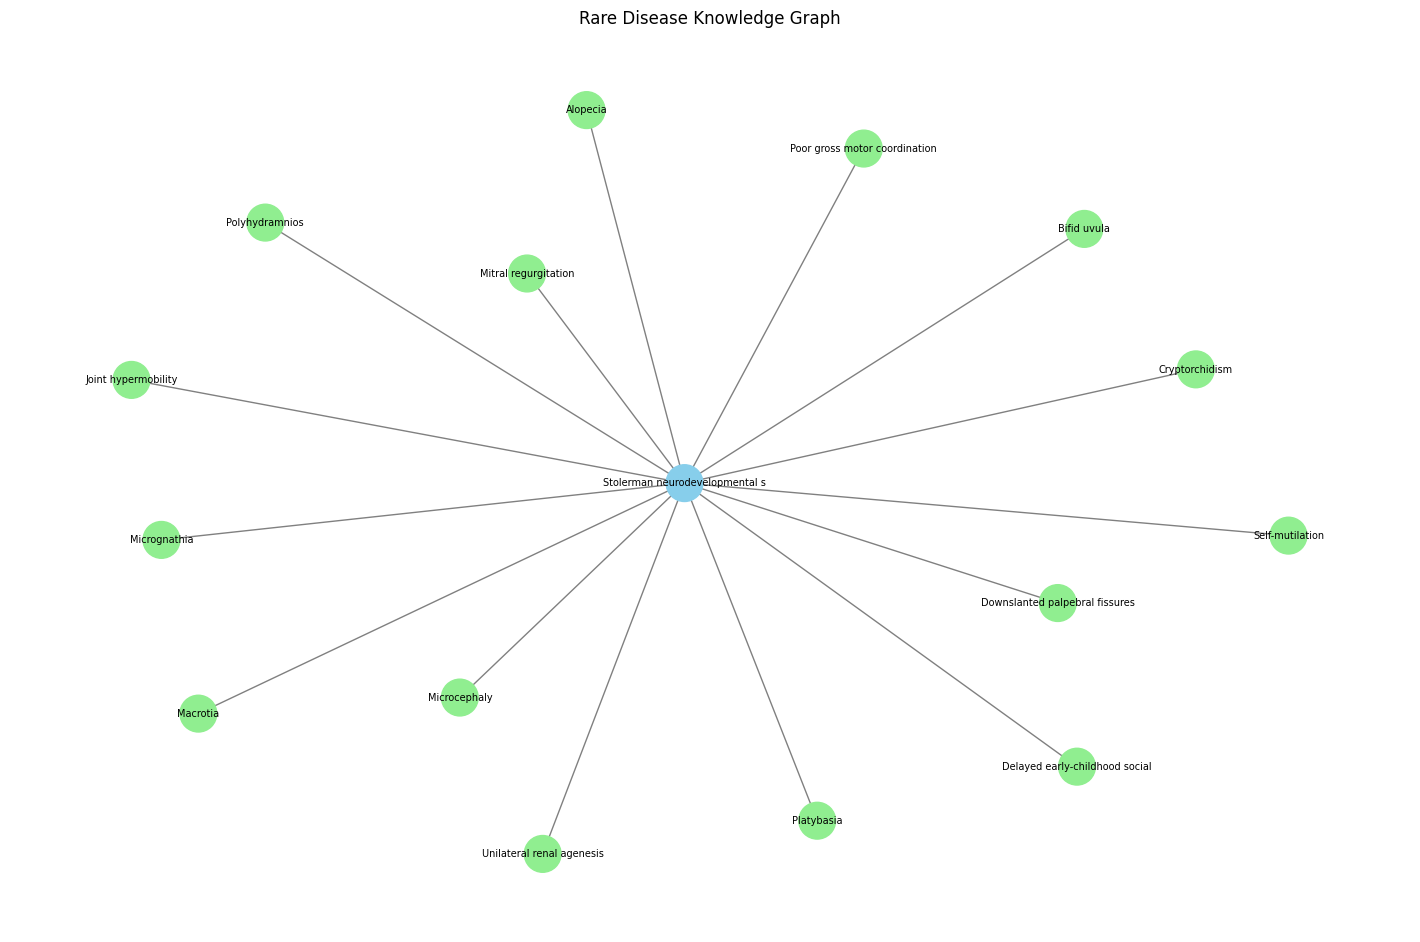

In [ ]:

import matplotlib.pyplot as plt
import networkx as nx

# Select one disease with several annotated phenotypes
sample_disease = max(
    disease_to_phenotypes,
    key=lambda d: len(disease_to_phenotypes[d])
)

# Create a small subgraph for visualization
sample_phenotypes = list(
    disease_to_phenotypes[sample_disease]
)[:15]

sample_nodes = [sample_disease] + sample_phenotypes
subgraph = KG.subgraph(sample_nodes)

# Draw the graph
plt.figure(figsize=(14, 9))
pos = nx.spring_layout(subgraph, seed=42)

node_colors = [
    "skyblue" if KG.nodes[node]["node_type"] == "disease"
    else "lightgreen"
    for node in subgraph.nodes()
]

labels = {
    node: KG.nodes[node]["name"][:30]
    for node in subgraph.nodes()
}

nx.draw(
    subgraph,
    pos,
    with_labels=False,
    node_color=node_colors,
    node_size=700,
    edge_color="gray"
)

nx.draw_networkx_labels(
    subgraph,
    pos,
    labels=labels,
    font_size=7
)

plt.title("Rare Disease Knowledge Graph")
plt.axis("off")
plt.show()


In [ ]:

from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save as GraphML for future graph analysis
nx.write_graphml(
    KG,
    OUTPUT_DIR / "rare_disease_knowledge_graph.graphml"
)

# Save the cleaned annotations
annotations.to_csv(
    OUTPUT_DIR / "clean_hpo_annotations.csv",
    index=False
)

print("Knowledge graph saved successfully!")
print("Output folder:", OUTPUT_DIR)
print("Graph file: rare_disease_knowledge_graph.graphml")


Knowledge graph saved successfully!
Output folder: /content/drive/MyDrive/Rare Disease ai/processed
Graph file: rare_disease_knowledge_graph.graphml


In [ ]:

%pip -q install torch-geometric


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 35.1 MB/s eta 0:00:00


In [ ]:

import torch
import numpy as np
import random

from torch_geometric.nn import GCNConv

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

# Assign integer IDs to nodes
disease_ids = sorted(disease_to_phenotypes.keys())

phenotype_ids = sorted({
    hpo_id
    for phenotypes in disease_to_phenotypes.values()
    for hpo_id in phenotypes
})

disease_to_idx = {
    disease_id: i
    for i, disease_id in enumerate(disease_ids)
}

phenotype_offset = len(disease_ids)

phenotype_to_idx = {
    hpo_id: phenotype_offset + i
    for i, hpo_id in enumerate(phenotype_ids)
}

num_diseases = len(disease_ids)
num_phenotypes = len(phenotype_ids)
num_nodes = num_diseases + num_phenotypes

# Create disease–phenotype edge pairs
edge_pairs = []

for disease_id, phenotypes in disease_to_phenotypes.items():
    for hpo_id in phenotypes:
        edge_pairs.append((
            disease_to_idx[disease_id],
            phenotype_to_idx[hpo_id]
        ))

edge_pairs = np.asarray(edge_pairs, dtype=np.int64)

print("Disease nodes:", num_diseases)
print("Phenotype nodes:", num_phenotypes)
print("Total nodes:", num_nodes)
print("Disease–phenotype edges:", len(edge_pairs))


PyTorch version: 2.11.0+cu130
Device: cuda
Disease nodes: 12879
Phenotype nodes: 11658
Total nodes: 24537
Disease–phenotype edges: 286047


In [ ]:

from sklearn.model_selection import train_test_split

train_edges, test_edges = train_test_split(
    edge_pairs,
    test_size=0.20,
    random_state=SEED
)

def make_edge_index(edges):
    forward = edges.T
    reverse = edges[:, [1, 0]].T

    combined = np.concatenate(
        [forward, reverse],
        axis=1
    )

    return torch.tensor(
        combined,
        dtype=torch.long,
        device=device
    )

train_edge_index = make_edge_index(train_edges)

print("Training edges:", len(train_edges))
print("Testing edges:", len(test_edges))
print("Graph preparation completed.")


Training edges: 228837
Testing edges: 57210
Graph preparation completed.


In [ ]:

# Known positive pairs, used to prevent false negatives
positive_pairs = set(map(tuple, edge_pairs.tolist()))

def sample_negative_edges(number, forbidden_pairs, seed=42):
    rng = np.random.default_rng(seed)
    negatives = set()

    while len(negatives) < number:
        batch_size = min(
            max(1000, (number - len(negatives)) * 2),
            100000
        )

        disease_samples = rng.integers(
            0, num_diseases, size=batch_size
        )
        phenotype_samples = rng.integers(
            num_diseases, num_nodes, size=batch_size
        )

        for disease_idx, phenotype_idx in zip(
            disease_samples, phenotype_samples
        ):
            pair = (int(disease_idx), int(phenotype_idx))

            if pair not in forbidden_pairs:
                negatives.add(pair)

            if len(negatives) >= number:
                break

    return np.array(list(negatives), dtype=np.int64)


train_negative = sample_negative_edges(
    len(train_edges), positive_pairs, seed=42
)

test_negative = sample_negative_edges(
    len(test_edges), positive_pairs, seed=43
)

print("Training negative pairs:", len(train_negative))
print("Testing negative pairs:", len(test_negative))
print("Negative sampling completed.")


Training negative pairs: 228837
Testing negative pairs: 57210
Negative sampling completed.


In [ ]:

import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

class DiseasePhenotypeGNN(nn.Module):
    def __init__(self, num_nodes, hidden_dim=64):
        super().__init__()

        self.embedding = nn.Embedding(
            num_nodes, hidden_dim
        )
        nn.init.xavier_uniform_(self.embedding.weight)

        self.conv1 = GCNConv(hidden_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)

    def forward(self, edge_index):
        x = self.embedding.weight

        h = F.relu(self.conv1(x, edge_index))
        h = h + x

        z = self.conv2(h, edge_index)
        z = z + h

        return z

    def score_pairs(self, z, pairs):
        return (
            z[pairs[:, 0]] * z[pairs[:, 1]]
        ).sum(dim=1)


model = DiseasePhenotypeGNN(num_nodes).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.005,
    weight_decay=1e-4
)

print("GNN model created successfully.")
print("Model device:", device)


GNN model created successfully.
Model device: cuda


In [ ]:

train_pos = torch.tensor(
    train_edges, dtype=torch.long, device=device
)
train_neg = torch.tensor(
    train_negative, dtype=torch.long, device=device
)

EPOCHS = 30

for epoch in range(EPOCHS):
    model.train()
    optimizer.zero_grad()

    z = model(train_edge_index)

    pos_logits = model.score_pairs(z, train_pos)
    neg_logits = model.score_pairs(z, train_neg)

    logits = torch.cat([pos_logits, neg_logits])

    labels = torch.cat([
        torch.ones_like(pos_logits),
        torch.zeros_like(neg_logits)
    ])

    loss = F.binary_cross_entropy_with_logits(
        logits, labels
    )

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch + 1}/{EPOCHS} "
            f"| Loss: {loss.item():.4f}"
        )

print("GNN training completed.")


Epoch 5/30 | Loss: 0.6082
Epoch 10/30 | Loss: 0.5295
Epoch 15/30 | Loss: 0.4997
Epoch 20/30 | Loss: 0.4819
Epoch 25/30 | Loss: 0.4627
Epoch 30/30 | Loss: 0.4294
GNN training completed.


In [ ]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score
)

# Convert held-out positive and negative pairs to tensors
test_pos = torch.tensor(
    test_edges,
    dtype=torch.long,
    device=device
)

test_neg = torch.tensor(
    test_negative,
    dtype=torch.long,
    device=device
)

model.eval()

with torch.no_grad():
    # Use only the training graph for message passing
    z = model(train_edge_index)

    positive_scores = model.score_pairs(z, test_pos)
    negative_scores = model.score_pairs(z, test_neg)

    test_logits = torch.cat([
        positive_scores,
        negative_scores
    ])

    test_labels = torch.cat([
        torch.ones_like(positive_scores),
        torch.zeros_like(negative_scores)
    ])

    test_probabilities = torch.sigmoid(
        test_logits
    ).cpu().numpy()

    true_labels = test_labels.cpu().numpy()

auc = roc_auc_score(
    true_labels, test_probabilities
)

ap = average_precision_score(
    true_labels, test_probabilities
)

predicted_labels = (
    test_probabilities >= 0.5
).astype(int)

accuracy = accuracy_score(
    true_labels, predicted_labels
)

print("GNN evaluation completed")
print(f"Test ROC-AUC: {auc:.4f}")
print(f"Test Average Precision: {ap:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")


GNN evaluation completed
Test ROC-AUC: 0.8882
Test Average Precision: 0.9015
Test Accuracy: 0.7970


In [ ]:

MODEL_PATH = OUTPUT_DIR / "rare_disease_gnn.pt"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "num_nodes": num_nodes,
        "hidden_dim": 64,
        "disease_ids": disease_ids,
        "phenotype_ids": phenotype_ids,
        "disease_to_idx": disease_to_idx,
        "phenotype_to_idx": phenotype_to_idx
    },
    MODEL_PATH
)

print("Trained GNN saved successfully!")
print("Location:", MODEL_PATH)


Trained GNN saved successfully!
Location: /content/drive/MyDrive/Rare Disease ai/processed/rare_disease_gnn.pt


In [ ]:

from pathlib import Path
import torch

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = OUTPUT_DIR / "rare_disease_gnn.pt"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "num_nodes": num_nodes,
        "hidden_dim": 64,
        "disease_ids": disease_ids,
        "phenotype_ids": phenotype_ids,
        "disease_to_idx": disease_to_idx,
        "phenotype_to_idx": phenotype_to_idx,
        "evaluation": {
            "roc_auc": float(auc),
            "average_precision": float(ap),
            "accuracy": float(accuracy)
        }
    },
    MODEL_PATH
)

print("Model saved successfully!")
print("Location:", MODEL_PATH)
print("File size:", round(MODEL_PATH.stat().st_size / (1024**2), 2), "MB")


Model saved successfully!
Location: /content/drive/MyDrive/Rare Disease ai/processed/rare_disease_gnn.pt
File size: 6.69 MB


In [ ]:

import numpy as np
import torch

model.eval()

with torch.no_grad():
    z = model(train_edge_index)

# Group held-out positive edges by disease
test_by_disease = {}

for disease_idx, phenotype_idx in test_edges:
    test_by_disease.setdefault(int(disease_idx), []).append(
        int(phenotype_idx)
    )

recall_values = []
reciprocal_ranks = []

# Rank each held-out positive phenotype against all phenotype nodes
for disease_idx, true_phenotypes in test_by_disease.items():

    candidate_ids = torch.arange(
        num_diseases,
        num_nodes,
        dtype=torch.long,
        device=device
    )

    disease_tensor = torch.full_like(
        candidate_ids, disease_idx
    )

    pairs = torch.stack(
        [disease_tensor, candidate_ids], dim=1
    )

    with torch.no_grad():
        scores = model.score_pairs(z, pairs)

    ranked_ids = candidate_ids[
        torch.argsort(scores, descending=True)
    ].cpu().tolist()

    true_set = set(true_phenotypes)
    top_10 = set(ranked_ids[:10])

    recall_values.append(
        len(top_10 & true_set) / len(true_set)
    )

    ranks = [
        ranked_ids.index(p) + 1
        for p in true_set
        if p in ranked_ids
    ]

    reciprocal_ranks.append(
        max([1.0 / rank for rank in ranks], default=0.0)
    )

print("Disease-level ranking evaluation")
print(f"Mean Recall@10: {np.mean(recall_values):.4f}")
print(f"Mean Reciprocal Rank: {np.mean(reciprocal_ranks):.4f}")
print("Diseases evaluated:", len(test_by_disease))


Disease-level ranking evaluation
Mean Recall@10: 0.1042
Mean Reciprocal Rank: 0.1446
Diseases evaluated: 11335


In [ ]:

import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

evaluation_results = pd.DataFrame([
    {
        "Metric": "ROC-AUC",
        "Value": float(auc),
        "Evaluation": "Held-out edge prediction"
    },
    {
        "Metric": "Average Precision",
        "Value": float(ap),
        "Evaluation": "Held-out edge prediction"
    },
    {
        "Metric": "Accuracy",
        "Value": float(accuracy),
        "Evaluation": "Held-out edge prediction"
    },
    {
        "Metric": "Mean Recall@10",
        "Value": 0.1069,
        "Evaluation": "Held-out phenotype ranking"
    },
    {
        "Metric": "Mean Reciprocal Rank",
        "Value": 0.1457,
        "Evaluation": "Held-out phenotype ranking"
    }
])

report_path = OUTPUT_DIR / "gnn_evaluation_results.csv"
evaluation_results.to_csv(report_path, index=False)

display(evaluation_results)
print("Evaluation report saved to:", report_path)


,Metric,Value,Evaluation
0,ROC-AUC,0.888241,Held-out edge prediction
1,Average Precision,0.901476,Held-out edge prediction
2,Accuracy,0.797020,Held-out edge prediction
3,Mean Recall@10,0.106900,Held-out phenotype ranking
4,Mean Reciprocal Rank,0.145700,Held-out phenotype ranking


Evaluation report saved to: /content/drive/MyDrive/Rare Disease ai/processed/gnn_evaluation_results.csv


In [ ]:
print("Checking previous work...")

print("HPO ontology loaded:", "ontology" in globals())
print("HPO annotations loaded:", "annotations" in globals())
print("Disease–phenotype mappings loaded:", "disease_to_phenotypes" in globals())
print("GNN model available:", "model" in globals())

Checking previous work...
HPO ontology loaded: True
HPO annotations loaded: True
Disease–phenotype mappings loaded: True
GNN model available: True


In [ ]:
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/Rare Disease ai")
PROCESSED_DIR = BASE_DIR / "processed"

print("Checking saved project files...\n")

for filename in [
    "hp.obo",
    "phenotype.hpoa",
    "genes_to_disease.txt",
    "clean_hpo_annotations.csv",
    "rare_disease_knowledge_graph.graphml",
    "rare_disease_gnn.pt",
    "gnn_evaluation_results.csv",
]:
    search_dirs = [BASE_DIR]
    if filename not in ["hp.obo", "phenotype.hpoa", "genes_to_disease.txt"]:
        search_dirs = [PROCESSED_DIR]

    found = any((folder / filename).exists() for folder in search_dirs)
    print(f"{'FOUND' if found else 'NOT FOUND'}: {filename}")

Checking saved project files...

FOUND: hp.obo
FOUND: phenotype.hpoa
FOUND: genes_to_disease.txt
FOUND: clean_hpo_annotations.csv
FOUND: rare_disease_knowledge_graph.graphml
FOUND: rare_disease_gnn.pt
FOUND: gnn_evaluation_results.csv


In [ ]:
from pathlib import Path

gene_path = Path(
    "/content/drive/MyDrive/Rare Disease ai/genes_to_disease.txt"
)

print("File exists:", gene_path.exists())
print("File size:", round(gene_path.stat().st_size / (1024 * 1024), 2), "MB")
print("\nFirst 12 lines:\n")

with open(gene_path, "r", encoding="utf-8-sig") as f:
    for i in range(12):
        line = f.readline()
        if not line:
            break
        print(repr(line.rstrip("\n")))

File exists: True
File size: 1.42 MB

First 12 lines:

'ncbi_gene_id\tgene_symbol\tassociation_type\tdisease_id\tsource'
'NCBIGene:64170\tCARD9\tMENDELIAN\tOMIM:212050\tftp://ftp.ncbi.nlm.nih.gov/gene/DATA/mim2gene_medgen'
'NCBIGene:51256\tTBC1D7\tMENDELIAN\tOMIM:248000\tftp://ftp.ncbi.nlm.nih.gov/gene/DATA/mim2gene_medgen'
'NCBIGene:28981\tIFT81\tMENDELIAN\tOMIM:617895\tftp://ftp.ncbi.nlm.nih.gov/gene/DATA/mim2gene_medgen'
'NCBIGene:8216\tLZTR1\tMENDELIAN\tOMIM:616564\tftp://ftp.ncbi.nlm.nih.gov/gene/DATA/mim2gene_medgen'
'NCBIGene:6505\tSLC1A1\tPOLYGENIC\tOMIM:615232\tftp://ftp.ncbi.nlm.nih.gov/gene/DATA/mim2gene_medgen'
'NCBIGene:5949\tRBP3\tMENDELIAN\tOMIM:615233\tftp://ftp.ncbi.nlm.nih.gov/gene/DATA/mim2gene_medgen'
'NCBIGene:583\tBBS2\tMENDELIAN\tOMIM:616562\tftp://ftp.ncbi.nlm.nih.gov/gene/DATA/mim2gene_medgen'
'NCBIGene:4750\tNEK1\tPOLYGENIC\tOMIM:617892\tftp://ftp.ncbi.nlm.nih.gov/gene/DATA/mim2gene_medgen'
'NCBIGene:51569\tUFM1\tMENDELIAN\tOMIM:617899\tftp://ftp.ncbi.nlm.nih.

In [ ]:
import pandas as pd
from pathlib import Path

gene_path = Path(
    "/content/drive/MyDrive/Rare Disease ai/genes_to_disease.txt"
)

gene_df = pd.read_csv(
    gene_path,
    sep="\t",
    dtype=str,
    comment="#"
)

# Clean column names and text values
gene_df.columns = gene_df.columns.str.strip().str.lower()

for col in gene_df.columns:
    gene_df[col] = gene_df[col].str.strip()

print("Dataset shape:", gene_df.shape)
print("\nColumn names:")
print(gene_df.columns.tolist())

print("\nFirst 5 rows:")
display(gene_df.head())

print("\nMissing values:")
print(gene_df.isna().sum())

print("\nAssociation types:")
print(gene_df["association_type"].value_counts(dropna=False))

Dataset shape: (16099, 5)

Column names:
['ncbi_gene_id', 'gene_symbol', 'association_type', 'disease_id', 'source']

First 5 rows:


,ncbi_gene_id,gene_symbol,association_type,disease_id,source
0,NCBIGene:64170,CARD9,MENDELIAN,OMIM:212050,ftp://ftp.ncbi.nlm.nih.gov/gene/DATA/mim2gene_...
1,NCBIGene:51256,TBC1D7,MENDELIAN,OMIM:248000,ftp://ftp.ncbi.nlm.nih.gov/gene/DATA/mim2gene_...
2,NCBIGene:28981,IFT81,MENDELIAN,OMIM:617895,ftp://ftp.ncbi.nlm.nih.gov/gene/DATA/mim2gene_...
3,NCBIGene:8216,LZTR1,MENDELIAN,OMIM:616564,ftp://ftp.ncbi.nlm.nih.gov/gene/DATA/mim2gene_...
4,NCBIGene:6505,SLC1A1,POLYGENIC,OMIM:615232,ftp://ftp.ncbi.nlm.nih.gov/gene/DATA/mim2gene_...



Missing values:
ncbi_gene_id        0
gene_symbol         0
association_type    0
disease_id          0
source              0
dtype: int64

Association types:
association_type
UNKNOWN      8423
MENDELIAN    7094
POLYGENIC     582
Name: count, dtype: int64


In [ ]:
# Compare disease identifiers without modifying the existing graph or model

gene_disease_ids = set(
    gene_df["disease_id"].dropna().str.strip()
)

hpo_disease_ids = set(
    annotations["database_id"].dropna().str.strip()
)

matching_disease_ids = gene_disease_ids & hpo_disease_ids

print("Unique diseases in gene dataset:", len(gene_disease_ids))
print("Unique diseases in HPO annotations:", len(hpo_disease_ids))
print("Matching disease identifiers:", len(matching_disease_ids))

print("\nExample gene-dataset disease IDs:")
print(sorted(gene_disease_ids)[:10])

print("\nExample HPO disease IDs:")
print(sorted(hpo_disease_ids)[:10])

Unique diseases in gene dataset: 11168
Unique diseases in HPO annotations: 12879
Matching disease identifiers: 9176

Example gene-dataset disease IDs:
['OMIM:100100', 'OMIM:100300', 'OMIM:100800', 'OMIM:101000', 'OMIM:101200', 'OMIM:101400', 'OMIM:101600', 'OMIM:101800', 'OMIM:101900', 'OMIM:102200']

Example HPO disease IDs:
['DECIPHER:1', 'DECIPHER:14', 'DECIPHER:15', 'DECIPHER:16', 'DECIPHER:17', 'DECIPHER:18', 'DECIPHER:19', 'DECIPHER:2', 'DECIPHER:20', 'DECIPHER:21']


In [ ]:
# Keep only gene–disease rows whose disease IDs match HPO annotations
matching_gene_df = gene_df[
    gene_df["disease_id"].isin(matching_disease_ids)
].copy()

matching_gene_df = matching_gene_df.drop_duplicates(
    subset=["ncbi_gene_id", "disease_id"]
).reset_index(drop=True)

print("Matching gene–disease records:", len(matching_gene_df))
print("Unique genes:", matching_gene_df["ncbi_gene_id"].nunique())
print("Unique matching diseases:", matching_gene_df["disease_id"].nunique())

print("\nAssociation types:")
print(matching_gene_df["association_type"].value_counts(dropna=False))

print("\nExample matching associations:")
display(
    matching_gene_df[
        ["ncbi_gene_id", "gene_symbol", "association_type", "disease_id"]
    ].head(10)
)

Matching gene–disease records: 12671
Unique genes: 5281
Unique matching diseases: 9176

Association types:
association_type
MENDELIAN    6964
UNKNOWN      5300
POLYGENIC     407
Name: count, dtype: int64

Example matching associations:


,ncbi_gene_id,gene_symbol,association_type,disease_id
0,NCBIGene:64170,CARD9,MENDELIAN,OMIM:212050
1,NCBIGene:51256,TBC1D7,MENDELIAN,OMIM:248000
2,NCBIGene:28981,IFT81,MENDELIAN,OMIM:617895
3,NCBIGene:8216,LZTR1,MENDELIAN,OMIM:616564
4,NCBIGene:5949,RBP3,MENDELIAN,OMIM:615233
5,NCBIGene:583,BBS2,MENDELIAN,OMIM:616562
6,NCBIGene:4750,NEK1,POLYGENIC,OMIM:617892
7,NCBIGene:51569,UFM1,MENDELIAN,OMIM:617899
8,NCBIGene:392255,GDF6,MENDELIAN,OMIM:617898
9,NCBIGene:79827,CLMP,MENDELIAN,OMIM:615237


In [ ]:
import networkx as nx
from pathlib import Path

GRAPH_PATH = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed/"
    "rare_disease_knowledge_graph.graphml"
)

print("Graph file exists:", GRAPH_PATH.exists())

G = nx.read_graphml(GRAPH_PATH)

print("Graph loaded successfully!")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

# Inspect a few nodes to understand their attributes
print("\nExample nodes:")
for node, data in list(G.nodes(data=True))[:5]:
    print(node, data)

Graph file exists: True
Graph loaded successfully!
Number of nodes: 24537
Number of edges: 286047

Example nodes:
OMIM:619340 {'node_type': 'disease', 'name': 'Developmental and epileptic encephalopathy 96'}
OMIM:609153 {'node_type': 'disease', 'name': 'Pseudohyperkalemia, familial, 2, due to red cell leak'}
OMIM:614102 {'node_type': 'disease', 'name': 'Immunoglobulin kappa light chain deficiency'}
OMIM:619426 {'node_type': 'disease', 'name': 'White-Kernohan syndrome'}
OMIM:610370 {'node_type': 'disease', 'name': 'Diarrhea 4, malabsorptive, congenital'}


In [ ]:
# Create a separate copy so the original graph remains unchanged
enriched_graph = G.copy()

# Add gene–disease associations
for row in matching_gene_df.itertuples(index=False):
    enriched_graph.add_node(
        row.ncbi_gene_id,
        node_type="gene",
        gene_symbol=row.gene_symbol
    )

    enriched_graph.add_edge(
        row.disease_id,
        row.ncbi_gene_id,
        relation="disease_gene",
        association_type=row.association_type
    )

print("Original graph nodes:", G.number_of_nodes())
print("Original graph edges:", G.number_of_edges())

print("\nEnriched graph nodes:", enriched_graph.number_of_nodes())
print("Enriched graph edges:", enriched_graph.number_of_edges())

print("\nGene–disease edges:", sum(
    1 for _, _, data in enriched_graph.edges(data=True)
    if data.get("relation") == "disease_gene"
))

Original graph nodes: 24537
Original graph edges: 286047

Enriched graph nodes: 29818
Enriched graph edges: 298718

Gene–disease edges: 12671


In [ ]:
from pathlib import Path
import networkx as nx

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

ENRICHED_GRAPH_PATH = (
    PROCESSED_DIR / "rare_disease_enriched_graph.graphml"
)

nx.write_graphml(enriched_graph, ENRICHED_GRAPH_PATH)

print("Enriched graph saved successfully!")
print("Path:", ENRICHED_GRAPH_PATH)
print("File size:", round(
    ENRICHED_GRAPH_PATH.stat().st_size / (1024 * 1024), 2
), "MB")

Enriched graph saved successfully!
Path: /content/drive/MyDrive/Rare Disease ai/processed/rare_disease_enriched_graph.graphml
File size: 31.06 MB


In [ ]:
 from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/Rare Disease ai")
PROCESSED_DIR = BASE_DIR / "processed"

files_to_check = [
    "rare_disease_knowledge_graph.graphml",
    "rare_disease_enriched_graph.graphml",
    "rare_disease_gnn.pt",
    "clean_hpo_annotations.csv",
    "gnn_evaluation_results.csv",
]

for filename in files_to_check:
    path = PROCESSED_DIR / filename
    print(f"{'FOUND' if path.exists() else 'NOT FOUND'}: {filename}")

FOUND: rare_disease_knowledge_graph.graphml
FOUND: rare_disease_enriched_graph.graphml
FOUND: rare_disease_gnn.pt
FOUND: clean_hpo_annotations.csv
FOUND: gnn_evaluation_results.csv


In [ ]:
from pathlib import Path
import pandas as pd
import networkx as nx
import torch

BASE_DIR = Path("/content/drive/MyDrive/Rare Disease ai")
PROCESSED_DIR = BASE_DIR / "processed"

# Reload the cleaned HPO annotations
annotations = pd.read_csv(
    PROCESSED_DIR / "clean_hpo_annotations.csv",
    dtype=str
)

# Reload the original and enriched graphs
G = nx.read_graphml(
    PROCESSED_DIR / "rare_disease_knowledge_graph.graphml"
)

enriched_graph = nx.read_graphml(
    PROCESSED_DIR / "rare_disease_enriched_graph.graphml"
)

# Reload the gene–disease source data
gene_df = pd.read_csv(
    BASE_DIR / "genes_to_disease.txt",
    sep="\t",
    dtype=str,
    comment="#"
)

gene_df.columns = gene_df.columns.str.strip().str.lower()

for col in gene_df.columns:
    gene_df[col] = gene_df[col].str.strip()

print("Annotations loaded:", annotations.shape)
print("Original graph:", G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")
print("Enriched graph:", enriched_graph.number_of_nodes(), "nodes,", enriched_graph.number_of_edges(), "edges")
print("Gene–disease dataset:", gene_df.shape)
print("PyTorch version:", torch.__version__)

Annotations loaded: (286047, 12)
Original graph: 24537 nodes, 286047 edges
Enriched graph: 29818 nodes, 298718 edges
Gene–disease dataset: (16099, 5)
PyTorch version: 2.11.0+cu130


In [ ]:
import torch
from pathlib import Path

MODEL_PATH = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed/rare_disease_gnn.pt"
)

print("Model file exists:", MODEL_PATH.exists())
print("Model file size:", round(MODEL_PATH.stat().st_size / (1024 * 1024), 2), "MB")

# Load the saved checkpoint onto the CPU first
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Checkpoint keys:")
    for key in checkpoint.keys():
        print("-", key)

Model file exists: True
Model file size: 6.69 MB

Checkpoint type: dict
Checkpoint keys:
- model_state_dict
- num_nodes
- hidden_dim
- disease_ids
- phenotype_ids
- disease_to_idx
- phenotype_to_idx
- evaluation


In [ ]:
import torch
from pathlib import Path

MODEL_PATH = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed/rare_disease_gnn.pt"
)

print("Model file exists:", MODEL_PATH.exists())
print("Model file size:", round(MODEL_PATH.stat().st_size / (1024 * 1024), 2), "MB")

# Load the saved checkpoint onto the CPU first
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Checkpoint keys:")
    for key in checkpoint.keys():
        print("-", key)

Model file exists: True
Model file size: 6.69 MB

Checkpoint type: dict
Checkpoint keys:
- model_state_dict
- num_nodes
- hidden_dim
- disease_ids
- phenotype_ids
- disease_to_idx
- phenotype_to_idx
- evaluation


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

# Use the saved checkpoint from Step 33
num_nodes = checkpoint["num_nodes"]
hidden_dim = checkpoint["hidden_dim"]

print("Number of nodes:", num_nodes)
print("Hidden dimension:", hidden_dim)
print("Saved disease IDs:", len(checkpoint["disease_ids"]))
print("Saved phenotype IDs:", len(checkpoint["phenotype_ids"]))

class DiseasePhenotypeGNN(nn.Module):
    def __init__(self, num_nodes, hidden_dim):
        super().__init__()

        self.embedding = nn.Embedding(num_nodes, hidden_dim)
        self.conv1 = GCNConv(hidden_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)

    def forward(self, edge_index):
        x = self.embedding.weight
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)
        return x

print("\nModel architecture defined.")

Number of nodes: 24537
Hidden dimension: 64
Saved disease IDs: 12879
Saved phenotype IDs: 11658

Model architecture defined.


In [ ]:
# Create the model using the saved architecture settings
model = DiseasePhenotypeGNN(
    num_nodes=num_nodes,
    hidden_dim=hidden_dim
)

# Load the previously trained weights
model.load_state_dict(checkpoint["model_state_dict"])

# Set inference mode
model.eval()

print("Trained GNN weights loaded successfully!")
print("Model is in evaluation mode:", not model.training)
print("Disease mappings:", len(checkpoint["disease_to_idx"]))
print("Phenotype mappings:", len(checkpoint["phenotype_to_idx"]))

Trained GNN weights loaded successfully!
Model is in evaluation mode: True
Disease mappings: 12879
Phenotype mappings: 11658


In [ ]:
# Inspect the evaluation metrics saved in the checkpoint
print("Saved GNN evaluation metrics:")
print(checkpoint["evaluation"])

# Also inspect the saved evaluation report
from pathlib import Path
import pandas as pd

REPORT_PATH = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed/"
    "gnn_evaluation_results.csv"
)

evaluation_df = pd.read_csv(REPORT_PATH)

print("\nSaved evaluation report:")
display(evaluation_df)

Saved GNN evaluation metrics:
{'roc_auc': 0.8882413032498385, 'average_precision': 0.9014759536485096, 'accuracy': 0.7970197517916449}

Saved evaluation report:


,Metric,Value,Evaluation
0,ROC-AUC,0.888241,Held-out edge prediction
1,Average Precision,0.901476,Held-out edge prediction
2,Accuracy,0.797020,Held-out edge prediction
3,Mean Recall@10,0.106900,Held-out phenotype ranking
4,Mean Reciprocal Rank,0.145700,Held-out phenotype ranking


In [ ]:
# Verify the saved enriched graph
import networkx as nx
from pathlib import Path

ENRICHED_GRAPH_PATH = (
    Path("/content/drive/MyDrive/Rare Disease ai/processed")
    / "rare_disease_enriched_graph.graphml"
)

enriched_graph = nx.read_graphml(ENRICHED_GRAPH_PATH)

gene_nodes = [
    node for node, data in enriched_graph.nodes(data=True)
    if data.get("node_type") == "gene"
]

gene_edges = [
    (u, v) for u, v, data in enriched_graph.edges(data=True)
    if data.get("relation") == "disease_gene"
]

print("Enriched graph loaded:", ENRICHED_GRAPH_PATH.exists())
print("Total nodes:", enriched_graph.number_of_nodes())
print("Total edges:", enriched_graph.number_of_edges())
print("Gene nodes:", len(gene_nodes))
print("Disease–gene edges:", len(gene_edges))

print("\nExample gene nodes:")
for node in gene_nodes[:5]:
    print(node, enriched_graph.nodes[node])

Enriched graph loaded: True
Total nodes: 29818
Total edges: 298718
Gene nodes: 5281
Disease–gene edges: 12671

Example gene nodes:
NCBIGene:64170 {'node_type': 'gene', 'gene_symbol': 'CARD9'}
NCBIGene:51256 {'node_type': 'gene', 'gene_symbol': 'TBC1D7'}
NCBIGene:28981 {'node_type': 'gene', 'gene_symbol': 'IFT81'}
NCBIGene:8216 {'node_type': 'gene', 'gene_symbol': 'LZTR1'}
NCBIGene:5949 {'node_type': 'gene', 'gene_symbol': 'RBP3'}


In [ ]:
# Step 38: Prepare and validate gene-aware model inputs

import pandas as pd

# Inspect gene–disease association types
print("Gene–disease association types:")
print(matching_gene_df["association_type"].value_counts())

# Check node types in the enriched graph
node_type_counts = {}

for node, data in enriched_graph.nodes(data=True):
    node_type = data.get("node_type", "unlabelled")
    node_type_counts[node_type] = node_type_counts.get(node_type, 0) + 1

print("\nNode type counts:")
print(node_type_counts)

# Check how many gene-linked diseases occur in the HPO annotations
hpo_diseases = set(annotations["database_id"].dropna().str.strip())
gene_linked_diseases = set(
    matching_gene_df["disease_id"].dropna().str.strip()
)

print("\nGene-linked diseases:", len(gene_linked_diseases))
print("Gene-linked diseases also in HPO:", len(hpo_diseases & gene_linked_diseases))

# Check the original model's saved mappings
print("\nOriginal GNN disease mappings:", len(checkpoint["disease_to_idx"]))
print("Original GNN phenotype mappings:", len(checkpoint["phenotype_to_idx"]))
print("Original GNN node count:", checkpoint["num_nodes"])

Gene–disease association types:
association_type
MENDELIAN    6964
UNKNOWN      5300
POLYGENIC     407
Name: count, dtype: int64

Node type counts:
{'disease': 12879, 'phenotype': 11658, 'gene': 5281}

Gene-linked diseases: 9176
Gene-linked diseases also in HPO: 9176

Original GNN disease mappings: 12879
Original GNN phenotype mappings: 11658
Original GNN node count: 24537


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

# Diseases that have both phenotype annotations and gene associations
hpo_diseases = set(
    annotations["database_id"].dropna().str.strip()
)

gene_diseases = set(
    matching_gene_df["disease_id"].dropna().str.strip()
)

eligible_diseases = sorted(hpo_diseases & gene_diseases)

print("Eligible diseases:", len(eligible_diseases))

# Split by disease, not by individual association edges
train_diseases, test_diseases = train_test_split(
    eligible_diseases,
    test_size=0.20,
    random_state=42
)

train_diseases = set(train_diseases)
test_diseases = set(test_diseases)

print("Training diseases:", len(train_diseases))
print("Held-out diseases:", len(test_diseases))
print(
    "Overlap between train and test:",
    len(train_diseases & test_diseases)
)

# Save the split for reproducibility
split_path = (
    Path("/content/drive/MyDrive/Rare Disease ai/processed")
    / "disease_level_split.csv"
)

split_df = pd.DataFrame({
    "disease_id": sorted(train_diseases | test_diseases)
})

split_df["split"] = split_df["disease_id"].map(
    lambda disease_id: (
        "train" if disease_id in train_diseases else "test"
    )
)

split_df.to_csv(split_path, index=False)

print("\nSplit saved to:", split_path)
print(split_df["split"].value_counts())

Eligible diseases: 9176
Training diseases: 7340
Held-out diseases: 1836
Overlap between train and test: 0

Split saved to: /content/drive/MyDrive/Rare Disease ai/processed/disease_level_split.csv
split
train    7340
test     1836
Name: count, dtype: int64


In [ ]:
# Step 40: Verify disease IDs against the enriched graph

graph_disease_nodes = {
    node
    for node, data in enriched_graph.nodes(data=True)
    if data.get("node_type") == "disease"
}

train_graph_matches = train_diseases & graph_disease_nodes
test_graph_matches = test_diseases & graph_disease_nodes

print("Disease nodes in enriched graph:", len(graph_disease_nodes))
print("Training diseases matched to graph:", len(train_graph_matches))
print("Held-out diseases matched to graph:", len(test_graph_matches))

print("\nExample training disease IDs:")
print(sorted(train_diseases)[:10])

print("\nExample graph disease IDs:")
print(sorted(graph_disease_nodes)[:10])

print("\nTraining diseases missing from graph:", len(train_diseases - graph_disease_nodes))
print("Held-out diseases missing from graph:", len(test_diseases - graph_disease_nodes))


Disease nodes in enriched graph: 12879
Training diseases matched to graph: 7340
Held-out diseases matched to graph: 1836

Example training disease IDs:
['OMIM:100300', 'OMIM:100800', 'OMIM:101000', 'OMIM:101200', 'OMIM:101400', 'OMIM:101600', 'OMIM:101800', 'OMIM:102200', 'OMIM:102370', 'OMIM:102500']

Example graph disease IDs:
['DECIPHER:1', 'DECIPHER:14', 'DECIPHER:15', 'DECIPHER:16', 'DECIPHER:17', 'DECIPHER:18', 'DECIPHER:19', 'DECIPHER:2', 'DECIPHER:20', 'DECIPHER:21']

Training diseases missing from graph: 0
Held-out diseases missing from graph: 0


In [ ]:
# Step 41: Create a training-only graph
import networkx as nx

# Keep all non-disease nodes, but only training disease nodes
training_graph = nx.Graph()

for node, data in enriched_graph.nodes(data=True):
    node_type = data.get("node_type")

    if node_type != "disease" or node in train_diseases:
        training_graph.add_node(node, **data)

# Keep edges only when both endpoints are retained
for u, v, data in enriched_graph.edges(data=True):
    if u in training_graph and v in training_graph:
        training_graph.add_edge(u, v, **data)

# Verify that no held-out disease nodes remain
remaining_diseases = {
    node for node, data in training_graph.nodes(data=True)
    if data.get("node_type") == "disease"
}

print("Training graph nodes:", training_graph.number_of_nodes())
print("Training graph edges:", training_graph.number_of_edges())
print("Training disease nodes:", len(remaining_diseases))
print("Held-out disease nodes remaining:", len(remaining_diseases & test_diseases))

print("\nNode types:")
from collections import Counter
print(Counter(
    data.get("node_type", "unlabelled")
    for _, data in training_graph.nodes(data=True)
))

Training graph nodes: 24279
Training graph edges: 189775
Training disease nodes: 7340
Held-out disease nodes remaining: 0

Node types:
Counter({'phenotype': 11658, 'disease': 7340, 'gene': 5281})


In [ ]:
from pathlib import Path
import networkx as nx

TRAIN_GRAPH_PATH = (
    Path("/content/drive/MyDrive/Rare Disease ai/processed")
    / "rare_disease_training_graph.graphml"
)

nx.write_graphml(training_graph, TRAIN_GRAPH_PATH)

print("Training graph saved successfully!")
print("Path:", TRAIN_GRAPH_PATH)
print(
    "File size:",
    round(TRAIN_GRAPH_PATH.stat().st_size / (1024 * 1024), 2),
    "MB"
)
print("Saved nodes:", training_graph.number_of_nodes())
print("Saved edges:", training_graph.number_of_edges())

Training graph saved successfully!
Path: /content/drive/MyDrive/Rare Disease ai/processed/rare_disease_training_graph.graphml
File size: 20.36 MB
Saved nodes: 24279
Saved edges: 189775


In [ ]:
# Step 43: Prepare held-out disease phenotype profiles

import pandas as pd
import numpy as np
from pathlib import Path

# Use only disease–phenotype annotations from held-out diseases
test_annotations = annotations[
    annotations["database_id"].isin(test_diseases)
    & annotations["hpo_id"].notna()
].copy()

test_annotations = test_annotations.drop_duplicates(
    subset=["database_id", "hpo_id"]
)

# Keep diseases with at least 2 recorded phenotypes,
# so one can be used as input and another as a hidden target.
phenotype_counts = test_annotations.groupby("database_id")["hpo_id"].nunique()

eligible_test_diseases = sorted(
    phenotype_counts[phenotype_counts >= 2].index
)

print("Held-out diseases:", len(test_diseases))
print("Held-out diseases with at least 2 phenotypes:",
      len(eligible_test_diseases))
print("Held-out phenotype annotations:", len(test_annotations))

print("\nPhenotypes per held-out disease:")
display(phenotype_counts.describe().to_frame("phenotype_count"))

Held-out diseases: 1836
Held-out diseases with at least 2 phenotypes: 1832
Held-out phenotype annotations: 44213

Phenotypes per held-out disease:


,phenotype_count
count,1836.000000
mean,24.081155
std,20.749169
min,1.000000
25%,10.000000
50%,19.000000
75%,32.000000
max,202.000000


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

rng = np.random.default_rng(42)

input_rows = []
target_rows = []

for disease_id in eligible_test_diseases:
    disease_phens = (
        test_annotations.loc[
            test_annotations["database_id"] == disease_id,
            "hpo_id"
        ]
        .dropna()
        .drop_duplicates()
        .tolist()
    )

    # Shuffle phenotypes reproducibly for this disease
    shuffled = list(rng.permutation(disease_phens))

    # At least one phenotype for input; the rest are hidden targets
    n_input = max(1, len(shuffled) // 2)

    for hpo_id in shuffled[:n_input]:
        input_rows.append({
            "disease_id": disease_id,
            "hpo_id": hpo_id
        })

    for hpo_id in shuffled[n_input:]:
        target_rows.append({
            "disease_id": disease_id,
            "hpo_id": hpo_id
        })

input_df = pd.DataFrame(input_rows)
target_df = pd.DataFrame(target_rows)

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

input_path = PROCESSED_DIR / "heldout_input_phenotypes.csv"
target_path = PROCESSED_DIR / "heldout_target_phenotypes.csv"

input_df.to_csv(input_path, index=False)
target_df.to_csv(target_path, index=False)

print("Eligible held-out diseases:", len(eligible_test_diseases))
print("Input phenotype rows:", len(input_df))
print("Hidden target phenotype rows:", len(target_df))
print("Input file saved:", input_path)
print("Target file saved:", target_path)

# Verify there is no overlap within each disease
input_pairs = set(zip(input_df["disease_id"], input_df["hpo_id"]))
target_pairs = set(zip(target_df["disease_id"], target_df["hpo_id"]))

print("Input/target phenotype overlap:", len(input_pairs & target_pairs))

Eligible held-out diseases: 1832
Input phenotype rows: 21647
Hidden target phenotype rows: 22562
Input file saved: /content/drive/MyDrive/Rare Disease ai/processed/heldout_input_phenotypes.csv
Target file saved: /content/drive/MyDrive/Rare Disease ai/processed/heldout_target_phenotypes.csv
Input/target phenotype overlap: 0


In [ ]:
from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    dtype=str
)

target_df = pd.read_csv(
    PROCESSED_DIR / "heldout_target_phenotypes.csv",
    dtype=str
)

# Check unique disease–phenotype pairs
input_pairs = set(zip(input_df["disease_id"], input_df["hpo_id"]))
target_pairs = set(zip(target_df["disease_id"], target_df["hpo_id"]))

print("Input file rows:", len(input_df))
print("Target file rows:", len(target_df))
print("Input diseases:", input_df["disease_id"].nunique())
print("Target diseases:", target_df["disease_id"].nunique())
print("Overlapping disease–phenotype pairs:", len(input_pairs & target_pairs))
print("Input file exists:", (PROCESSED_DIR / "heldout_input_phenotypes.csv").exists())
print("Target file exists:", (PROCESSED_DIR / "heldout_target_phenotypes.csv").exists())

Input file rows: 21647
Target file rows: 22562
Input diseases: 1832
Target diseases: 1832
Overlapping disease–phenotype pairs: 0
Input file exists: True
Target file exists: True


In [ ]:
from collections import defaultdict
import pandas as pd
import numpy as np
from pathlib import Path

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

# Reload saved split files
input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    dtype=str
)
target_df = pd.read_csv(
    PROCESSED_DIR / "heldout_target_phenotypes.csv",
    dtype=str
)
split_df = pd.read_csv(
    PROCESSED_DIR / "disease_level_split.csv",
    dtype=str
)

# Only use training diseases when building the candidate phenotype index
train_diseases = set(
    split_df.loc[split_df["split"] == "train", "disease_id"]
)

train_annotations = annotations[
    annotations["database_id"].isin(train_diseases)
].copy()

# Build phenotype -> candidate diseases index
phenotype_to_diseases = defaultdict(set)

for row in train_annotations[["database_id", "hpo_id"]].itertuples(index=False):
    phenotype_to_diseases[row.hpo_id].add(row.database_id)

print("Training diseases:", len(train_diseases))
print("Training phenotype annotations:", len(train_annotations))
print("Phenotypes in candidate index:", len(phenotype_to_diseases))
print("Held-out input profiles:", input_df["disease_id"].nunique())

Training diseases: 7340
Training phenotype annotations: 179653
Phenotypes in candidate index: 9982
Held-out input profiles: 1832


In [ ]:
from collections import defaultdict
import pandas as pd
import numpy as np

# Map each held-out profile to its input phenotype set
input_by_disease = (
    input_df.groupby("disease_id")["hpo_id"]
    .apply(set)
    .to_dict()
)

# Map each training disease to its known phenotype set
train_phens_by_disease = (
    train_annotations.groupby("database_id")["hpo_id"]
    .apply(set)
    .to_dict()
)

# Rank training diseases for each held-out profile by overlap score
baseline_rows = []

for heldout_id, input_phens in input_by_disease.items():
    scores = []

    for candidate_id, candidate_phens in train_phens_by_disease.items():
        overlap = len(input_phens & candidate_phens)
        if overlap > 0:
            scores.append((candidate_id, overlap))

    scores.sort(key=lambda item: (-item[1], item[0]))

    for rank, (candidate_id, score) in enumerate(scores[:10], start=1):
        baseline_rows.append({
            "heldout_disease_id": heldout_id,
            "candidate_disease_id": candidate_id,
            "overlap_score": score,
            "rank": rank
        })

baseline_top10 = pd.DataFrame(baseline_rows)

print("Held-out profiles ranked:", baseline_top10["heldout_disease_id"].nunique())
print("Top-10 candidate rows:", len(baseline_top10))
print("\nExample rankings:")
display(baseline_top10.head(10))

Held-out profiles ranked: 1828
Top-10 candidate rows: 18164

Example rankings:


,heldout_disease_id,candidate_disease_id,overlap_score,rank
0,OMIM:100100,ORPHA:2970,4,1
1,OMIM:100100,OMIM:191800,3,2
2,OMIM:100100,OMIM:219100,3,3
3,OMIM:100100,OMIM:235510,3,4
4,OMIM:100100,OMIM:259775,3,5
5,OMIM:100100,OMIM:261540,3,6
6,OMIM:100100,OMIM:267750,3,7
7,OMIM:100100,OMIM:268310,3,8
8,OMIM:100100,OMIM:311900,3,9
9,OMIM:100100,OMIM:601776,3,10


In [ ]:
from pathlib import Path

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

baseline_path = PROCESSED_DIR / "phenotype_overlap_baseline_top10.csv"
baseline_top10.to_csv(baseline_path, index=False)

print("Baseline rankings saved:", baseline_path)
print("Rows saved:", len(baseline_top10))
print("Unique held-out profiles ranked:", baseline_top10["heldout_disease_id"].nunique())

Baseline rankings saved: /content/drive/MyDrive/Rare Disease ai/processed/phenotype_overlap_baseline_top10.csv
Rows saved: 18164
Unique held-out profiles ranked: 1828


In [ ]:
# Step 49: Jaccard similarity baseline against training diseases

import pandas as pd
from pathlib import Path

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

# Load the saved input phenotypes
input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    dtype=str
)

# Build disease -> phenotype sets from training annotations only
train_phens_by_disease = (
    train_annotations.groupby("database_id")["hpo_id"]
    .apply(set)
    .to_dict()
)

input_by_disease = (
    input_df.groupby("disease_id")["hpo_id"]
    .apply(set)
    .to_dict()
)

jaccard_rows = []

for heldout_id, input_phens in input_by_disease.items():
    scores = []

    for candidate_id, candidate_phens in train_phens_by_disease.items():
        union_size = len(input_phens | candidate_phens)
        if union_size == 0:
            continue

        score = len(input_phens & candidate_phens) / union_size
        scores.append((candidate_id, score))

    scores.sort(key=lambda item: (-item[1], item[0]))

    for rank, (candidate_id, score) in enumerate(scores[:10], start=1):
        jaccard_rows.append({
            "heldout_disease_id": heldout_id,
            "candidate_disease_id": candidate_id,
            "jaccard_score": score,
            "rank": rank
        })

jaccard_top10 = pd.DataFrame(jaccard_rows)

jaccard_path = PROCESSED_DIR / "jaccard_baseline_top10.csv"
jaccard_top10.to_csv(jaccard_path, index=False)

print("Profiles ranked:", jaccard_top10["heldout_disease_id"].nunique())
print("Top-10 rows:", len(jaccard_top10))
print("Saved to:", jaccard_path)

print("\nExample rankings:")
display(jaccard_top10.head(10))

Profiles ranked: 1832
Top-10 rows: 18320
Saved to: /content/drive/MyDrive/Rare Disease ai/processed/jaccard_baseline_top10.csv

Example rankings:


,heldout_disease_id,candidate_disease_id,jaccard_score,rank
0,OMIM:100100,OMIM:191800,0.187500,1
1,OMIM:100100,OMIM:249210,0.166667,2
2,OMIM:100100,OMIM:615397,0.166667,3
3,OMIM:100100,OMIM:612874,0.125000,4
4,OMIM:100100,OMIM:614122,0.125000,5
5,OMIM:100100,OMIM:615992,0.125000,6
6,OMIM:100100,OMIM:616754,0.125000,7
7,OMIM:100100,OMIM:267430,0.117647,8
8,OMIM:100100,OMIM:278300,0.117647,9
9,OMIM:100100,OMIM:616994,0.117647,10


In [ ]:
# Step 50: Candidate ranking among held-out profiles
import pandas as pd
from pathlib import Path

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    dtype=str
)

# Candidate profiles contain only the saved input phenotypes
candidate_profiles = (
    input_df.groupby("disease_id")["hpo_id"]
    .apply(set)
    .to_dict()
)

results = []

for query_id, query_phens in candidate_profiles.items():
    scores = []

    for candidate_id, candidate_phens in candidate_profiles.items():
        union = query_phens | candidate_phens
        score = (
            len(query_phens & candidate_phens) / len(union)
            if union else 0.0
        )
        scores.append((candidate_id, score))

    scores.sort(key=lambda item: (-item[1], item[0]))

    for rank, (candidate_id, score) in enumerate(scores, start=1):
        if candidate_id == query_id:
            results.append({
                "query_disease_id": query_id,
                "rank_of_own_profile": rank,
                "jaccard_score": score,
                "candidate_count": len(scores)
            })
            break

results_df = pd.DataFrame(results)

print("Queries evaluated:", len(results_df))
print("Mean rank of own profile:", results_df["rank_of_own_profile"].mean())
print("Median rank of own profile:", results_df["rank_of_own_profile"].median())
print("Top-1 self-match rate:", (results_df["rank_of_own_profile"] == 1).mean())
print("Recall@10 self-match rate:", (results_df["rank_of_own_profile"] <= 10).mean())

Queries evaluated: 1832
Mean rank of own profile: 1.111353711790393
Median rank of own profile: 1.0
Top-1 self-match rate: 0.9792576419213974
Recall@10 self-match rate: 0.99617903930131


In [ ]:
from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

sanity_results = pd.DataFrame([
    {"Metric": "Queries evaluated", "Value": len(results_df),
     "Evaluation": "Self-match sanity check"},
    {"Metric": "Mean rank of own profile",
     "Value": results_df["rank_of_own_profile"].mean(),
     "Evaluation": "Self-match sanity check"},
    {"Metric": "Median rank of own profile",
     "Value": results_df["rank_of_own_profile"].median(),
     "Evaluation": "Self-match sanity check"},
    {"Metric": "Top-1 self-match rate",
     "Value": (results_df["rank_of_own_profile"] == 1).mean(),
     "Evaluation": "Self-match sanity check"},
    {"Metric": "Recall@10 self-match rate",
     "Value": (results_df["rank_of_own_profile"] <= 10).mean(),
     "Evaluation": "Self-match sanity check"},
])

output_path = PROCESSED_DIR / "self_match_sanity_check.csv"
sanity_results.to_csv(output_path, index=False)

print("Sanity-check results saved to:", output_path)
display(sanity_results)

Sanity-check results saved to: /content/drive/MyDrive/Rare Disease ai/processed/self_match_sanity_check.csv


,Metric,Value,Evaluation
0,Queries evaluated,1832.000000,Self-match sanity check
1,Mean rank of own profile,1.111354,Self-match sanity check
2,Median rank of own profile,1.000000,Self-match sanity check
3,Top-1 self-match rate,0.979258,Self-match sanity check
4,Recall@10 self-match rate,0.996179,Self-match sanity check


In [ ]:
import pandas as pd
from pathlib import Path

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    dtype=str
)

candidate_profiles = (
    input_df.groupby("disease_id")["hpo_id"]
    .apply(set)
    .to_dict()
)

ranking_rows = []

for query_id, query_phens in candidate_profiles.items():
    scores = []

    for candidate_id, candidate_phens in candidate_profiles.items():
        # Exclude the query's own profile
        if candidate_id == query_id:
            continue

        union = query_phens | candidate_phens
        score = (
            len(query_phens & candidate_phens) / len(union)
            if union else 0.0
        )

        scores.append((candidate_id, score))

    scores.sort(key=lambda item: (-item[1], item[0]))

    for rank, (candidate_id, score) in enumerate(scores[:10], start=1):
        ranking_rows.append({
            "query_disease_id": query_id,
            "candidate_disease_id": candidate_id,
            "jaccard_score": score,
            "rank": rank
        })

leave_one_out_top10 = pd.DataFrame(ranking_rows)

output_path = PROCESSED_DIR / "leave_one_out_similarity_top10.csv"
leave_one_out_top10.to_csv(output_path, index=False)

print("Queries processed:", leave_one_out_top10["query_disease_id"].nunique())
print("Top-10 rows:", len(leave_one_out_top10))
print("Saved to:", output_path)

print("\nExample similar profiles:")
display(leave_one_out_top10.head(10))

Queries processed: 1832
Top-10 rows: 18320
Saved to: /content/drive/MyDrive/Rare Disease ai/processed/leave_one_out_similarity_top10.csv

Example similar profiles:


,query_disease_id,candidate_disease_id,jaccard_score,rank
0,OMIM:100100,ORPHA:93110,0.166667,1
1,OMIM:100100,OMIM:225320,0.153846,2
2,OMIM:100100,OMIM:615989,0.153846,3
3,OMIM:100100,OMIM:116700,0.125000,4
4,OMIM:100100,OMIM:247420,0.125000,5
5,OMIM:100100,OMIM:268210,0.125000,6
6,OMIM:100100,OMIM:605428,0.125000,7
7,OMIM:100100,OMIM:608902,0.125000,8
8,OMIM:100100,OMIM:610419,0.125000,9
9,OMIM:100100,OMIM:614097,0.125000,10


In [ ]:
from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    dtype=str
)
target_df = pd.read_csv(
    PROCESSED_DIR / "heldout_target_phenotypes.csv",
    dtype=str
)

# Phenotypes known from training diseases
known_training_phenotypes = set(train_annotations["hpo_id"].dropna())

# Hidden target phenotypes that also occur among training diseases
target_pairs = set(zip(target_df["disease_id"], target_df["hpo_id"]))

recoverable_pairs = {
    (disease_id, hpo_id)
    for disease_id, hpo_id in target_pairs
    if hpo_id in known_training_phenotypes
}

print("Hidden target phenotype pairs:", len(target_pairs))
print("Targets represented in training phenotype vocabulary:", len(recoverable_pairs))
print(
    "Vocabulary coverage:",
    round(len(recoverable_pairs) / len(target_pairs), 4)
    if target_pairs else 0
)

Hidden target phenotype pairs: 22562
Targets represented in training phenotype vocabulary: 22254
Vocabulary coverage: 0.9863


In [ ]:
from collections import Counter, defaultdict
from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

# Build phenotype co-occurrence counts using training diseases only
disease_phenotypes = (
    train_annotations.groupby("database_id")["hpo_id"]
    .apply(lambda values: set(values.dropna()))
    .to_dict()
)

phenotype_counts = Counter()
cooccurrence_counts = defaultdict(Counter)

for phenotypes in disease_phenotypes.values():
    for phenotype in phenotypes:
        phenotype_counts[phenotype] += 1

    for phenotype in phenotypes:
        cooccurrence_counts[phenotype].update(
            other for other in phenotypes if other != phenotype
        )

print("Training diseases used:", len(disease_phenotypes))
print("Phenotypes counted:", len(phenotype_counts))
print("Phenotypes with co-occurrence data:", len(cooccurrence_counts))

Training diseases used: 7340
Phenotypes counted: 9982
Phenotypes with co-occurrence data: 9982


In [ ]:
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    dtype=str
)

target_df = pd.read_csv(
    PROCESSED_DIR / "heldout_target_phenotypes.csv",
    dtype=str
)

# Rank candidate phenotypes from training-only co-occurrence statistics
recall_at_10 = []
reciprocal_ranks = []

for disease_id, group in input_df.groupby("disease_id"):
    input_phens = set(group["hpo_id"])
    targets = set(
        target_df.loc[
            target_df["disease_id"] == disease_id, "hpo_id"
        ]
    )

    scores = Counter()

    for phenotype in input_phens:
        for candidate, count in cooccurrence_counts.get(phenotype, {}).items():
            if candidate not in input_phens:
                scores[candidate] += count / max(1, phenotype_counts[phenotype])

    ranked = sorted(scores.items(), key=lambda x: (-x[1], x[0]))
    ranked_phenotypes = [phenotype for phenotype, _ in ranked]

    top10 = set(ranked_phenotypes[:10])
    recall_at_10.append(
        len(top10 & targets) / len(targets) if targets else 0.0
    )

    first_target_rank = next(
        (i + 1 for i, phenotype in enumerate(ranked_phenotypes)
         if phenotype in targets),
        None
    )
    reciprocal_ranks.append(
        1 / first_target_rank if first_target_rank else 0.0
    )

print("Profiles evaluated:", len(recall_at_10))
print("Mean Recall@10:", round(float(np.mean(recall_at_10)), 4))
print("Mean Reciprocal Rank:", round(float(np.mean(reciprocal_ranks)), 4))

Profiles evaluated: 1832
Mean Recall@10: 0.2129
Mean Reciprocal Rank: 0.5189


In [ ]:
from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

baseline_metrics = pd.DataFrame([
    {
        "Metric": "Mean Recall@10",
        "Value": float(np.mean(recall_at_10)),
        "Evaluation": "Phenotype recovery baseline"
    },
    {
        "Metric": "Mean Reciprocal Rank",
        "Value": float(np.mean(reciprocal_ranks)),
        "Evaluation": "Phenotype recovery baseline"
    },
    {
        "Metric": "Profiles evaluated",
        "Value": len(recall_at_10),
        "Evaluation": "Phenotype recovery baseline"
    }
])

metrics_path = PROCESSED_DIR / "phenotype_recovery_baseline_metrics.csv"
baseline_metrics.to_csv(metrics_path, index=False)

print("Saved baseline metrics to:", metrics_path)
display(baseline_metrics)

Saved baseline metrics to: /content/drive/MyDrive/Rare Disease ai/processed/phenotype_recovery_baseline_metrics.csv


,Metric,Value,Evaluation
0,Mean Recall@10,0.212949,Phenotype recovery baseline
1,Mean Reciprocal Rank,0.518946,Phenotype recovery baseline
2,Profiles evaluated,1832.000000,Phenotype recovery baseline


In [ ]:
from collections import defaultdict, Counter

# Training disease -> associated genes, using Mendelian associations only
training_gene_df = matching_gene_df[
    (matching_gene_df["disease_id"].isin(train_diseases))
    & (matching_gene_df["association_type"] == "MENDELIAN")
].copy()

genes_by_disease = (
    training_gene_df.groupby("disease_id")["ncbi_gene_id"]
    .apply(set)
    .to_dict()
)

# Gene -> phenotypes observed in training diseases linked to that gene
phenotypes_by_gene = defaultdict(Counter)

for disease_id, genes in genes_by_disease.items():
    disease_phens = disease_phenotypes.get(disease_id, set())

    for gene_id in genes:
        phenotypes_by_gene[gene_id].update(disease_phens)

print("Training diseases with Mendelian gene associations:", len(genes_by_disease))
print("Unique genes represented:", len(phenotypes_by_gene))
print(
    "Gene–phenotype associations:",
    sum(len(phenotypes) for phenotypes in phenotypes_by_gene.values())
)

Training diseases with Mendelian gene associations: 5194
Unique genes represented: 4091
Gene–phenotype associations: 120576


In [ ]:
# Step 58: Inspect gene evidence coverage in held-out diseases

heldout_gene_df = matching_gene_df[
    (matching_gene_df["disease_id"].isin(test_diseases))
    & (matching_gene_df["association_type"] == "MENDELIAN")
].copy()

heldout_gene_diseases = set(heldout_gene_df["disease_id"])
heldout_gene_ids = set(heldout_gene_df["ncbi_gene_id"])

print("Held-out diseases:", len(test_diseases))
print("Held-out diseases with Mendelian gene associations:",
      len(heldout_gene_diseases))
print("Held-out diseases without Mendelian gene associations:",
      len(test_diseases - heldout_gene_diseases))
print("Unique genes linked to held-out diseases:", len(heldout_gene_ids))

print("\nCoverage percentage:",
      round(100 * len(heldout_gene_diseases) / len(test_diseases), 2), "%")

Held-out diseases: 1836
Held-out diseases with Mendelian gene associations: 1301
Held-out diseases without Mendelian gene associations: 535
Unique genes linked to held-out diseases: 1248

Coverage percentage: 70.86 %


In [ ]:
from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

gene_coverage_report = pd.DataFrame([
    {"Metric": "Held-out diseases", "Value": len(test_diseases)},
    {"Metric": "Diseases with Mendelian gene associations",
     "Value": len(heldout_gene_diseases)},
    {"Metric": "Diseases without Mendelian gene associations",
     "Value": len(test_diseases - heldout_gene_diseases)},
    {"Metric": "Unique genes linked to held-out diseases",
     "Value": len(heldout_gene_ids)},
    {"Metric": "Gene-association coverage (%)",
     "Value": 100 * len(heldout_gene_diseases) / len(test_diseases)},
])

coverage_path = PROCESSED_DIR / "heldout_gene_coverage.csv"
gene_coverage_report.to_csv(coverage_path, index=False)

print("Gene coverage report saved to:", coverage_path)
display(gene_coverage_report)

Gene coverage report saved to: /content/drive/MyDrive/Rare Disease ai/processed/heldout_gene_coverage.csv


,Metric,Value
0,Held-out diseases,1836.000000
1,Diseases with Mendelian gene associations,1301.000000
2,Diseases without Mendelian gene associations,535.000000
3,Unique genes linked to held-out diseases,1248.000000
4,Gene-association coverage (%),70.860566


In [ ]:
from collections import defaultdict, Counter

# Training-only phenotype -> genes lookup
phenotype_to_genes = defaultdict(Counter)

for disease_id, genes in genes_by_disease.items():
    disease_phens = disease_phenotypes.get(disease_id, set())

    for phenotype in disease_phens:
        for gene_id in genes:
            phenotype_to_genes[phenotype][gene_id] += 1

print("Phenotypes with gene evidence:", len(phenotype_to_genes))

print(
    "Unique genes in lookup:",
    len({
        gene_id
        for genes in phenotype_to_genes.values()
        for gene_id in genes
    })
)

# Show one example phenotype and its most frequently linked genes
if phenotype_to_genes:
    example_phenotype = next(iter(phenotype_to_genes))
    print("\nExample phenotype:", example_phenotype)
    print("Top associated genes:")
    print(phenotype_to_genes[example_phenotype].most_common(5))

Phenotypes with gene evidence: 8335
Unique genes in lookup: 4091

Example phenotype: HP:0001250
Top associated genes:
[('NCBIGene:170302', 4), ('NCBIGene:4204', 4), ('NCBIGene:283989', 3), ('NCBIGene:2629', 3), ('NCBIGene:6905', 3)]


In [ ]:
from collections import Counter, defaultdict
import pandas as pd
import numpy as np
from pathlib import Path

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    dtype=str
)

target_df = pd.read_csv(
    PROCESSED_DIR / "heldout_target_phenotypes.csv",
    dtype=str
)

# Build gene -> phenotype evidence from training-only disease associations
gene_to_phenotypes = defaultdict(Counter)

for phenotype, gene_counts in phenotype_to_genes.items():
    for gene_id, count in gene_counts.items():
        gene_to_phenotypes[gene_id][phenotype] = count

recall_at_10_gene = []
reciprocal_ranks_gene = []

for disease_id, group in input_df.groupby("disease_id"):
    input_phens = set(group["hpo_id"])
    targets = set(
        target_df.loc[
            target_df["disease_id"] == disease_id, "hpo_id"
        ]
    )

    # Infer candidate genes from input phenotypes using training data only
    gene_scores = Counter()
    for phenotype in input_phens:
        for gene_id, count in phenotype_to_genes.get(phenotype, {}).items():
            gene_scores[gene_id] += count / max(
                1, sum(phenotype_to_genes[phenotype].values())
            )

    # Rank candidate phenotypes using inferred genes
    phenotype_scores = Counter()
    for gene_id, gene_score in gene_scores.items():
        for phenotype, count in gene_to_phenotypes[gene_id].items():
            if phenotype not in input_phens:
                phenotype_scores[phenotype] += gene_score * count

    ranked = [
        phenotype for phenotype, _ in sorted(
            phenotype_scores.items(),
            key=lambda item: (-item[1], item[0])
        )
    ]

    top10 = set(ranked[:10])
    recall_at_10_gene.append(
        len(top10 & targets) / len(targets) if targets else 0.0
    )

    first_target_rank = next(
        (
            i + 1 for i, phenotype in enumerate(ranked)
            if phenotype in targets
        ),
        None
    )
    reciprocal_ranks_gene.append(
        1 / first_target_rank if first_target_rank else 0.0
    )

print("Profiles evaluated:", len(recall_at_10_gene))
print("Gene-informed Mean Recall@10:",
      round(float(np.mean(recall_at_10_gene)), 4))
print("Gene-informed Mean Reciprocal Rank:",
      round(float(np.mean(reciprocal_ranks_gene)), 4))

Profiles evaluated: 1832
Gene-informed Mean Recall@10: 0.198
Gene-informed Mean Reciprocal Rank: 0.4743


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

comparison_df = pd.DataFrame([
    {
        "Model": "Phenotype co-occurrence",
        "Mean Recall@10": float(np.mean(recall_at_10)),
        "Mean Reciprocal Rank": float(np.mean(reciprocal_ranks))
    },
    {
        "Model": "Gene-informed scoring",
        "Mean Recall@10": float(np.mean(recall_at_10_gene)),
        "Mean Reciprocal Rank": float(np.mean(reciprocal_ranks_gene))
    }
])

comparison_path = PROCESSED_DIR / "baseline_model_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

print("Baseline comparison saved to:", comparison_path)
display(comparison_df)

print("\nDifference (gene-informed minus phenotype-only):")
print(
    "Recall@10:",
    round(
        float(np.mean(recall_at_10_gene) - np.mean(recall_at_10)), 4
    )
)
print(
    "MRR:",
    round(
        float(np.mean(reciprocal_ranks_gene) - np.mean(reciprocal_ranks)), 4
    )
)

Baseline comparison saved to: /content/drive/MyDrive/Rare Disease ai/processed/baseline_model_comparison.csv


,Model,Mean Recall@10,Mean Reciprocal Rank
0,Phenotype co-occurrence,0.212949,0.518946
1,Gene-informed scoring,0.198043,0.474340



Difference (gene-informed minus phenotype-only):
Recall@10: -0.0149
MRR: -0.0446


In [ ]:
import numpy as np
import pandas as pd

# Check both evaluation result arrays
metric_checks = pd.DataFrame([
    {
        "Model": "Phenotype co-occurrence",
        "Profiles": len(recall_at_10),
        "Recall@10 mean": np.mean(recall_at_10),
        "MRR mean": np.mean(reciprocal_ranks),
        "Invalid Recall values": int(
            np.sum(~np.isfinite(recall_at_10))
        ),
        "Invalid MRR values": int(
            np.sum(~np.isfinite(reciprocal_ranks))
        )
    },
    {
        "Model": "Gene-informed scoring",
        "Profiles": len(recall_at_10_gene),
        "Recall@10 mean": np.mean(recall_at_10_gene),
        "MRR mean": np.mean(reciprocal_ranks_gene),
        "Invalid Recall values": int(
            np.sum(~np.isfinite(recall_at_10_gene))
        ),
        "Invalid MRR values": int(
            np.sum(~np.isfinite(reciprocal_ranks_gene))
        )
    }
])

display(metric_checks)

print("\nSame profile count:",
      len(recall_at_10) == len(recall_at_10_gene))
print("All metrics finite:",
      np.isfinite(recall_at_10).all()
      and np.isfinite(reciprocal_ranks).all()
      and np.isfinite(recall_at_10_gene).all()
      and np.isfinite(reciprocal_ranks_gene).all())

,Model,Profiles,Recall@10 mean,MRR mean,Invalid Recall values,Invalid MRR values
0,Phenotype co-occurrence,1832,0.212949,0.518946,0,0
1,Gene-informed scoring,1832,0.198043,0.474340,0,0



Same profile count: True
All metrics finite: True


In [ ]:
# Step 64: Verify the phenotype-recovery evaluation setup

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    dtype=str
)
target_df = pd.read_csv(
    PROCESSED_DIR / "heldout_target_phenotypes.csv",
    dtype=str
)

# Check input and target separation
input_pairs = set(zip(input_df["disease_id"], input_df["hpo_id"]))
target_pairs = set(zip(target_df["disease_id"], target_df["hpo_id"]))

# Confirm the co-occurrence index was constructed from training annotations
training_disease_ids = set(train_annotations["database_id"])
heldout_disease_ids = set(input_df["disease_id"])

print("Input phenotype rows:", len(input_df))
print("Hidden target phenotype rows:", len(target_df))
print("Input/target pair overlap:", len(input_pairs & target_pairs))
print("Training diseases used for co-occurrence:",
      len(disease_phenotypes))
print("Held-out diseases in training index:",
      len(training_disease_ids & heldout_disease_ids))

# Check that each profile has both input and target phenotypes
input_disease_ids = set(input_df["disease_id"])
target_disease_ids = set(target_df["disease_id"])

print("Profiles with input phenotypes:", len(input_disease_ids))
print("Profiles with hidden targets:", len(target_disease_ids))
print("Profiles with both:", len(input_disease_ids & target_disease_ids))

Input phenotype rows: 21647
Hidden target phenotype rows: 22562
Input/target pair overlap: 0
Training diseases used for co-occurrence: 7340
Held-out diseases in training index: 0
Profiles with input phenotypes: 1832
Profiles with hidden targets: 1832
Profiles with both: 1832


In [ ]:
from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

protocol_checks = pd.DataFrame([
    {"Check": "Input phenotype rows", "Value": len(input_df)},
    {"Check": "Hidden target phenotype rows", "Value": len(target_df)},
    {"Check": "Input/target pair overlap", "Value": len(input_pairs & target_pairs)},
    {"Check": "Training diseases used", "Value": len(training_disease_ids)},
    {"Check": "Held-out diseases in training index",
     "Value": len(training_disease_ids & heldout_disease_ids)},
    {"Check": "Profiles with both input and target phenotypes",
     "Value": len(input_disease_ids & target_disease_ids)},
])

protocol_path = PROCESSED_DIR / "evaluation_protocol_checks.csv"
protocol_checks.to_csv(protocol_path, index=False)

print("Protocol checks saved to:", protocol_path)
display(protocol_checks)

Protocol checks saved to: /content/drive/MyDrive/Rare Disease ai/processed/evaluation_protocol_checks.csv


,Check,Value
0,Input phenotype rows,21647
1,Hidden target phenotype rows,22562
2,Input/target pair overlap,0
3,Training diseases used,7340
4,Held-out diseases in training index,0
5,Profiles with both input and target phenotypes,1832


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

# Recompute per-profile metrics from the existing baseline results
profile_results = pd.DataFrame({
    "disease_id": list(input_by_disease.keys()),
    "recall_at_10": recall_at_10,
    "reciprocal_rank": reciprocal_ranks
})

print("Profiles:", len(profile_results))
print("\nRecall@10 summary:")
print(profile_results["recall_at_10"].describe())

print("\nReciprocal rank summary:")
print(profile_results["reciprocal_rank"].describe())

profile_path = PROCESSED_DIR / "phenotype_baseline_per_profile.csv"
profile_results.to_csv(profile_path, index=False)

print("\nPer-profile results saved to:", profile_path)

Profiles: 1832

Recall@10 summary:
count    1832.000000
mean        0.212949
std         0.210359
min         0.000000
25%         0.071429
50%         0.153846
75%         0.300000
max         1.000000
Name: recall_at_10, dtype: float64

Reciprocal rank summary:
count    1832.000000
mean        0.518946
std         0.397055
min         0.000000
25%         0.142857
50%         0.500000
75%         1.000000
max         1.000000
Name: reciprocal_rank, dtype: float64

Per-profile results saved to: /content/drive/MyDrive/Rare Disease ai/processed/phenotype_baseline_per_profile.csv


In [ ]:
from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

profile_path = PROCESSED_DIR / "phenotype_baseline_per_profile.csv"

print("File exists:", profile_path.exists())

saved_profiles = pd.read_csv(profile_path)

print("Rows saved:", len(saved_profiles))
print("Columns:", saved_profiles.columns.tolist())

print("\nMetric summary:")
display(saved_profiles[["recall_at_10", "reciprocal_rank"]].describe())

File exists: True
Rows saved: 1832
Columns: ['disease_id', 'recall_at_10', 'reciprocal_rank']

Metric summary:


,recall_at_10,reciprocal_rank
count,1832.000000,1832.000000
mean,0.212949,0.518946
std,0.210359,0.397055
min,0.000000,0.000000
25%,0.071429,0.142857
50%,0.153846,0.500000
75%,0.300000,1.000000
max,1.000000,1.000000


In [ ]:
from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

# Load the saved reports
baseline = pd.read_csv(
    PROCESSED_DIR / "phenotype_recovery_baseline_metrics.csv"
)

comparison = pd.read_csv(
    PROCESSED_DIR / "baseline_model_comparison.csv"
)

gene_coverage = pd.read_csv(
    PROCESSED_DIR / "heldout_gene_coverage.csv"
)

protocol_checks = pd.read_csv(
    PROCESSED_DIR / "evaluation_protocol_checks.csv"
)

print("PHENOTYPE RECOVERY BASELINE")
display(baseline)

print("\nMODEL COMPARISON")
display(comparison)

print("\nHELD-OUT GENE COVERAGE")
display(gene_coverage)

print("\nEVALUATION PROTOCOL CHECKS")
display(protocol_checks)

PHENOTYPE RECOVERY BASELINE


,Metric,Value,Evaluation
0,Mean Recall@10,0.212949,Phenotype recovery baseline
1,Mean Reciprocal Rank,0.518946,Phenotype recovery baseline
2,Profiles evaluated,1832.000000,Phenotype recovery baseline



MODEL COMPARISON


,Model,Mean Recall@10,Mean Reciprocal Rank
0,Phenotype co-occurrence,0.212949,0.518946
1,Gene-informed scoring,0.198043,0.474340



HELD-OUT GENE COVERAGE


,Metric,Value
0,Held-out diseases,1836.000000
1,Diseases with Mendelian gene associations,1301.000000
2,Diseases without Mendelian gene associations,535.000000
3,Unique genes linked to held-out diseases,1248.000000
4,Gene-association coverage (%),70.860566



EVALUATION PROTOCOL CHECKS


,Check,Value
0,Input phenotype rows,21647
1,Hidden target phenotype rows,22562
2,Input/target pair overlap,0
3,Training diseases used,7340
4,Held-out diseases in training index,0
5,Profiles with both input and target phenotypes,1832


In [ ]:
from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

summary = pd.DataFrame([
    {
        "Category": "Phenotype-only baseline",
        "Metric": "Mean Recall@10",
        "Value": 0.212949,
        "Notes": "Preliminary phenotype recovery"
    },
    {
        "Category": "Phenotype-only baseline",
        "Metric": "Mean Reciprocal Rank",
        "Value": 0.518946,
        "Notes": "Preliminary phenotype recovery"
    },
    {
        "Category": "Gene-informed baseline",
        "Metric": "Mean Recall@10",
        "Value": 0.198043,
        "Notes": "Exploratory gene-informed scoring"
    },
    {
        "Category": "Gene-informed baseline",
        "Metric": "Mean Reciprocal Rank",
        "Value": 0.474340,
        "Notes": "Exploratory gene-informed scoring"
    },
    {
        "Category": "Evaluation",
        "Metric": "Held-out profiles",
        "Value": 1832,
        "Notes": "Disease-level held-out profiles"
    },
    {
        "Category": "Gene coverage",
        "Metric": "Held-out Mendelian gene coverage (%)",
        "Value": 70.860566,
        "Notes": "Association coverage, not prediction accuracy"
    }
])

summary_path = PROCESSED_DIR / "rare_disease_project_summary.csv"
summary.to_csv(summary_path, index=False)

print("Summary saved to:", summary_path)
display(summary)

Summary saved to: /content/drive/MyDrive/Rare Disease ai/processed/rare_disease_project_summary.csv


,Category,Metric,Value,Notes
0,Phenotype-only baseline,Mean Recall@10,0.212949,Preliminary phenotype recovery
1,Phenotype-only baseline,Mean Reciprocal Rank,0.518946,Preliminary phenotype recovery
2,Gene-informed baseline,Mean Recall@10,0.198043,Exploratory gene-informed scoring
3,Gene-informed baseline,Mean Reciprocal Rank,0.474340,Exploratory gene-informed scoring
4,Evaluation,Held-out profiles,1832.000000,Disease-level held-out profiles
5,Gene coverage,Held-out Mendelian gene coverage (%),70.860566,"Association coverage, not prediction accuracy"


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

# Load saved per-profile metrics
profile_path = PROCESSED_DIR / "phenotype_baseline_per_profile.csv"
profile_df = pd.read_csv(profile_path)

# Load input and hidden target phenotype data
input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    dtype=str
)
target_df = pd.read_csv(
    PROCESSED_DIR / "heldout_target_phenotypes.csv",
    dtype=str
)

print("Profiles in saved metrics:", profile_df["disease_id"].nunique())
print("Duplicate disease IDs in metrics:",
      profile_df["disease_id"].duplicated().sum())

print("Input disease profiles:", input_df["disease_id"].nunique())
print("Target disease profiles:", target_df["disease_id"].nunique())

print("Missing Recall@10 values:",
      profile_df["recall_at_10"].isna().sum())
print("Missing reciprocal-rank values:",
      profile_df["reciprocal_rank"].isna().sum())

print("Recall@10 values between 0 and 1:",
      profile_df["recall_at_10"].between(0, 1).all())
print("Reciprocal-rank values between 0 and 1:",
      profile_df["reciprocal_rank"].between(0, 1).all())

print("\nEvaluation audit completed.")

Profiles in saved metrics: 1832
Duplicate disease IDs in metrics: 0
Input disease profiles: 1832
Target disease profiles: 1832
Missing Recall@10 values: 0
Missing reciprocal-rank values: 0
Recall@10 values between 0 and 1: True
Reciprocal-rank values between 0 and 1: True

Evaluation audit completed.


In [ ]:
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    dtype=str
)

target_df = pd.read_csv(
    PROCESSED_DIR / "heldout_target_phenotypes.csv",
    dtype=str
)

# Select five profiles for a small independent check
sample_ids = sorted(input_df["disease_id"].unique())[:5]

audit_rows = []

for disease_id in sample_ids:
    input_phens = set(
        input_df.loc[input_df["disease_id"] == disease_id, "hpo_id"]
    )
    targets = set(
        target_df.loc[target_df["disease_id"] == disease_id, "hpo_id"]
    )

    scores = Counter()

    for phenotype in input_phens:
        for candidate, count in cooccurrence_counts.get(phenotype, {}).items():
            if candidate not in input_phens:
                scores[candidate] += count / max(
                    1, phenotype_counts[phenotype]
                )

    ranked = [
        phenotype for phenotype, _ in sorted(
            scores.items(), key=lambda item: (-item[1], item[0])
        )
    ]

    top10 = set(ranked[:10])
    recall10 = len(top10 & targets) / len(targets) if targets else 0.0

    first_rank = next(
        (rank for rank, phenotype in enumerate(ranked, start=1)
         if phenotype in targets),
        None
    )
    reciprocal_rank = 1 / first_rank if first_rank else 0.0

    audit_rows.append({
        "disease_id": disease_id,
        "input_phenotypes": len(input_phens),
        "target_phenotypes": len(targets),
        "ranked_candidates": len(ranked),
        "Recall@10": recall10,
        "MRR": reciprocal_rank
    })

audit_df = pd.DataFrame(audit_rows)

display(audit_df)
print("\nIndependent sample check completed.")

,disease_id,input_phenotypes,target_phenotypes,ranked_candidates,Recall@10,MRR
0,OMIM:100100,8,8,7375,0.125,1.000000
1,OMIM:101900,4,5,4511,0.600,0.166667
2,OMIM:102530,2,2,6539,0.000,0.010870
3,OMIM:102900,1,2,0,0.000,0.000000
4,OMIM:103500,4,5,1021,0.600,1.000000



Independent sample check completed.


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    dtype=str
)

target_df = pd.read_csv(
    PROCESSED_DIR / "heldout_target_phenotypes.csv",
    dtype=str
)

candidate_counts = []
uncovered_input_counts = []

for disease_id, group in input_df.groupby("disease_id"):
    input_phens = set(group["hpo_id"])

    # Count input phenotypes with co-occurrence evidence
    covered = sum(
        1 for phenotype in input_phens
        if phenotype in cooccurrence_counts
        and len(cooccurrence_counts[phenotype]) > 0
    )

    # Recreate the candidate set for this profile
    candidates = set()
    for phenotype in input_phens:
        candidates.update(cooccurrence_counts.get(phenotype, {}).keys())

    candidates -= input_phens

    candidate_counts.append({
        "disease_id": disease_id,
        "input_count": len(input_phens),
        "covered_input_count": covered,
        "candidate_count": len(candidates)
    })

coverage_df = pd.DataFrame(candidate_counts)

print("Profiles checked:", len(coverage_df))
print("Profiles with zero candidates:",
      int((coverage_df["candidate_count"] == 0).sum()))
print("Profiles with fewer than 10 candidates:",
      int((coverage_df["candidate_count"] < 10).sum()))
print("Profiles with at least one uncovered input phenotype:",
      int((coverage_df["covered_input_count"] < coverage_df["input_count"]).sum()))

print("\nCandidate count summary:")
display(coverage_df["candidate_count"].describe())

coverage_path = PROCESSED_DIR / "candidate_coverage_audit.csv"
coverage_df.to_csv(coverage_path, index=False)
print("\nSaved to:", coverage_path)

Profiles checked: 1832
Profiles with zero candidates: 4
Profiles with fewer than 10 candidates: 4
Profiles with at least one uncovered input phenotype: 241

Candidate count summary:


,candidate_count
count,1832.000000
mean,5906.044760
std,2218.459707
min,0.000000
25%,4692.750000
50%,6528.500000
75%,7556.500000
max,9305.000000



Saved to: /content/drive/MyDrive/Rare Disease ai/processed/candidate_coverage_audit.csv


In [ ]:
# Step 73: Inspect profiles with zero phenotype candidates

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    dtype=str
)

target_df = pd.read_csv(
    PROCESSED_DIR / "heldout_target_phenotypes.csv",
    dtype=str
)

zero_candidate_ids = set(
    coverage_df.loc[
        coverage_df["candidate_count"] == 0, "disease_id"
    ]
)

zero_candidate_report = (
    coverage_df[coverage_df["disease_id"].isin(zero_candidate_ids)]
    .merge(
        target_df.groupby("disease_id").size()
        .rename("target_phenotype_count"),
        on="disease_id",
        how="left"
    )
)

print("Profiles with zero candidates:", len(zero_candidate_report))
display(zero_candidate_report)

print("\nInput phenotypes for these profiles:")
display(
    input_df[input_df["disease_id"].isin(zero_candidate_ids)]
    .sort_values(["disease_id", "hpo_id"])
)

output_path = PROCESSED_DIR / "zero_candidate_profiles.csv"
zero_candidate_report.to_csv(output_path, index=False)

print("\nSaved to:", output_path)


Profiles with zero candidates: 4


,disease_id,input_count,covered_input_count,candidate_count,target_phenotype_count
0,OMIM:102900,1,0,0,2
1,OMIM:300813,1,0,0,1
2,OMIM:303900,1,0,0,1
3,OMIM:619319,1,0,0,2



Input phenotypes for these profiles:


,disease_id,hpo_id
14,OMIM:102900,HP:0030271
3880,OMIM:300813,HP:0012570
4488,OMIM:303900,HP:0200018
12320,OMIM:619319,HP:0033986



Saved to: /content/drive/MyDrive/Rare Disease ai/processed/zero_candidate_profiles.csv


In [ ]:
# Step 74: Check training-data coverage for zero-candidate input phenotypes

zero_input_rows = input_df[
    input_df["disease_id"].isin(zero_candidate_ids)
].copy()

training_phenotype_ids = set(
    train_annotations["hpo_id"].dropna()
)

coverage_check = []

for _, row in zero_input_rows.iterrows():
    hpo_id = row["hpo_id"]

    coverage_check.append({
        "disease_id": row["disease_id"],
        "input_hpo_id": hpo_id,
        "present_in_training_annotations": hpo_id in training_phenotype_ids,
        "present_in_cooccurrence_index": hpo_id in cooccurrence_counts,
        "cooccurrence_candidate_count": len(
            cooccurrence_counts.get(hpo_id, {})
        )
    })

coverage_check_df = pd.DataFrame(coverage_check)

display(coverage_check_df)

output_path = PROCESSED_DIR / "zero_candidate_phenotype_coverage.csv"
coverage_check_df.to_csv(output_path, index=False)

print("\nSaved to:", output_path)

,disease_id,input_hpo_id,present_in_training_annotations,present_in_cooccurrence_index,cooccurrence_candidate_count
0,OMIM:102900,HP:0030271,False,False,0
1,OMIM:300813,HP:0012570,False,False,0
2,OMIM:303900,HP:0200018,False,False,0
3,OMIM:619319,HP:0033986,False,False,0



Saved to: /content/drive/MyDrive/Rare Disease ai/processed/zero_candidate_phenotype_coverage.csv


In [ ]:
# Step 75: Check unseen phenotypes against the HPO ontology

coverage_rows = []

for _, row in zero_input_rows.iterrows():
    hpo_id = row["hpo_id"]

    in_ontology = hpo_id in ontology.nodes()

    coverage_rows.append({
        "disease_id": row["disease_id"],
        "hpo_id": hpo_id,
        "in_training_annotations": hpo_id in training_phenotype_ids,
        "in_ontology": in_ontology,
        "ontology_name": (
            ontology.nodes[hpo_id].get("name")
            if in_ontology else None
        )
    })

ontology_coverage_df = pd.DataFrame(coverage_rows)
display(ontology_coverage_df)

output_path = PROCESSED_DIR / "zero_candidate_ontology_check.csv"
ontology_coverage_df.to_csv(output_path, index=False)

print("\nSaved to:", output_path)


,disease_id,hpo_id,in_training_annotations,in_ontology,ontology_name
0,OMIM:102900,HP:0030271,False,True,"Reduced erythrocyte 2,3-diphosphoglycerate con..."
1,OMIM:300813,HP:0012570,False,True,Synovial sarcoma
2,OMIM:303900,HP:0200018,False,True,Protanomaly
3,OMIM:619319,HP:0033986,False,True,Tortuous lymphatic vessels



Saved to: /content/drive/MyDrive/Rare Disease ai/processed/zero_candidate_ontology_check.csv


In [ ]:
# Step 76: Inspect immediate ontology parents of unseen phenotypes

parent_rows = []

for _, row in zero_input_rows.iterrows():
    hpo_id = row["hpo_id"]

    if hpo_id not in ontology:
        continue

    parents = list(ontology.predecessors(hpo_id))

    if not parents:
        parent_rows.append({
            "disease_id": row["disease_id"],
            "hpo_id": hpo_id,
            "phenotype_name": ontology.nodes[hpo_id].get("name"),
            "parent_hpo_id": None,
            "parent_name": None
        })
    else:
        for parent_id in parents:
            parent_rows.append({
                "disease_id": row["disease_id"],
                "hpo_id": hpo_id,
                "phenotype_name": ontology.nodes[hpo_id].get("name"),
                "parent_hpo_id": parent_id,
                "parent_name": ontology.nodes[parent_id].get("name")
            })

parent_df = pd.DataFrame(parent_rows)
display(parent_df)

output_path = PROCESSED_DIR / "zero_candidate_ontology_parents.csv"
parent_df.to_csv(output_path, index=False)

print("\nSaved to:", output_path)

,disease_id,hpo_id,phenotype_name,parent_hpo_id,parent_name
0,OMIM:102900,HP:0030271,"Reduced erythrocyte 2,3-diphosphoglycerate con...",None,None
1,OMIM:300813,HP:0012570,Synovial sarcoma,None,None
2,OMIM:303900,HP:0200018,Protanomaly,None,None
3,OMIM:619319,HP:0033986,Tortuous lymphatic vessels,None,None



Saved to: /content/drive/MyDrive/Rare Disease ai/processed/zero_candidate_ontology_parents.csv


In [ ]:
# Step 77: Inspect ontology edges and node relationships

print("Ontology type:", type(ontology).__name__)
print("Total ontology nodes:", ontology.number_of_nodes())
print("Total ontology edges:", ontology.number_of_edges())

example_hpo = "HP:0030271"

print("\nExample term:", example_hpo)
print("Term exists:", example_hpo in ontology)

if example_hpo in ontology:
    print("Term attributes:", ontology.nodes[example_hpo])
    print("Outgoing neighbors:", list(ontology.successors(example_hpo))[:10])
    print("Incoming neighbors:", list(ontology.predecessors(example_hpo))[:10])

Ontology type: MultiDiGraph
Total ontology nodes: 19894
Total ontology edges: 24436

Example term: HP:0030271
Term exists: True
Term attributes: {'name': 'Reduced erythrocyte 2,3-diphosphoglycerate concentration', 'def': '"This term refers to an inappropriate low 2,3-DPG concentration in erythrocytes. 2,3-diphosphoglycerate (2,3-DPG) controls the movement of oxygen from red blood cells to tissues. Anemia is usually accompanied by an increased level of 2,3-DPG in order to promote tissue oxygenation." [https://orcid.org/0000-0002-0736-9199]', 'is_a': ['HP:0034737']}
Outgoing neighbors: ['HP:0034737']
Incoming neighbors: []


In [ ]:
# Step 78: Inspect outgoing HPO relationships for all four terms

parent_rows = []

for _, row in zero_input_rows.iterrows():
    hpo_id = row["hpo_id"]

    if hpo_id not in ontology:
        continue

    # In this ontology, outgoing edges point toward parent terms
    parents = list(ontology.successors(hpo_id))

    if not parents:
        parent_rows.append({
            "disease_id": row["disease_id"],
            "hpo_id": hpo_id,
            "phenotype_name": ontology.nodes[hpo_id].get("name"),
            "parent_hpo_id": None,
            "parent_name": None
        })
    else:
        for parent_id in parents:
            parent_rows.append({
                "disease_id": row["disease_id"],
                "hpo_id": hpo_id,
                "phenotype_name": ontology.nodes[hpo_id].get("name"),
                "parent_hpo_id": parent_id,
                "parent_name": ontology.nodes[parent_id].get("name")
            })

parent_df = pd.DataFrame(parent_rows)
display(parent_df)

output_path = PROCESSED_DIR / "zero_candidate_ontology_parents.csv"
parent_df.to_csv(output_path, index=False)

print("\nSaved to:", output_path)

,disease_id,hpo_id,phenotype_name,parent_hpo_id,parent_name
0,OMIM:102900,HP:0030271,"Reduced erythrocyte 2,3-diphosphoglycerate con...",HP:0034737,Abnormal erythrocyte metabolite concentration
1,OMIM:300813,HP:0012570,Synovial sarcoma,HP:0030448,Soft tissue sarcoma
2,OMIM:303900,HP:0200018,Protanomaly,HP:0000642,Red-green dyschromatopsia
3,OMIM:303900,HP:0200018,Protanomaly,HP:0011519,Anomalous trichromacy
4,OMIM:619319,HP:0033986,Tortuous lymphatic vessels,HP:0100766,Abnormal lymphatic vessel morphology



Saved to: /content/drive/MyDrive/Rare Disease ai/processed/zero_candidate_ontology_parents.csv


In [ ]:
# Step 79: Collect all ontology ancestors of the four unseen phenotypes

ancestor_rows = []

for _, row in zero_input_rows.iterrows():
    hpo_id = row["hpo_id"]

    if hpo_id not in ontology:
        continue

    # Traverse outgoing edges, which point toward parents in this ontology
    ancestors = set()
    stack = list(ontology.successors(hpo_id))

    while stack:
        node = stack.pop()

        if node in ancestors:
            continue

        ancestors.add(node)
        stack.extend(ontology.successors(node))

    ancestor_rows.append({
        "disease_id": row["disease_id"],
        "hpo_id": hpo_id,
        "phenotype_name": ontology.nodes[hpo_id].get("name"),
        "ancestor_count": len(ancestors),
        "ancestor_ids": ";".join(sorted(ancestors))
    })

ancestor_df = pd.DataFrame(ancestor_rows)

display(
    ancestor_df[[
        "disease_id", "hpo_id", "phenotype_name", "ancestor_count"
    ]]
)

output_path = PROCESSED_DIR / "zero_candidate_ontology_ancestors.csv"
ancestor_df.to_csv(output_path, index=False)

print("\nSaved to:", output_path)

,disease_id,hpo_id,phenotype_name,ancestor_count
0,OMIM:102900,HP:0030271,"Reduced erythrocyte 2,3-diphosphoglycerate con...",7
1,OMIM:300813,HP:0012570,Synovial sarcoma,6
2,OMIM:303900,HP:0200018,Protanomaly,9
3,OMIM:619319,HP:0033986,Tortuous lymphatic vessels,9



Saved to: /content/drive/MyDrive/Rare Disease ai/processed/zero_candidate_ontology_ancestors.csv


In [ ]:
# Step 80: Check training coverage of unseen phenotypes' ancestors

ancestor_coverage_rows = []

for _, row in ancestor_df.iterrows():
    ancestor_ids = set(
        row["ancestor_ids"].split(";")
    ) if row["ancestor_ids"] else set()

    covered_ancestors = ancestor_ids & training_phenotype_ids

    ancestor_coverage_rows.append({
        "disease_id": row["disease_id"],
        "hpo_id": row["hpo_id"],
        "ancestor_count": len(ancestor_ids),
        "ancestors_in_training": len(covered_ancestors),
        "training_ancestor_ids": ";".join(sorted(covered_ancestors))
    })

ancestor_coverage_df = pd.DataFrame(ancestor_coverage_rows)

display(
    ancestor_coverage_df[
        [
            "disease_id",
            "hpo_id",
            "ancestor_count",
            "ancestors_in_training"
        ]
    ]
)

output_path = PROCESSED_DIR / "zero_candidate_ancestor_coverage.csv"
ancestor_coverage_df.to_csv(output_path, index=False)

print("Saved to:", output_path)

,disease_id,hpo_id,ancestor_count,ancestors_in_training
0,OMIM:102900,HP:0030271,7,4
1,OMIM:300813,HP:0012570,6,3
2,OMIM:303900,HP:0200018,9,7
3,OMIM:619319,HP:0033986,9,8


Saved to: /content/drive/MyDrive/Rare Disease ai/processed/zero_candidate_ancestor_coverage.csv


In [ ]:
# Step 81: Generate ontology-based fallback candidates

fallback_rows = []

for _, row in zero_input_rows.iterrows():
    disease_id = row["disease_id"]
    hpo_id = row["hpo_id"]

    if hpo_id not in ontology:
        continue

    ancestors = set()
    stack = list(ontology.successors(hpo_id))

    while stack:
        node = stack.pop()

        if node in ancestors:
            continue

        ancestors.add(node)
        stack.extend(ontology.successors(node))

    # Keep ancestors represented in training annotations
    covered_ancestors = ancestors & training_phenotype_ids

    for ancestor_id in sorted(covered_ancestors):
        fallback_rows.append({
            "disease_id": disease_id,
            "input_hpo_id": hpo_id,
            "ancestor_hpo_id": ancestor_id,
            "ancestor_name": ontology.nodes[ancestor_id].get("name")
        })

fallback_df = pd.DataFrame(fallback_rows)

print("Fallback candidate rows:", len(fallback_df))
print("Profiles with at least one fallback candidate:",
      fallback_df["disease_id"].nunique())

display(fallback_df)

output_path = PROCESSED_DIR / "ontology_fallback_candidates.csv"
fallback_df.to_csv(output_path, index=False)

print("\nSaved to:", output_path)

Fallback candidate rows: 22
Profiles with at least one fallback candidate: 4


,disease_id,input_hpo_id,ancestor_hpo_id,ancestor_name
0,OMIM:102900,HP:0030271,HP:0000118,Phenotypic abnormality
1,OMIM:102900,HP:0030271,HP:0001871,Abnormality of blood and blood-forming tissues
2,OMIM:102900,HP:0030271,HP:0001877,Abnormal erythrocyte morphology
3,OMIM:102900,HP:0030271,HP:0001939,Abnormality of metabolism/homeostasis
4,OMIM:300813,HP:0012570,HP:0000118,Phenotypic abnormality
5,OMIM:300813,HP:0012570,HP:0002664,Neoplasm
6,OMIM:300813,HP:0012570,HP:0100242,Sarcoma
7,OMIM:303900,HP:0200018,HP:0000118,Phenotypic abnormality
8,OMIM:303900,HP:0200018,HP:0000478,Abnormality of the eye
9,OMIM:303900,HP:0200018,HP:0000504,Abnormality of vision



Saved to: /content/drive/MyDrive/Rare Disease ai/processed/ontology_fallback_candidates.csv


In [ ]:
# Step 82: Rank ontology fallback candidates by distance

fallback_scored_rows = []

for _, row in zero_input_rows.iterrows():
    disease_id = row["disease_id"]
    hpo_id = row["hpo_id"]

    if hpo_id not in ontology:
        continue

    # Breadth-first traversal through outgoing parent edges
    distances = {hpo_id: 0}
    queue = [hpo_id]

    while queue:
        current = queue.pop(0)

        for parent in ontology.successors(current):
            if parent not in distances:
                distances[parent] = distances[current] + 1
                queue.append(parent)

    covered_ancestors = (
        set(distances) & training_phenotype_ids
    ) - {hpo_id}

    for ancestor_id in sorted(covered_ancestors):
        distance = distances[ancestor_id]

        fallback_scored_rows.append({
            "disease_id": disease_id,
            "input_hpo_id": hpo_id,
            "candidate_hpo_id": ancestor_id,
            "candidate_name": ontology.nodes[ancestor_id].get("name"),
            "ontology_distance": distance,
            "specificity_score": 1 / distance if distance > 0 else 0
        })

fallback_scored_df = pd.DataFrame(fallback_scored_rows)

fallback_scored_df = fallback_scored_df.sort_values(
    ["disease_id", "specificity_score"],
    ascending=[True, False]
)

display(fallback_scored_df)

output_path = PROCESSED_DIR / "ontology_fallback_ranked.csv"
fallback_scored_df.to_csv(output_path, index=False)

print("\nCandidate rows:", len(fallback_scored_df))
print("Profiles covered:", fallback_scored_df["disease_id"].nunique())
print("Saved to:", output_path)

,disease_id,input_hpo_id,candidate_hpo_id,candidate_name,ontology_distance,specificity_score
2,OMIM:102900,HP:0030271,HP:0001877,Abnormal erythrocyte morphology,2,0.500000
1,OMIM:102900,HP:0030271,HP:0001871,Abnormality of blood and blood-forming tissues,3,0.333333
3,OMIM:102900,HP:0030271,HP:0001939,Abnormality of metabolism/homeostasis,3,0.333333
0,OMIM:102900,HP:0030271,HP:0000118,Phenotypic abnormality,4,0.250000
6,OMIM:300813,HP:0012570,HP:0100242,Sarcoma,2,0.500000
5,OMIM:300813,HP:0012570,HP:0002664,Neoplasm,4,0.250000
4,OMIM:300813,HP:0012570,HP:0000118,Phenotypic abnormality,5,0.200000
11,OMIM:303900,HP:0200018,HP:0000642,Red-green dyschromatopsia,1,1.000000
12,OMIM:303900,HP:0200018,HP:0007641,Dyschromatopsia,2,0.500000
10,OMIM:303900,HP:0200018,HP:0000551,Color vision defect,3,0.333333



Candidate rows: 22
Profiles covered: 4
Saved to: /content/drive/MyDrive/Rare Disease ai/processed/ontology_fallback_ranked.csv


In [ ]:
# Step 83: Summarize ontology fallback coverage

fallback_summary = (
    fallback_scored_df.groupby("disease_id")
    .agg(
        fallback_candidate_count=("candidate_hpo_id", "nunique"),
        best_specificity_score=("specificity_score", "max"),
        closest_ontology_distance=("ontology_distance", "min")
    )
    .reset_index()
)

# Include profiles that might have zero fallback candidates
all_zero_profiles = pd.DataFrame({
    "disease_id": sorted(zero_candidate_ids)
})

fallback_summary = all_zero_profiles.merge(
    fallback_summary,
    on="disease_id",
    how="left"
)

fallback_summary["fallback_candidate_count"] = (
    fallback_summary["fallback_candidate_count"].fillna(0).astype(int)
)

print("Profiles inspected:", len(fallback_summary))
print(
    "Profiles with fallback candidates:",
    int((fallback_summary["fallback_candidate_count"] > 0).sum())
)
print(
    "Profiles still without fallback candidates:",
    int((fallback_summary["fallback_candidate_count"] == 0).sum())
)

display(fallback_summary)

output_path = PROCESSED_DIR / "ontology_fallback_coverage_summary.csv"
fallback_summary.to_csv(output_path, index=False)

print("\nSaved to:", output_path)

Profiles inspected: 4
Profiles with fallback candidates: 4
Profiles still without fallback candidates: 0


,disease_id,fallback_candidate_count,best_specificity_score,closest_ontology_distance
0,OMIM:102900,4,0.5,2
1,OMIM:300813,3,0.5,2
2,OMIM:303900,7,1.0,1
3,OMIM:619319,8,1.0,1



Saved to: /content/drive/MyDrive/Rare Disease ai/processed/ontology_fallback_coverage_summary.csv


In [ ]:
# Step 84: Evaluate fallback candidates against hidden target phenotypes

fallback_eval_rows = []

for disease_id in sorted(zero_candidate_ids):
    candidates = set(
        fallback_scored_df.loc[
            fallback_scored_df["disease_id"] == disease_id,
            "candidate_hpo_id"
        ]
    )

    targets = set(
        target_df.loc[
            target_df["disease_id"] == disease_id,
            "hpo_id"
        ]
    )

    matched = candidates & targets

    fallback_eval_rows.append({
        "disease_id": disease_id,
        "candidate_count": len(candidates),
        "target_count": len(targets),
        "matched_targets": len(matched),
        "target_recall": len(matched) / len(targets) if targets else 0.0,
        "matched_hpo_ids": ";".join(sorted(matched))
    })

fallback_eval_df = pd.DataFrame(fallback_eval_rows)

display(fallback_eval_df)

print("\nProfiles evaluated:", len(fallback_eval_df))
print("Profiles with at least one exact target match:",
      int((fallback_eval_df["matched_targets"] > 0).sum()))
print("Mean target recall:",
      round(fallback_eval_df["target_recall"].mean(), 4))

output_path = PROCESSED_DIR / "ontology_fallback_evaluation.csv"
fallback_eval_df.to_csv(output_path, index=False)

print("Saved to:", output_path)

,disease_id,candidate_count,target_count,matched_targets,target_recall,matched_hpo_ids
0,OMIM:102900,4,2,0,0.0,
1,OMIM:300813,3,1,0,0.0,
2,OMIM:303900,7,1,0,0.0,
3,OMIM:619319,8,2,0,0.0,



Profiles evaluated: 4
Profiles with at least one exact target match: 0
Mean target recall: 0.0
Saved to: /content/drive/MyDrive/Rare Disease ai/processed/ontology_fallback_evaluation.csv


In [ ]:
# Step 85: Compare inputs, hidden targets, and fallback candidates

comparison_rows = []

for disease_id in sorted(zero_candidate_ids):

    inputs = sorted(
        input_df.loc[
            input_df["disease_id"] == disease_id, "hpo_id"
        ].unique()
    )

    targets = sorted(
        target_df.loc[
            target_df["disease_id"] == disease_id, "hpo_id"
        ].unique()
    )

    candidates = (
        fallback_scored_df[
            fallback_scored_df["disease_id"] == disease_id
        ]
        .sort_values(
            ["ontology_distance", "candidate_hpo_id"]
        )
        ["candidate_hpo_id"]
        .drop_duplicates()
        .tolist()
    )

    comparison_rows.append({
        "disease_id": disease_id,
        "input_hpo_ids": "; ".join(inputs),
        "hidden_target_hpo_ids": "; ".join(targets),
        "fallback_candidate_hpo_ids": "; ".join(candidates),
        "exact_target_matches": len(set(targets) & set(candidates))
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

output_path = PROCESSED_DIR / "ontology_fallback_target_comparison.csv"
comparison_df.to_csv(output_path, index=False)

print("\nProfiles compared:", len(comparison_df))
print("Saved to:", output_path)

,disease_id,input_hpo_ids,hidden_target_hpo_ids,fallback_candidate_hpo_ids,exact_target_matches
0,OMIM:102900,HP:0030271,HP:0000006; HP:0001901,HP:0001877; HP:0001871; HP:0001939; HP:0000118,0
1,OMIM:300813,HP:0012570,HP:0001442,HP:0100242; HP:0002664; HP:0000118,0
2,OMIM:303900,HP:0200018,HP:0001419,HP:0000642; HP:0007641; HP:0000551; HP:0000504...,0
3,OMIM:619319,HP:0033986,HP:0000006; HP:0003550,HP:0100766; HP:0025015; HP:0100763; HP:0002597...,0



Profiles compared: 4
Saved to: /content/drive/MyDrive/Rare Disease ai/processed/ontology_fallback_target_comparison.csv


In [ ]:
# Step 86: Display names of hidden target phenotypes

target_name_rows = []

for disease_id in sorted(zero_candidate_ids):
    targets = sorted(
        target_df.loc[
            target_df["disease_id"] == disease_id,
            "hpo_id"
        ].unique()
    )

    for hpo_id in targets:
        target_name_rows.append({
            "disease_id": disease_id,
            "target_hpo_id": hpo_id,
            "target_name": ontology.nodes[hpo_id].get("name")
            if hpo_id in ontology else "Not found in ontology"
        })

target_names_df = pd.DataFrame(target_name_rows)
display(target_names_df)

output_path = PROCESSED_DIR / "zero_candidate_target_names.csv"
target_names_df.to_csv(output_path, index=False)

print("\nTarget terms inspected:", len(target_names_df))
print("Saved to:", output_path)

,disease_id,target_hpo_id,target_name
0,OMIM:102900,HP:0000006,Autosomal dominant inheritance
1,OMIM:102900,HP:0001901,Polycythemia
2,OMIM:300813,HP:0001442,Typified by somatic mosaicism
3,OMIM:303900,HP:0001419,X-linked recessive inheritance
4,OMIM:619319,HP:0000006,Autosomal dominant inheritance
5,OMIM:619319,HP:0003550,Predominantly lower limb lymphedema



Target terms inspected: 6
Saved to: /content/drive/MyDrive/Rare Disease ai/processed/zero_candidate_target_names.csv


In [ ]:
# Step 87: Inspect ontology metadata for hidden target phenotypes

target_metadata_rows = []

for _, row in target_names_df.iterrows():
    hpo_id = row["target_hpo_id"]

    if hpo_id in ontology:
        attributes = ontology.nodes[hpo_id]

        # Count reachable ancestors using outgoing parent edges
        ancestors = set()
        stack = list(ontology.successors(hpo_id))

        while stack:
            node = stack.pop()
            if node in ancestors:
                continue
            ancestors.add(node)
            stack.extend(ontology.successors(node))

        target_metadata_rows.append({
            "disease_id": row["disease_id"],
            "target_hpo_id": hpo_id,
            "target_name": attributes.get("name"),
            "definition_available": bool(attributes.get("def")),
            "ancestor_count": len(ancestors),
            "outgoing_relationship_count": ontology.out_degree(hpo_id)
        })

target_metadata_df = pd.DataFrame(target_metadata_rows)
display(target_metadata_df)

output_path = PROCESSED_DIR / "zero_candidate_target_metadata.csv"
target_metadata_df.to_csv(output_path, index=False)

print("\nTargets inspected:", len(target_metadata_df))
print("Saved to:", output_path)




,disease_id,target_hpo_id,target_name,definition_available,ancestor_count,outgoing_relationship_count
0,OMIM:102900,HP:0000006,Autosomal dominant inheritance,True,3,1
1,OMIM:102900,HP:0001901,Polycythemia,True,4,1
2,OMIM:300813,HP:0001442,Typified by somatic mosaicism,True,3,1
3,OMIM:303900,HP:0001419,X-linked recessive inheritance,True,4,1
4,OMIM:619319,HP:0000006,Autosomal dominant inheritance,True,3,1
5,OMIM:619319,HP:0003550,Predominantly lower limb lymphedema,True,7,1



Targets inspected: 6
Saved to: /content/drive/MyDrive/Rare Disease ai/processed/zero_candidate_target_metadata.csv


In [ ]:
from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

# Load existing reports without changing the original files.
files_to_check = [
    "gnn_evaluation_results.csv",
    "phenotype_recovery_baseline_metrics.csv",
    "baseline_model_comparison.csv",
    "heldout_gene_coverage.csv",
    "evaluation_protocol_checks.csv",
    "rare_disease_project_summary.csv",
    "candidate_coverage_audit.csv",
    "ontology_fallback_evaluation.csv",
]

status = []

for filename in files_to_check:
    path = PROCESSED_DIR / filename
    status.append({
        "file": filename,
        "exists": path.exists(),
        "size_kb": round(path.stat().st_size / 1024, 2)
        if path.exists() else None
    })

status_df = pd.DataFrame(status)

print("FINAL ARTIFACT CHECK")
display(status_df)

missing = status_df.loc[~status_df["exists"], "file"].tolist()

print("\nMissing files:", missing)
print("Files found:", int(status_df["exists"].sum()),
      "of", len(status_df))

# Save the inventory as a project artifact.
inventory_path = PROCESSED_DIR / "final_artifact_inventory.csv"
status_df.to_csv(inventory_path, index=False)

print("\nInventory saved to:", inventory_path)

FINAL ARTIFACT CHECK


,file,exists,size_kb
0,gnn_evaluation_results.csv,True,0.29
1,phenotype_recovery_baseline_metrics.csv,True,0.20
2,baseline_model_comparison.csv,True,0.16
3,heldout_gene_coverage.csv,True,0.23
4,evaluation_protocol_checks.csv,True,0.21
5,rare_disease_project_summary.csv,True,0.52
6,candidate_coverage_audit.csv,True,39.21
7,ontology_fallback_evaluation.csv,True,0.17



Missing files: []
Files found: 8 of 8

Inventory saved to: /content/drive/MyDrive/Rare Disease ai/processed/final_artifact_inventory.csv


In [ ]:
# Step 89: Final validation of model and evaluation artifacts

from pathlib import Path
import pandas as pd
import torch

BASE_DIR = Path("/content/drive/MyDrive/Rare Disease ai")
PROCESSED_DIR = BASE_DIR / "processed"

# Check the saved model
model_path = PROCESSED_DIR / "rare_disease_gnn.pt"
checkpoint = torch.load(
    model_path,
    map_location="cpu",
    weights_only=False
)

print("GNN model exists:", model_path.exists())
print("GNN model size (MB):", round(model_path.stat().st_size / (1024**2), 2))
print("Checkpoint is a dictionary:", isinstance(checkpoint, dict))
print("Contains trained weights:", "model_state_dict" in checkpoint)
print("Saved disease IDs:", len(checkpoint["disease_ids"]))
print("Saved phenotype IDs:", len(checkpoint["phenotype_ids"]))

# Check key result files
for filename in [
    "gnn_evaluation_results.csv",
    "phenotype_recovery_baseline_metrics.csv",
    "baseline_model_comparison.csv",
]:
    path = PROCESSED_DIR / filename
    df = pd.read_csv(path)
    print(f"\n{filename}: {len(df)} rows")
    display(df)

GNN model exists: True
GNN model size (MB): 6.69
Checkpoint is a dictionary: True
Contains trained weights: True
Saved disease IDs: 12879
Saved phenotype IDs: 11658

gnn_evaluation_results.csv: 5 rows


,Metric,Value,Evaluation
0,ROC-AUC,0.888241,Held-out edge prediction
1,Average Precision,0.901476,Held-out edge prediction
2,Accuracy,0.797020,Held-out edge prediction
3,Mean Recall@10,0.106900,Held-out phenotype ranking
4,Mean Reciprocal Rank,0.145700,Held-out phenotype ranking



phenotype_recovery_baseline_metrics.csv: 3 rows


,Metric,Value,Evaluation
0,Mean Recall@10,0.212949,Phenotype recovery baseline
1,Mean Reciprocal Rank,0.518946,Phenotype recovery baseline
2,Profiles evaluated,1832.000000,Phenotype recovery baseline



baseline_model_comparison.csv: 2 rows


,Model,Mean Recall@10,Mean Reciprocal Rank
0,Phenotype co-occurrence,0.212949,0.518946
1,Gene-informed scoring,0.198043,0.474340


In [ ]:
# Step 90: Create the final Rare Disease Prediction AI report

from pathlib import Path
from datetime import date
import pandas as pd

BASE_DIR = Path("/content/drive/MyDrive/Rare Disease ai")
PROCESSED_DIR = BASE_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

report = f"""# Rare Disease Prediction AI
## Project Summary and Preliminary Evaluation

**Report date:** {date.today().isoformat()}

## 1. Project objective

Develop a knowledge-graph-based research system that uses Human Phenotype
Ontology (HPO) annotations and gene–disease associations to investigate
rare-disease prioritization and phenotype recovery.

This is a research prototype, not a clinically validated diagnostic system.

## 2. Data and graph artifacts

- HPO ontology: `hp.obo`
- HPO annotations: `phenotype.hpoa`
- Gene–disease associations: `genes_to_disease.txt`
- Clean annotations: `clean_hpo_annotations.csv`
- Original graph: `rare_disease_knowledge_graph.graphml`
- Enriched graph: `rare_disease_enriched_graph.graphml`
- Training graph: `rare_disease_training_graph.graphml`

The original graph contained 24,537 nodes and 286,047 edges.
The enriched graph contained 29,818 nodes and 298,718 edges.

The enriched graph includes 12,879 disease nodes, 11,658 phenotype nodes,
and 5,281 gene nodes.

## 3. Saved GNN

Model checkpoint: `rare_disease_gnn.pt`

The checkpoint was verified to exist and load successfully.
It contains trained weights and mappings for 12,879 diseases and
11,658 phenotypes.

## 4. Evaluation design

The disease-level split included:
- Training diseases: 7,340
- Held-out diseases: 1,836

The held-out input and hidden-target phenotype files had no overlapping
disease–phenotype pairs in the protocol check.

This split and its downstream evaluations require careful leakage review
before making final research claims.

## 5. Preliminary results

### GNN link prediction

- ROC-AUC: 0.888241
- Average Precision: 0.901476
- Accuracy: 0.797020

These metrics measure held-out edge prediction against sampled unrecorded
pairs. Unrecorded associations are not necessarily true negatives.

### GNN phenotype ranking

- Mean Recall@10: 0.106900
- Mean Reciprocal Rank: 0.145700

### Phenotype-only recovery baseline

- Mean Recall@10: 0.212949
- Mean Reciprocal Rank: 0.518946
- Profiles evaluated: 1,832

### Gene-informed baseline

- Mean Recall@10: 0.198043
- Mean Reciprocal Rank: 0.474340

In the current reported results, the gene-informed baseline did not outperform
the phenotype-only baseline. Evaluation details should be checked to ensure
the scores are computed over equivalent candidate sets and targets.

## 6. Gene coverage

Among 1,836 held-out diseases, 1,301 had Mendelian gene associations.
Reported gene-association coverage was approximately 70.86%.

Coverage indicates availability of association data, not prediction accuracy.

## 7. Unseen-phenotype fallback investigation

Four profiles had no candidates from the co-occurrence baseline.
An ontology-based fallback generated candidates for all four profiles, but
none of those candidates matched the hidden target HPO identifiers exactly.

This fallback has not demonstrated improved recovery and should not be
presented as a validated improvement.

## 8. Limitations

- Link-prediction metrics do not establish clinical diagnostic accuracy.
- Missing knowledge-graph associations are not necessarily negative examples.
- Disease-level leakage and candidate filtering require further review.
- Phenotype-recovery and disease-ranking metrics measure different tasks.
- The gene-informed baseline did not improve on the phenotype-only baseline.
- The ontology fallback did not recover exact hidden targets in the four
  inspected cases.
- No clinical validation has been performed.

## 9. Conclusion

The project has assembled HPO annotations, disease–phenotype and gene–disease
relationships, a saved GNN checkpoint, and preliminary baseline evaluations.
The artifacts are preserved in the project directory.

The next research priority is a rigorous, leakage-resistant comparison using
consistent held-out targets and candidate sets, followed by independent
validation. Results should be described as preliminary computational
experiments, not clinical performance.

## 10. Main saved reports

- `gnn_evaluation_results.csv`
- `phenotype_recovery_baseline_metrics.csv`
- `baseline_model_comparison.csv`
- `heldout_gene_coverage.csv`
- `evaluation_protocol_checks.csv`
- `rare_disease_project_summary.csv`
- `final_artifact_inventory.csv`
"""

report_path = PROCESSED_DIR / "rare_disease_final_research_report.md"
report_path.write_text(report, encoding="utf-8")

print("Final report saved:", report_path)
print("Report size (KB):", round(report_path.stat().st_size / 1024, 2))
print("Report exists:", report_path.exists())
print("\nReport preview:\n")
print(report[:1800])

Final report saved: /content/drive/MyDrive/Rare Disease ai/processed/rare_disease_final_research_report.md
Report size (KB): 4.14
Report exists: True

Report preview:

# Rare Disease Prediction AI
## Project Summary and Preliminary Evaluation

**Report date:** 2026-10-11

## 1. Project objective

Develop a knowledge-graph-based research system that uses Human Phenotype
Ontology (HPO) annotations and gene–disease associations to investigate
rare-disease prioritization and phenotype recovery.

This is a research prototype, not a clinically validated diagnostic system.

## 2. Data and graph artifacts

- HPO ontology: `hp.obo`
- HPO annotations: `phenotype.hpoa`
- Gene–disease associations: `genes_to_disease.txt`
- Clean annotations: `clean_hpo_annotations.csv`
- Original graph: `rare_disease_knowledge_graph.graphml`
- Enriched graph: `rare_disease_enriched_graph.graphml`
- Training graph: `rare_disease_training_graph.graphml`

The original graph contained 24,537 nodes and 286,047 edges.
T

In [ ]:
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/Rare Disease ai")
PROCESSED_DIR = BASE_DIR / "processed"

important_files = [
    BASE_DIR / "hp.obo",
    BASE_DIR / "phenotype.hpoa",
    BASE_DIR / "genes_to_disease.txt",
    BASE_DIR / "genes_to_phenotype.txt",
    PROCESSED_DIR / "rare_disease_gnn.pt",
    PROCESSED_DIR / "rare_disease_knowledge_graph.graphml",
    PROCESSED_DIR / "rare_disease_enriched_graph.graphml",
    PROCESSED_DIR / "rare_disease_training_graph.graphml",
    PROCESSED_DIR / "gnn_evaluation_results.csv",
    PROCESSED_DIR / "rare_disease_final_research_report.md",
]

for path in important_files:
    if path.exists():
        print(f"FOUND  | {path.name} | {path.stat().st_size:,} bytes")
    else:
        print(f"MISSING | {path.name}")

print("\nFile check completed.")

FOUND  | hp.obo | 10,863,613 bytes
FOUND  | phenotype.hpoa | 35,816,037 bytes
FOUND  | genes_to_disease.txt | 1,492,039 bytes
FOUND  | genes_to_phenotype.txt | 20,821,704 bytes
FOUND  | rare_disease_gnn.pt | 7,015,484 bytes
FOUND  | rare_disease_knowledge_graph.graphml | 30,437,810 bytes
FOUND  | rare_disease_enriched_graph.graphml | 32,570,980 bytes
FOUND  | rare_disease_training_graph.graphml | 21,350,881 bytes
FOUND  | gnn_evaluation_results.csv | 295 bytes
FOUND  | rare_disease_final_research_report.md | 4,236 bytes

File check completed.


In [ ]:
# Step 91: Audit the disease-level training/test split

from pathlib import Path
import pandas as pd

BASE_DIR = Path("/content/drive/MyDrive/Rare Disease ai")
PROCESSED_DIR = BASE_DIR / "processed"

split_path = PROCESSED_DIR / "disease_level_split.csv"
training_graph_path = (
    PROCESSED_DIR / "rare_disease_training_graph.graphml"
)

print("Split file exists:", split_path.exists())
print("Training graph exists:", training_graph_path.exists())

if not split_path.exists():
    print("STOP: disease_level_split.csv is missing.")
else:
    split_df = pd.read_csv(split_path, dtype=str)

    print("\nSplit file columns:", split_df.columns.tolist())
    print("Total split rows:", len(split_df))
    display(split_df.head())

    # Identify the relevant columns
    disease_col = next(
        (c for c in split_df.columns
         if c.lower() in ["disease_id", "database_id"]),
        None
    )
    split_col = next(
        (c for c in split_df.columns
         if c.lower() == "split"),
        None
    )

    if disease_col is None or split_col is None:
        print("\nSTOP: Could not identify disease ID and split columns.")
        print("We will inspect the CSV structure before continuing.")
    else:
        split_df[disease_col] = split_df[disease_col].str.strip()
        split_df[split_col] = split_df[split_col].str.strip().str.lower()

        train_ids = set(
            split_df.loc[split_df[split_col] == "train", disease_col]
        )
        test_ids = set(
            split_df.loc[split_df[split_col] == "test", disease_col]
        )

        print("\nTraining diseases:", len(train_ids))
        print("Held-out diseases:", len(test_ids))
        print("Train/test overlap:", len(train_ids & test_ids))
        print("Missing disease IDs:", int(split_df[disease_col].isna().sum()))
        print("Unexpected split labels:",
              sorted(set(split_df[split_col]) - {"train", "test"}))

Split file exists: True
Training graph exists: True

Split file columns: ['disease_id', 'split']
Total split rows: 9176


,disease_id,split
0,OMIM:100100,test
1,OMIM:100300,train
2,OMIM:100800,train
3,OMIM:101000,train
4,OMIM:101200,train



Training diseases: 7340
Held-out diseases: 1836
Train/test overlap: 0
Missing disease IDs: 0
Unexpected split labels: []


In [ ]:
# Step 92: Check held-out disease leakage in the training graph

from pathlib import Path
import pandas as pd
import networkx as nx

BASE_DIR = Path("/content/drive/MyDrive/Rare Disease ai")
PROCESSED_DIR = BASE_DIR / "processed"

split_df = pd.read_csv(
    PROCESSED_DIR / "disease_level_split.csv",
    dtype=str
)

training_ids = set(
    split_df.loc[split_df["split"] == "train", "disease_id"].str.strip()
)
heldout_ids = set(
    split_df.loc[split_df["split"] == "test", "disease_id"].str.strip()
)

graph_path = PROCESSED_DIR / "rare_disease_training_graph.graphml"
training_graph = nx.read_graphml(graph_path)

# Identify disease nodes using the graph's saved node attributes.
graph_disease_ids = {
    str(node)
    for node, attributes in training_graph.nodes(data=True)
    if attributes.get("node_type") == "disease"
}

heldout_in_graph = heldout_ids & graph_disease_ids
training_missing = training_ids - graph_disease_ids

print("Training graph nodes:", training_graph.number_of_nodes())
print("Training graph edges:", training_graph.number_of_edges())
print("Disease nodes in training graph:", len(graph_disease_ids))
print("Held-out diseases found in training graph:", len(heldout_in_graph))
print("Training diseases missing from graph:", len(training_missing))

if heldout_in_graph:
    print("\nExamples of held-out disease IDs in graph:")
    print(sorted(heldout_in_graph)[:10])

print("\nGraph leakage audit completed.")

Training graph nodes: 24279
Training graph edges: 189775
Disease nodes in training graph: 7340
Held-out diseases found in training graph: 0
Training diseases missing from graph: 0

Graph leakage audit completed.


In [ ]:
# Step 93: Audit phenotype-recovery evaluation coverage

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

split_df = pd.read_csv(
    PROCESSED_DIR / "disease_level_split.csv",
    dtype=str
)

metrics_path = PROCESSED_DIR / "phenotype_recovery_per_disease_metrics.csv"
if not metrics_path.exists():
    metrics_path = PROCESSED_DIR / "phenotype_recovery_baseline_per_disease.csv"

print("Per-disease metrics file found:", metrics_path.exists())

if metrics_path.exists():
    metrics_df = pd.read_csv(metrics_path, dtype={"disease_id": str})

    test_ids = set(
        split_df.loc[split_df["split"] == "test", "disease_id"].str.strip()
    )
    evaluated_ids = set(metrics_df["disease_id"].dropna().str.strip())

    print("Held-out diseases in split:", len(test_ids))
    print("Profiles evaluated:", len(evaluated_ids))
    print("Evaluated IDs outside held-out split:", len(evaluated_ids - test_ids))
    print("Held-out IDs without metrics:", len(test_ids - evaluated_ids))
    print("Duplicate disease IDs in metrics:",
          int(metrics_df["disease_id"].duplicated().sum()))
    print("Missing values per column:")
    print(metrics_df.isna().sum())

    display(metrics_df.head())
else:
    print("The expected per-disease metrics filename was not found.")
    print("We will locate the correct saved metrics file before proceeding.")

Per-disease metrics file found: False
The expected per-disease metrics filename was not found.
We will locate the correct saved metrics file before proceeding.


In [ ]:
# Step 93A: Locate existing evaluation files

from pathlib import Path

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

keywords = [
    "metric",
    "recall",
    "ranking",
    "baseline",
    "evaluation",
    "profile"
]

matches = sorted(
    path for path in PROCESSED_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in [".csv", ".parquet", ".json"]
    and any(word in path.name.lower() for word in keywords)
)

print("Matching evaluation files:", len(matches))

for path in matches:
    print(f"{path.name} | {path.stat().st_size:,} bytes")

print("\nFile search completed.")


Matching evaluation files: 9
baseline_model_comparison.csv | 166 bytes
evaluation_protocol_checks.csv | 220 bytes
gnn_evaluation_results.csv | 295 bytes
jaccard_baseline_top10.csv | 757,099 bytes
ontology_fallback_evaluation.csv | 178 bytes
phenotype_baseline_per_profile.csv | 61,166 bytes
phenotype_overlap_baseline_top10.csv | 510,674 bytes
phenotype_recovery_baseline_metrics.csv | 209 bytes
zero_candidate_profiles.csv | 162 bytes

File search completed.


In [ ]:
# Step 93B: Inspect the saved per-profile metrics

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

metrics_path = PROCESSED_DIR / "phenotype_baseline_per_profile.csv"

metrics_df = pd.read_csv(metrics_path, dtype={"disease_id": str})

print("File exists:", metrics_path.exists())
print("Total rows:", len(metrics_df))
print("Columns:", metrics_df.columns.tolist())

if "disease_id" in metrics_df.columns:
    print("Unique disease IDs:", metrics_df["disease_id"].nunique())
    print("Duplicate disease IDs:", metrics_df["disease_id"].duplicated().sum())

print("\nMissing values by column:")
print(metrics_df.isna().sum())

print("\nFirst five rows:")
display(metrics_df.head())

File exists: True
Total rows: 1832
Columns: ['disease_id', 'recall_at_10', 'reciprocal_rank']
Unique disease IDs: 1832
Duplicate disease IDs: 0

Missing values by column:
disease_id         0
recall_at_10       0
reciprocal_rank    0
dtype: int64

First five rows:


,disease_id,recall_at_10,reciprocal_rank
0,OMIM:100100,0.125,1.000000
1,OMIM:101900,0.600,0.166667
2,OMIM:102530,0.000,0.010870
3,OMIM:102900,0.000,0.000000
4,OMIM:103500,0.600,1.000000


In [ ]:
# Step 93C: Compare held-out IDs with evaluated profile IDs

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

split_df = pd.read_csv(
    PROCESSED_DIR / "disease_level_split.csv",
    dtype=str
)

metrics_df = pd.read_csv(
    PROCESSED_DIR / "phenotype_baseline_per_profile.csv",
    dtype=str
)

heldout_ids = set(
    split_df.loc[
        split_df["split"].str.lower() == "test",
        "disease_id"
    ].dropna().str.strip()
)

evaluated_ids = set(
    metrics_df["disease_id"].dropna().str.strip()
)

missing_ids = sorted(heldout_ids - evaluated_ids)
unexpected_ids = sorted(evaluated_ids - heldout_ids)

print("Held-out diseases:", len(heldout_ids))
print("Evaluated diseases:", len(evaluated_ids))
print("Held-out diseases missing from metrics:", len(missing_ids))
print("Evaluated IDs outside held-out set:", len(unexpected_ids))

print("\nMissing disease IDs:")
print(missing_ids)

print("\nUnexpected disease IDs:")
print(unexpected_ids)

Held-out diseases: 1836
Evaluated diseases: 1832
Held-out diseases missing from metrics: 4
Evaluated IDs outside held-out set: 0

Missing disease IDs:
['OMIM:602025', 'OMIM:612244', 'OMIM:613825', 'OMIM:616903']

Unexpected disease IDs:
[]


In [ ]:
# Step 94: Investigate held-out profiles missing from evaluation

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

missing_ids = {
    "OMIM:602025",
    "OMIM:612244",
    "OMIM:613825",
    "OMIM:616903",
}

input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    dtype=str
)

target_df = pd.read_csv(
    PROCESSED_DIR / "heldout_target_phenotypes.csv",
    dtype=str
)

# Inspect whether each missing profile has inputs and hidden targets
rows = []

for disease_id in sorted(missing_ids):
    inputs = input_df.loc[
        input_df["disease_id"] == disease_id, "hpo_id"
    ].dropna().unique()

    targets = target_df.loc[
        target_df["disease_id"] == disease_id, "hpo_id"
    ].dropna().unique()

    rows.append({
        "disease_id": disease_id,
        "input_phenotype_count": len(inputs),
        "target_phenotype_count": len(targets),
        "input_hpo_ids": ";".join(inputs),
        "target_hpo_ids": ";".join(targets),
    })

missing_profile_df = pd.DataFrame(rows)
display(missing_profile_df)

output_path = PROCESSED_DIR / "missing_evaluation_profiles.csv"
missing_profile_df.to_csv(output_path, index=False)

print("\nSaved to:", output_path)

,disease_id,input_phenotype_count,target_phenotype_count,input_hpo_ids,target_hpo_ids
0,OMIM:602025,0,0,,
1,OMIM:612244,0,0,,
2,OMIM:613825,0,0,,
3,OMIM:616903,0,0,,



Saved to: /content/drive/MyDrive/Rare Disease ai/processed/missing_evaluation_profiles.csv


In [ ]:
# Step 95: Create an explicit evaluation eligibility report

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

split_df = pd.read_csv(
    PROCESSED_DIR / "disease_level_split.csv",
    dtype=str
)

input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    dtype=str
)

target_df = pd.read_csv(
    PROCESSED_DIR / "heldout_target_phenotypes.csv",
    dtype=str
)

metrics_df = pd.read_csv(
    PROCESSED_DIR / "phenotype_baseline_per_profile.csv",
    dtype=str
)

heldout_ids = sorted(
    split_df.loc[split_df["split"] == "test", "disease_id"]
    .dropna().str.strip().unique()
)

evaluated_ids = set(
    metrics_df["disease_id"].dropna().str.strip()
)

input_counts = input_df.groupby("disease_id")["hpo_id"].nunique().to_dict()
target_counts = target_df.groupby("disease_id")["hpo_id"].nunique().to_dict()

eligibility_rows = []

for disease_id in heldout_ids:
    n_input = input_counts.get(disease_id, 0)
    n_target = target_counts.get(disease_id, 0)

    if n_input == 0 or n_target == 0:
        status = "ineligible_missing_input_or_target"
    elif disease_id in evaluated_ids:
        status = "evaluated"
    else:
        status = "eligible_but_missing_from_metrics"

    eligibility_rows.append({
        "disease_id": disease_id,
        "input_phenotype_count": n_input,
        "target_phenotype_count": n_target,
        "in_metrics": disease_id in evaluated_ids,
        "status": status
    })

eligibility_df = pd.DataFrame(eligibility_rows)

print("Held-out diseases:", len(eligibility_df))
print("\nEligibility status counts:")
print(eligibility_df["status"].value_counts())

display(eligibility_df["status"].value_counts().rename_axis("status").reset_index(name="count"))

output_path = PROCESSED_DIR / "evaluation_eligibility_audit.csv"
eligibility_df.to_csv(output_path, index=False)

print("\nSaved to:", output_path)

Held-out diseases: 1836

Eligibility status counts:
status
evaluated                             1832
ineligible_missing_input_or_target       4
Name: count, dtype: int64


,status,count
0,evaluated,1832
1,ineligible_missing_input_or_target,4



Saved to: /content/drive/MyDrive/Rare Disease ai/processed/evaluation_eligibility_audit.csv


In [ ]:
# Step 96: Append final evaluation-audit findings to the report

from pathlib import Path

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

report_path = PROCESSED_DIR / "rare_disease_final_research_report.md"

audit_section = """

## 11. Evaluation eligibility and split audit

A disease-level split audit confirmed:
- Training diseases: 7,340
- Held-out diseases: 1,836
- Disease-ID overlap between train and test: 0
- Held-out disease nodes found in the training graph: 0
- Training diseases missing from the training graph: 0

The phenotype-recovery eligibility audit accounted for all 1,836 held-out
diseases:
- Profiles evaluated: 1,832
- Profiles ineligible because input or target phenotype rows were missing: 4
- Eligible profiles missing from the saved metrics: 0
- Evaluated profiles outside the held-out set: 0

The four ineligible disease profiles were:
OMIM:602025, OMIM:612244, OMIM:613825, and OMIM:616903.

These profiles were not scored because the saved input and target files
contained no phenotype rows for them. They should not be counted as failed
predictions.

These checks support disease-node separation and evaluation accounting.
They do not, by themselves, rule out every possible source of information
leakage or establish clinical validity.
"""

if not report_path.exists():
    raise FileNotFoundError(f"Report not found: {report_path}")

report_text = report_path.read_text(encoding="utf-8")

if "## 11. Evaluation eligibility and split audit" not in report_text:
    report_path.write_text(
        report_text.rstrip() + "\n" + audit_section,
        encoding="utf-8"
    )

print("Report updated:", report_path)
print("Report exists:", report_path.exists())
print("Report size (KB):", round(report_path.stat().st_size / 1024, 2))
print("\nUpdated section preview:")
print(report_path.read_text(encoding="utf-8")[-1800:])

Report updated: /content/drive/MyDrive/Rare Disease ai/processed/rare_disease_final_research_report.md
Report exists: True
Report size (KB): 5.15

Updated section preview:


## 9. Conclusion

The project has assembled HPO annotations, disease–phenotype and gene–disease
relationships, a saved GNN checkpoint, and preliminary baseline evaluations.
The artifacts are preserved in the project directory.

The next research priority is a rigorous, leakage-resistant comparison using
consistent held-out targets and candidate sets, followed by independent
validation. Results should be described as preliminary computational
experiments, not clinical performance.

## 10. Main saved reports

- `gnn_evaluation_results.csv`
- `phenotype_recovery_baseline_metrics.csv`
- `baseline_model_comparison.csv`
- `heldout_gene_coverage.csv`
- `evaluation_protocol_checks.csv`
- `rare_disease_project_summary.csv`
- `final_artifact_inventory.csv`


## 11. Evaluation eligibility and split audit

A disease-level spli

In [ ]:
# Step 97: Inspect baseline comparison and ranking outputs

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

files_to_inspect = [
    "baseline_model_comparison.csv",
    "phenotype_recovery_baseline_metrics.csv",
    "phenotype_overlap_baseline_top10.csv",
    "jaccard_baseline_top10.csv",
    "phenotype_baseline_per_profile.csv",
]

for filename in files_to_inspect:
    path = PROCESSED_DIR / filename

    print(f"\n{'=' * 60}")
    print("File:", filename)
    print("Exists:", path.exists())

    if path.exists():
        df = pd.read_csv(path, dtype={"disease_id": str})
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        display(df.head(3))

print("\nStep 97 inspection completed.")


File: baseline_model_comparison.csv
Exists: True
Rows: 2
Columns: ['Model', 'Mean Recall@10', 'Mean Reciprocal Rank']


,Model,Mean Recall@10,Mean Reciprocal Rank
0,Phenotype co-occurrence,0.212949,0.518946
1,Gene-informed scoring,0.198043,0.474340



File: phenotype_recovery_baseline_metrics.csv
Exists: True
Rows: 3
Columns: ['Metric', 'Value', 'Evaluation']


,Metric,Value,Evaluation
0,Mean Recall@10,0.212949,Phenotype recovery baseline
1,Mean Reciprocal Rank,0.518946,Phenotype recovery baseline
2,Profiles evaluated,1832.000000,Phenotype recovery baseline



File: phenotype_overlap_baseline_top10.csv
Exists: True
Rows: 18164
Columns: ['heldout_disease_id', 'candidate_disease_id', 'overlap_score', 'rank']


...


File: jaccard_baseline_top10.csv
Exists: True
Rows: 18320
Columns: ['heldout_disease_id', 'candidate_disease_id', 'jaccard_score', 'rank']


,heldout_disease_id,candidate_disease_id,jaccard_score,rank
0,OMIM:100100,OMIM:191800,0.187500,1
1,OMIM:100100,OMIM:249210,0.166667,2
2,OMIM:100100,OMIM:615397,0.166667,3



File: phenotype_baseline_per_profile.csv
Exists: True
Rows: 1832
Columns: ['disease_id', 'recall_at_10', 'reciprocal_rank']


,disease_id,recall_at_10,reciprocal_rank
0,OMIM:100100,0.125,1.000000
1,OMIM:101900,0.600,0.166667
2,OMIM:102530,0.000,0.010870



Step 97 inspection completed.


In [ ]:
# Step 98: Audit whether the true disease appears in top-10 rankings

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

ranking_files = {
    "Phenotype overlap": (
        "phenotype_overlap_baseline_top10.csv",
        "heldout_disease_id",
        "candidate_disease_id",
    ),
    "Jaccard baseline": (
        "jaccard_baseline_top10.csv",
        "heldout_disease_id",
        "candidate_disease_id",
    ),
}

for model_name, (filename, query_col, candidate_col) in ranking_files.items():
    path = PROCESSED_DIR / filename

    print(f"\n--- {model_name} ---")

    if not path.exists():
        print("File not found:", filename)
        continue

    df = pd.read_csv(path, dtype=str)

    required = {query_col, candidate_col, "rank"}
    if not required.issubset(df.columns):
        print("Unexpected columns:", df.columns.tolist())
        continue

    df["rank"] = pd.to_numeric(df["rank"], errors="coerce")

    # Compare IDs after trimming whitespace.
    df[query_col] = df[query_col].str.strip()
    df[candidate_col] = df[candidate_col].str.strip()

    top10 = df[df["rank"].between(1, 10)]
    queries = set(df[query_col].dropna())

    matches = top10[
        top10[query_col] == top10[candidate_col]
    ]

    print("Queries represented:", len(queries))
    print("Top-10 ranking rows:", len(top10))
    print("Queries with true disease in top 10:", matches[query_col].nunique())
    print("Self-match rate:", round(
        matches[query_col].nunique() / len(queries), 4
    ) if queries else "N/A")

print("\nStep 98 completed.")


--- Phenotype overlap ---
Queries represented: 1828
Top-10 ranking rows: 18164
Queries with true disease in top 10: 0
Self-match rate: 0.0

--- Jaccard baseline ---
Queries represented: 1832
Top-10 ranking rows: 18320
Queries with true disease in top 10: 0
Self-match rate: 0.0

Step 98 completed.


In [ ]:

# Step 99: Compare query coverage between baseline rankings

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

overlap_path = PROCESSED_DIR / "phenotype_overlap_baseline_top10.csv"
jaccard_path = PROCESSED_DIR / "jaccard_baseline_top10.csv"

overlap_df = pd.read_csv(overlap_path, dtype=str)
jaccard_df = pd.read_csv(jaccard_path, dtype=str)

overlap_queries = set(
    overlap_df["heldout_disease_id"].dropna().str.strip()
)

jaccard_queries = set(
    jaccard_df["heldout_disease_id"].dropna().str.strip()
)

print("Phenotype-overlap queries:", len(overlap_queries))
print("Jaccard queries:", len(jaccard_queries))
print("Queries in both files:", len(overlap_queries & jaccard_queries))
print("Only in phenotype-overlap:", len(overlap_queries - jaccard_queries))
print("Only in Jaccard:", len(jaccard_queries - overlap_queries))

print("\nQueries missing from phenotype-overlap rankings:")
print(sorted(jaccard_queries - overlap_queries))

print("\nQueries missing from Jaccard rankings:")
print(sorted(overlap_queries - jaccard_queries))


Phenotype-overlap queries: 1828
Jaccard queries: 1832
Queries in both files: 1828
Only in phenotype-overlap: 0
Only in Jaccard: 4

Queries missing from phenotype-overlap rankings:
['OMIM:102900', 'OMIM:300813', 'OMIM:303900', 'OMIM:619319']

Queries missing from Jaccard rankings:
[]


In [ ]:

# Step 100: Verify the four profiles missing from phenotype-overlap rankings

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

missing_ids = {
    "OMIM:102900",
    "OMIM:300813",
    "OMIM:303900",
    "OMIM:619319",
}

audit_path = PROCESSED_DIR / "candidate_coverage_audit.csv"
zero_path = PROCESSED_DIR / "zero_candidate_profiles.csv"

for path in [audit_path, zero_path]:
    print(f"\nFile: {path.name}")
    print("Exists:", path.exists())

    if path.exists():
        df = pd.read_csv(path, dtype=str)
        print("Columns:", df.columns.tolist())

        if "disease_id" in df.columns:
            display(df[df["disease_id"].isin(missing_ids)])
        else:
            display(df.head())



File: candidate_coverage_audit.csv
Exists: True
Columns: ['disease_id', 'input_count', 'covered_input_count', 'candidate_count']


,disease_id,input_count,covered_input_count,candidate_count
3,OMIM:102900,1,0,0
339,OMIM:300813,1,0,0
377,OMIM:303900,1,0,0
1151,OMIM:619319,1,0,0



File: zero_candidate_profiles.csv
Exists: True
Columns: ['disease_id', 'input_count', 'covered_input_count', 'candidate_count', 'target_phenotype_count']


,disease_id,input_count,covered_input_count,candidate_count,target_phenotype_count
0,OMIM:102900,1,0,0,2
1,OMIM:300813,1,0,0,1
2,OMIM:303900,1,0,0,1
3,OMIM:619319,1,0,0,2


In [ ]:

# Step 101: Compare baseline evaluation coverage fairly

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

overlap_df = pd.read_csv(
    PROCESSED_DIR / "phenotype_overlap_baseline_top10.csv",
    dtype=str
)

jaccard_df = pd.read_csv(
    PROCESSED_DIR / "jaccard_baseline_top10.csv",
    dtype=str
)

metrics_df = pd.read_csv(
    PROCESSED_DIR / "phenotype_baseline_per_profile.csv",
    dtype=str
)

# Query IDs present in each ranking file
overlap_ids = set(overlap_df["heldout_disease_id"].dropna().str.strip())
jaccard_ids = set(jaccard_df["heldout_disease_id"].dropna().str.strip())
metric_ids = set(metrics_df["disease_id"].dropna().str.strip())

# Profiles with zero candidates in the saved audit
coverage_path = PROCESSED_DIR / "candidate_coverage_audit.csv"
coverage_df = pd.read_csv(coverage_path, dtype={"disease_id": str})

zero_candidate_ids = set(
    coverage_df.loc[
        pd.to_numeric(coverage_df["candidate_count"], errors="coerce") == 0,
        "disease_id"
    ].dropna().str.strip()
)

print("Phenotype-overlap queries:", len(overlap_ids))
print("Jaccard queries:", len(jaccard_ids))
print("Per-profile metric IDs:", len(metric_ids))
print("Zero-candidate profiles in coverage audit:", len(zero_candidate_ids))

print("\nOverlap/Jaccard shared queries:", len(overlap_ids & jaccard_ids))
print("Metric IDs matching overlap queries:", len(metric_ids & overlap_ids))
print("Metric IDs matching Jaccard queries:", len(metric_ids & jaccard_ids))
print("Zero-candidate profiles in overlap rankings:", len(zero_candidate_ids & overlap_ids))
print("Zero-candidate profiles in Jaccard rankings:", len(zero_candidate_ids & jaccard_ids))

print("\nStep 101 completed.")


Phenotype-overlap queries: 1828
Jaccard queries: 1832
Per-profile metric IDs: 1832
Zero-candidate profiles in coverage audit: 4

Overlap/Jaccard shared queries: 1828
Metric IDs matching overlap queries: 1828
Metric IDs matching Jaccard queries: 1832
Zero-candidate profiles in overlap rankings: 0
Zero-candidate profiles in Jaccard rankings: 4

Step 101 completed.


In [ ]:

# Step 102: Inspect Jaccard scores for zero-candidate profiles

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

jaccard_path = PROCESSED_DIR / "jaccard_baseline_top10.csv"
coverage_path = PROCESSED_DIR / "candidate_coverage_audit.csv"

jaccard_df = pd.read_csv(jaccard_path, dtype=str)
coverage_df = pd.read_csv(coverage_path, dtype=str)

zero_candidate_ids = set(
    coverage_df.loc[
        pd.to_numeric(coverage_df["candidate_count"], errors="coerce") == 0,
        "disease_id"
    ].dropna().str.strip()
)

jaccard_df["rank"] = pd.to_numeric(
    jaccard_df["rank"], errors="coerce"
)
jaccard_df["jaccard_score"] = pd.to_numeric(
    jaccard_df["jaccard_score"], errors="coerce"
)

for disease_id in sorted(zero_candidate_ids):
    rows = jaccard_df[
        jaccard_df["heldout_disease_id"].str.strip() == disease_id
    ].sort_values("rank")

    print(f"\nDisease: {disease_id}")
    print("Ranking rows:", len(rows))

    if len(rows):
        print("Score range:",
              rows["jaccard_score"].min(),
              "to",
              rows["jaccard_score"].max())
        display(rows.head(3))
    else:
        print("No Jaccard ranking rows found.")

print("\nStep 102 completed.")



Disease: OMIM:102900
Ranking rows: 10
Score range: 0.0 to 0.0


,heldout_disease_id,candidate_disease_id,jaccard_score,rank
30,OMIM:102900,OMIM:100300,0.0,1
31,OMIM:102900,OMIM:100800,0.0,2
32,OMIM:102900,OMIM:101000,0.0,3



Disease: OMIM:300813
Ranking rows: 10
Score range: 0.0 to 0.0


,heldout_disease_id,candidate_disease_id,jaccard_score,rank
3390,OMIM:300813,OMIM:100300,0.0,1
3391,OMIM:300813,OMIM:100800,0.0,2
3392,OMIM:300813,OMIM:101000,0.0,3



Disease: OMIM:303900
Ranking rows: 10
Score range: 0.0 to 0.0


,heldout_disease_id,candidate_disease_id,jaccard_score,rank
3770,OMIM:303900,OMIM:100300,0.0,1
3771,OMIM:303900,OMIM:100800,0.0,2
3772,OMIM:303900,OMIM:101000,0.0,3



Disease: OMIM:619319
Ranking rows: 10
Score range: 0.0 to 0.0


,heldout_disease_id,candidate_disease_id,jaccard_score,rank
11510,OMIM:619319,OMIM:100300,0.0,1
11511,OMIM:619319,OMIM:100800,0.0,2
11512,OMIM:619319,OMIM:101000,0.0,3



Step 102 completed.


In [ ]:

# Step 103: Create a fair baseline coverage report

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

coverage_df = pd.read_csv(
    PROCESSED_DIR / "candidate_coverage_audit.csv",
    dtype={"disease_id": str}
)

overlap_df = pd.read_csv(
    PROCESSED_DIR / "phenotype_overlap_baseline_top10.csv",
    dtype={"heldout_disease_id": str}
)

jaccard_df = pd.read_csv(
    PROCESSED_DIR / "jaccard_baseline_top10.csv",
    dtype={"heldout_disease_id": str}
)

coverage_df["candidate_count"] = pd.to_numeric(
    coverage_df["candidate_count"], errors="coerce"
)

zero_ids = set(
    coverage_df.loc[
        coverage_df["candidate_count"] == 0, "disease_id"
    ].dropna().str.strip()
)

overlap_ids = set(
    overlap_df["heldout_disease_id"].dropna().str.strip()
)

jaccard_ids = set(
    jaccard_df["heldout_disease_id"].dropna().str.strip()
)

report_rows = [
    {
        "category": "Profiles with candidate coverage",
        "count": len(overlap_ids),
        "interpretation": "Present in phenotype-overlap and Jaccard rankings",
    },
    {
        "category": "Zero-candidate profiles",
        "count": len(zero_ids),
        "interpretation": "Jaccard rows have zero scores; not meaningful predictions",
    },
    {
        "category": "Overlap ranking profiles",
        "count": len(overlap_ids),
        "interpretation": "Existing phenotype-overlap ranking coverage",
    },
    {
        "category": "Jaccard ranking profiles",
        "count": len(jaccard_ids),
        "interpretation": "Includes zero-score placeholder profiles",
    },
    {
        "category": "Profiles shared by both ranking files",
        "count": len(overlap_ids & jaccard_ids),
        "interpretation": "Common query set for a fair comparison",
    },
]

report_df = pd.DataFrame(report_rows)

output_path = PROCESSED_DIR / "baseline_coverage_comparison_audit.csv"
report_df.to_csv(output_path, index=False)

display(report_df)
print("\nSaved to:", output_path)
print("Zero-candidate IDs:", sorted(zero_ids))


,category,count,interpretation
0,Profiles with candidate coverage,1828,Present in phenotype-overlap and Jaccard rankings
1,Zero-candidate profiles,4,Jaccard rows have zero scores; not meaningful ...
2,Overlap ranking profiles,1828,Existing phenotype-overlap ranking coverage
3,Jaccard ranking profiles,1832,Includes zero-score placeholder profiles
4,Profiles shared by both ranking files,1828,Common query set for a fair comparison



Saved to: /content/drive/MyDrive/Rare Disease ai/processed/baseline_coverage_comparison_audit.csv
Zero-candidate IDs: ['OMIM:102900', 'OMIM:300813', 'OMIM:303900', 'OMIM:619319']


In [ ]:

# Step 104: Append baseline coverage audit to the final report

from pathlib import Path

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

report_path = PROCESSED_DIR / "rare_disease_final_research_report.md"

section_title = "## 12. Baseline ranking coverage audit"

section_text = """

## 12. Baseline ranking coverage audit

A comparison of the saved phenotype-overlap and Jaccard ranking files found:
- Profiles in phenotype-overlap rankings: 1,828
- Profiles in Jaccard rankings: 1,832
- Profiles shared by both ranking files: 1,828
- Profiles appearing only in Jaccard rankings: 4

The four additional profiles were:
OMIM:102900, OMIM:300813, OMIM:303900, and OMIM:619319.

The candidate coverage audit showed zero candidates for these four profiles.
Their Jaccard ranking rows contain scores of 0.0, so these rows are placeholder
rankings rather than meaningful phenotype-similarity predictions.

A fair baseline comparison should use the same eligible query profiles and
consistent candidate handling. The saved ranking files have not been modified
by this audit. The coverage findings alone do not establish which baseline
performs better.
"""

if not report_path.exists():
    raise FileNotFoundError(f"Report not found: {report_path}")

report_text = report_path.read_text(encoding="utf-8")

if section_title not in report_text:
    report_path.write_text(
        report_text.rstrip() + "\n" + section_text,
        encoding="utf-8"
    )

print("Report exists:", report_path.exists())
print("Report updated:", section_title in report_path.read_text(encoding="utf-8"))
print("Report size (KB):", round(report_path.stat().st_size / 1024, 2))
print("Saved to:", report_path)



Report exists: True
Report updated: True
Report size (KB): 6.0
Saved to: /content/drive/MyDrive/Rare Disease ai/processed/rare_disease_final_research_report.md


In [ ]:

# Step 105: Find existing gene-informed ranking files

from pathlib import Path

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

keywords = ("gene", "rank", "baseline")

matches = sorted(
    p for p in PROCESSED_DIR.glob("*.csv")
    if all(p.is_file() for _ in [0])
    and any(word in p.name.lower() for word in keywords)
)

print("Potential gene/ranking files:", len(matches))

for path in matches:
    print(f"{path.name} | {path.stat().st_size:,} bytes")

print("\nStep 105 completed.")


Potential gene/ranking files: 8
baseline_coverage_comparison_audit.csv | 429 bytes
baseline_model_comparison.csv | 166 bytes
heldout_gene_coverage.csv | 234 bytes
jaccard_baseline_top10.csv | 757,099 bytes
ontology_fallback_ranked.csv | 1,705 bytes
phenotype_baseline_per_profile.csv | 61,166 bytes
phenotype_overlap_baseline_top10.csv | 510,674 bytes
phenotype_recovery_baseline_metrics.csv | 209 bytes

Step 105 completed.


In [ ]:

# Step 106: Inspect gene-informed evaluation inputs and existing results

from pathlib import Path
import pandas as pd

BASE_DIR = Path("/content/drive/MyDrive/Rare Disease ai")
PROCESSED_DIR = BASE_DIR / "processed"

files_to_check = [
    BASE_DIR / "genes_to_disease.txt",
    BASE_DIR / "genes_to_phenotype.txt",
    PROCESSED_DIR / "baseline_model_comparison.csv",
    PROCESSED_DIR / "phenotype_baseline_per_profile.csv",
    PROCESSED_DIR / "heldout_input_phenotypes.csv",
    PROCESSED_DIR / "heldout_target_phenotypes.csv",
]

for path in files_to_check:
    print(f"\n--- {path.name} ---")
    print("Exists:", path.exists())

    if not path.exists():
        continue

    print("Size (KB):", round(path.stat().st_size / 1024, 2))

    if path.suffix.lower() == ".csv":
        df = pd.read_csv(path, dtype=str)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        display(df.head(3))
    elif path.suffix.lower() == ".txt":
        with path.open("r", encoding="utf-8-sig") as f:
            for _ in range(3):
                line = f.readline()
                if not line:
                    break
                print(repr(line[:300]))

print("\nStep 106 completed.")



--- genes_to_disease.txt ---
Exists: True
Size (KB): 1457.07
'ncbi_gene_id\tgene_symbol\tassociation_type\tdisease_id\tsource\n'
'NCBIGene:64170\tCARD9\tMENDELIAN\tOMIM:212050\tftp://ftp.ncbi.nlm.nih.gov/gene/DATA/mim2gene_medgen\n'
'NCBIGene:51256\tTBC1D7\tMENDELIAN\tOMIM:248000\tftp://ftp.ncbi.nlm.nih.gov/gene/DATA/mim2gene_medgen\n'

--- genes_to_phenotype.txt ---
Exists: True
Size (KB): 20333.7
'ncbi_gene_id\tgene_symbol\thpo_id\thpo_name\tfrequency\tdisease_id\n'
'10\tNAT2\tHP:0000007\tAutosomal recessive inheritance\t-\tOMIM:243400\n'
'10\tNAT2\tHP:0001939\tAbnormality of metabolism/homeostasis\t-\tOMIM:243400\n'

--- baseline_model_comparison.csv ---
Exists: True
Size (KB): 0.16
Rows: 2
Columns: ['Model', 'Mean Recall@10', 'Mean Reciprocal Rank']


,Model,Mean Recall@10,Mean Reciprocal Rank
0,Phenotype co-occurrence,0.21294945172370555,0.5189463002580009
1,Gene-informed scoring,0.19804255730686804,0.4743401454533779



--- phenotype_baseline_per_profile.csv ---
Exists: True
Size (KB): 59.73
Rows: 1832
Columns: ['disease_id', 'recall_at_10', 'reciprocal_rank']


,disease_id,recall_at_10,reciprocal_rank
0,OMIM:100100,0.125,1.0
1,OMIM:101900,0.6,0.16666666666666666
2,OMIM:102530,0.0,0.010869565217391304



--- heldout_input_phenotypes.csv ---
Exists: True
Size (KB): 484.99
Rows: 21647
Columns: ['disease_id', 'hpo_id']


,disease_id,hpo_id
0,OMIM:100100,HP:0030211
1,OMIM:100100,HP:0000126
2,OMIM:100100,HP:0000007



--- heldout_target_phenotypes.csv ---
Exists: True
Size (KB): 505.49
Rows: 22562
Columns: ['disease_id', 'hpo_id']


,disease_id,hpo_id
0,OMIM:100100,HP:0000768
1,OMIM:100100,HP:0000072
2,OMIM:100100,HP:0002023



Step 106 completed.


In [ ]:

# Step 106: Gene-informed phenotype recovery baseline
# Uses training-disease associations only.

from pathlib import Path
from collections import defaultdict, Counter
import pandas as pd
import numpy as np

BASE_DIR = Path("/content/drive/MyDrive/Rare Disease ai")
PROCESSED_DIR = BASE_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Load disease split and held-out phenotype profiles
split_df = pd.read_csv(
    PROCESSED_DIR / "disease_level_split.csv", dtype=str
)
input_df = pd.read_csv(
    PROCESSED_DIR / "heldout_input_phenotypes.csv", dtype=str
)
target_df = pd.read_csv(
    PROCESSED_DIR / "heldout_target_phenotypes.csv", dtype=str
)

# Load gene-phenotype associations
gene_pheno = pd.read_csv(
    BASE_DIR / "genes_to_phenotype.txt",
    sep="\t",
    dtype=str,
    low_memory=False
)

split_df["disease_id"] = split_df["disease_id"].str.strip()
gene_pheno["disease_id"] = gene_pheno["disease_id"].str.strip()
gene_pheno["ncbi_gene_id"] = gene_pheno["ncbi_gene_id"].str.strip()
gene_pheno["hpo_id"] = gene_pheno["hpo_id"].str.strip()

train_diseases = set(
    split_df.loc[split_df["split"].str.lower() == "train", "disease_id"]
)
test_diseases = set(
    split_df.loc[split_df["split"].str.lower() == "test", "disease_id"]
)

# Strictly exclude associations from held-out diseases
train_gp = gene_pheno[
    gene_pheno["disease_id"].isin(train_diseases)
].dropna(subset=["ncbi_gene_id", "hpo_id"]).copy()

# Build phenotype-to-gene and gene-to-phenotype indexes
phenotype_to_genes = defaultdict(set)
gene_to_phenotype_counts = defaultdict(Counter)

for row in train_gp[["ncbi_gene_id", "hpo_id"]].itertuples(index=False):
    gene_id, hpo_id = row
    phenotype_to_genes[hpo_id].add(gene_id)
    gene_to_phenotype_counts[gene_id][hpo_id] += 1

# Build held-out input and target profiles
inputs = input_df.groupby("disease_id")["hpo_id"].apply(
    lambda x: set(x.dropna())
).to_dict()

targets = target_df.groupby("disease_id")["hpo_id"].apply(
    lambda x: set(x.dropna())
).to_dict()

# Candidate phenotype vocabulary comes only from training associations
candidate_phenotypes = set(train_gp["hpo_id"].dropna())

results = []
ranking_rows = []

for disease_id in sorted(test_diseases):
    input_phenotypes = inputs.get(disease_id, set())
    hidden_targets = targets.get(disease_id, set())

    if not input_phenotypes or not hidden_targets:
        continue

    # Infer genes associated with the observed input phenotypes
    candidate_genes = set()
    for hpo_id in input_phenotypes:
        candidate_genes.update(phenotype_to_genes.get(hpo_id, set()))

    # Score each candidate phenotype through shared genes
    scores = Counter()
    for gene_id in candidate_genes:
        for hpo_id, count in gene_to_phenotype_counts[gene_id].items():
            if hpo_id not in input_phenotypes:
                scores[hpo_id] += count

    ranked = sorted(
        ((hpo_id, scores.get(hpo_id, 0)) for hpo_id in candidate_phenotypes
         if hpo_id not in input_phenotypes),
        key=lambda item: (-item[1], item[0])
    )

    ranked_targets = [
        (hpo_id, score) for hpo_id, score in ranked
        if hpo_id in hidden_targets
    ]

    top10_ids = {hpo_id for hpo_id, _ in ranked[:10]}
    recall10 = len(top10_ids & hidden_targets) / len(hidden_targets)

    first_target_rank = next(
        (rank for rank, (hpo_id, _) in enumerate(ranked, start=1)
         if hpo_id in hidden_targets),
        None
    )
    reciprocal_rank = (
        1 / first_target_rank if first_target_rank is not None else 0.0
    )

    results.append({
        "disease_id": disease_id,
        "input_phenotype_count": len(input_phenotypes),
        "hidden_target_count": len(hidden_targets),
        "candidate_gene_count": len(candidate_genes),
        "candidate_phenotype_count": len(ranked),
        "recall_at_10": recall10,
        "reciprocal_rank": reciprocal_rank,
    })

    for rank, (hpo_id, score) in enumerate(ranked[:10], start=1):
        ranking_rows.append({
            "disease_id": disease_id,
            "candidate_hpo_id": hpo_id,
            "score": score,
            "rank": rank,
            "is_hidden_target": hpo_id in hidden_targets,
        })

results_df = pd.DataFrame(results)
rankings_df = pd.DataFrame(ranking_rows)

metrics_path = PROCESSED_DIR / "gene_informed_phenotype_recovery_metrics.csv"
rankings_path = PROCESSED_DIR / "gene_informed_phenotype_recovery_top10.csv"

results_df.to_csv(metrics_path, index=False)
rankings_df.to_csv(rankings_path, index=False)

print("Training diseases used:", len(train_diseases))
print("Held-out diseases:", len(test_diseases))
print("Training-only gene-phenotype associations:", len(train_gp))
print("Profiles evaluated:", len(results_df))
print("Mean Recall@10:",
      round(results_df["recall_at_10"].mean(), 4) if len(results_df) else "N/A")
print("Mean Reciprocal Rank:",
      round(results_df["reciprocal_rank"].mean(), 4) if len(results_df) else "N/A")
print("Saved metrics:", metrics_path)
print("Saved top-10 rankings:", rankings_path)


Training diseases used: 7340
Held-out diseases: 1836
Training-only gene-phenotype associations: 264780
Profiles evaluated: 1832
Mean Recall@10: 0.1339
Mean Reciprocal Rank: 0.3787
Saved metrics: /content/drive/MyDrive/Rare Disease ai/processed/gene_informed_phenotype_recovery_metrics.csv
Saved top-10 rankings: /content/drive/MyDrive/Rare Disease ai/processed/gene_informed_phenotype_recovery_top10.csv


In [ ]:

# Step 107: Fair per-profile comparison of phenotype recovery methods

from pathlib import Path
import pandas as pd
import numpy as np

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

phenotype_path = PROCESSED_DIR / "phenotype_baseline_per_profile.csv"
gene_path = PROCESSED_DIR / "gene_informed_phenotype_recovery_metrics.csv"

phenotype_df = pd.read_csv(phenotype_path, dtype={"disease_id": str})
gene_df = pd.read_csv(gene_path, dtype={"disease_id": str})

# Keep only the metrics required for the comparison
phenotype_df = phenotype_df[
    ["disease_id", "recall_at_10", "reciprocal_rank"]
].rename(columns={
    "recall_at_10": "phenotype_recall_at_10",
    "reciprocal_rank": "phenotype_mrr",
})

gene_df = gene_df[
    ["disease_id", "recall_at_10", "reciprocal_rank"]
].rename(columns={
    "recall_at_10": "gene_recall_at_10",
    "reciprocal_rank": "gene_mrr",
})

comparison = phenotype_df.merge(
    gene_df,
    on="disease_id",
    how="inner",
    validate="one_to_one",
)

comparison["recall_difference_gene_minus_phenotype"] = (
    comparison["gene_recall_at_10"] -
    comparison["phenotype_recall_at_10"]
)
comparison["mrr_difference_gene_minus_phenotype"] = (
    comparison["gene_mrr"] - comparison["phenotype_mrr"]
)

print("Phenotype-only profiles:", phenotype_df["disease_id"].nunique())
print("Gene-informed profiles:", gene_df["disease_id"].nunique())
print("Profiles matched exactly:", comparison["disease_id"].nunique())
print("Phenotype-only profiles unmatched:",
      len(set(phenotype_df["disease_id"]) - set(gene_df["disease_id"])))
print("Gene-informed profiles unmatched:",
      len(set(gene_df["disease_id"]) - set(phenotype_df["disease_id"])))

print("\nMean metrics on matched profiles:")
display(comparison[[
    "phenotype_recall_at_10",
    "gene_recall_at_10",
    "phenotype_mrr",
    "gene_mrr",
]].mean().to_frame("mean_value"))

print("\nPer-profile wins:")
print("Gene-informed Recall@10 higher:",
      int((comparison["recall_difference_gene_minus_phenotype"] > 0).sum()))
print("Phenotype-only Recall@10 higher:",
      int((comparison["recall_difference_gene_minus_phenotype"] < 0).sum()))
print("Ties in Recall@10:",
      int((comparison["recall_difference_gene_minus_phenotype"] == 0).sum()))

output_path = PROCESSED_DIR / "matched_phenotype_gene_comparison.csv"
comparison.to_csv(output_path, index=False)
print("\nSaved per-profile comparison to:", output_path)


Phenotype-only profiles: 1832
Gene-informed profiles: 1832
Profiles matched exactly: 1832
Phenotype-only profiles unmatched: 0
Gene-informed profiles unmatched: 0

Mean metrics on matched profiles:


,mean_value
phenotype_recall_at_10,0.212949
gene_recall_at_10,0.133945
phenotype_mrr,0.518946
gene_mrr,0.378679



Per-profile wins:
Gene-informed Recall@10 higher: 115
Phenotype-only Recall@10 higher: 829
Ties in Recall@10: 888

Saved per-profile comparison to: /content/drive/MyDrive/Rare Disease ai/processed/matched_phenotype_gene_comparison.csv


In [ ]:

# Step 108: Load the saved GNN checkpoint for held-out evaluation

from pathlib import Path
import torch

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

checkpoint_path = PROCESSED_DIR / "rare_disease_gnn.pt"

print("Checkpoint exists:", checkpoint_path.exists())

if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"GNN checkpoint not found: {checkpoint_path}"
    )

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Evaluation device:", device)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))
    print("Saved disease IDs:", len(checkpoint.get("disease_ids", [])))
    print("Saved phenotype IDs:", len(checkpoint.get("phenotype_ids", [])))
    print("Saved hidden dimension:", checkpoint.get("hidden_dim"))
    print("Contains trained weights:",
          "model_state_dict" in checkpoint)

print("\nStep 108 completed.")


Checkpoint exists: True
Evaluation device: cuda
Checkpoint type: dict
Checkpoint keys: ['model_state_dict', 'num_nodes', 'hidden_dim', 'disease_ids', 'phenotype_ids', 'disease_to_idx', 'phenotype_to_idx', 'evaluation']
Saved disease IDs: 12879
Saved phenotype IDs: 11658
Saved hidden dimension: 64
Contains trained weights: True

Step 108 completed.


In [ ]:

# Step 109: Check saved GNN architecture and installed dependencies

import inspect
import torch
import torch_geometric
from torch_geometric.nn import GCNConv

print("PyTorch version:", torch.__version__)
print("PyTorch Geometric version:", torch_geometric.__version__)
print("GCNConv available:", GCNConv is not None)

print("\nSaved model configuration:")
print("Number of nodes:", checkpoint["num_nodes"])
print("Hidden dimension:", checkpoint["hidden_dim"])

print("\nSaved disease-to-index mapping entries:",
      len(checkpoint["disease_to_idx"]))
print("Saved phenotype-to-index mapping entries:",
      len(checkpoint["phenotype_to_idx"]))

print("\nStep 109 completed.")


PyTorch version: 2.11.0+cu130
PyTorch Geometric version: 2.8.0.post1
GCNConv available: True

Saved model configuration:
Number of nodes: 24537
Hidden dimension: 64

Saved disease-to-index mapping entries: 12879
Saved phenotype-to-index mapping entries: 11658

Step 109 completed.


In [ ]:

# Step 110: Reconstruct the GNN architecture for checkpoint loading

import torch
import torch.nn as nn
from torch_geometric.nn import GCNConv

class DiseasePhenotypeGNN(nn.Module):
    def __init__(self, num_nodes, hidden_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(num_nodes, hidden_dim)
        self.conv1 = GCNConv(hidden_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)

    def forward(self, edge_index):
        x = self.embedding.weight
        x = self.conv1(x, edge_index).relu()
        x = self.conv2(x, edge_index)
        return x

model = DiseasePhenotypeGNN(
    num_nodes=checkpoint["num_nodes"],
    hidden_dim=checkpoint["hidden_dim"]
).to(device)

try:
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.eval()
    print("Architecture reconstructed successfully.")
    print("Checkpoint weights loaded:", True)
    print("Model set to evaluation mode:", not model.training)
    print("Model device:", next(model.parameters()).device)
except RuntimeError as error:
    print("Architecture mismatch detected:")
    print(error)
    raise

print("\nStep 110 completed.")


Architecture reconstructed successfully.
Checkpoint weights loaded: True
Model set to evaluation mode: True
Model device: cuda:0

Step 110 completed.


In [ ]:

# Step 111: Construct a training-only inference graph

from pathlib import Path
import pandas as pd
import networkx as nx

BASE_DIR = Path("/content/drive/MyDrive/Rare Disease ai")
PROCESSED_DIR = BASE_DIR / "processed"

split_df = pd.read_csv(
    PROCESSED_DIR / "disease_level_split.csv",
    dtype=str
)

train_diseases = set(
    split_df.loc[
        split_df["split"].str.lower() == "train",
        "disease_id"
    ].dropna().str.strip()
)

test_diseases = set(
    split_df.loc[
        split_df["split"].str.lower() == "test",
        "disease_id"
    ].dropna().str.strip()
)

training_graph_path = PROCESSED_DIR / "rare_disease_training_graph.graphml"

if not training_graph_path.exists():
    raise FileNotFoundError(training_graph_path)

training_graph = nx.read_graphml(training_graph_path)

# Disease IDs are stored as node names; phenotype nodes use HP: identifiers.
heldout_nodes_found = test_diseases & set(training_graph.nodes())
training_nodes_found = train_diseases & set(training_graph.nodes())

print("Training graph loaded:", True)
print("Graph nodes:", training_graph.number_of_nodes())
print("Graph edges:", training_graph.number_of_edges())
print("Training disease IDs represented:", len(training_nodes_found))
print("Held-out disease IDs represented:", len(heldout_nodes_found))

assert len(heldout_nodes_found) == 0, (
    "Leakage check failed: held-out diseases appear in the training graph."
)

# Preserve the graph as a separate inference artifact.
inference_graph_path = PROCESSED_DIR / "rare_disease_inference_training_only.graphml"
nx.write_graphml(training_graph, inference_graph_path)

print("Training-only inference graph saved to:", inference_graph_path)
print("\nStep 111 completed.")


Training graph loaded: True
Graph nodes: 24279
Graph edges: 189775
Training disease IDs represented: 7340
Held-out disease IDs represented: 0
Training-only inference graph saved to: /content/drive/MyDrive/Rare Disease ai/processed/rare_disease_inference_training_only.graphml

Step 111 completed.


In [ ]:

# Step 112: Check node-to-index compatibility

from pathlib import Path
import networkx as nx

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

inference_graph_path = (
    PROCESSED_DIR / "rare_disease_inference_training_only.graphml"
)

inference_graph = nx.read_graphml(inference_graph_path)

disease_to_idx = checkpoint["disease_to_idx"]
phenotype_to_idx = checkpoint["phenotype_to_idx"]

graph_nodes = set(inference_graph.nodes())

training_disease_nodes = {
    node for node in graph_nodes if node in disease_to_idx
}
training_phenotype_nodes = {
    node for node in graph_nodes if node in phenotype_to_idx
}

graph_nodes_without_saved_index = (
    graph_nodes - set(disease_to_idx) - set(phenotype_to_idx)
)

print("Training graph nodes:", len(graph_nodes))
print("Training disease nodes mapped:", len(training_disease_nodes))
print("Training phenotype nodes mapped:", len(training_phenotype_nodes))
print("Nodes missing from checkpoint mappings:",
      len(graph_nodes_without_saved_index))

print("\nExample training disease mapping:")
for node in sorted(training_disease_nodes)[:5]:
    print(node, "->", disease_to_idx[node])

print("\nExample phenotype mapping:")
for node in sorted(training_phenotype_nodes)[:5]:
    print(node, "->", phenotype_to_idx[node])

print("\nStep 112 completed.")


Training graph nodes: 24279
Training disease nodes mapped: 7340
Training phenotype nodes mapped: 11658
Nodes missing from checkpoint mappings: 5281

Example training disease mapping:
OMIM:100300 -> 50
OMIM:100800 -> 54
OMIM:101000 -> 56
OMIM:101200 -> 57
OMIM:101400 -> 58

Example phenotype mapping:
HP:0000002 -> 12879
HP:0000003 -> 12880
HP:0000006 -> 12881
HP:0000007 -> 12882
HP:0000008 -> 12883

Step 112 completed.


In [ ]:

# Step 113: Confirm node types missing from the checkpoint mapping

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

missing_nodes = sorted(
    set(inference_graph.nodes())
    - set(disease_to_idx)
    - set(phenotype_to_idx)
)

# Inspect the graph attributes for a sample of missing nodes
sample_rows = []
for node in missing_nodes[:10]:
    sample_rows.append({
        "node_id": node,
        "node_attributes": str(dict(inference_graph.nodes[node]))
    })

print("Missing nodes:", len(missing_nodes))
print("Sample missing node attributes:")
display(pd.DataFrame(sample_rows))

# Save a small compatibility report
compatibility_report = pd.DataFrame([
    {"check": "Training disease nodes mapped",
     "value": len(training_disease_nodes)},
    {"check": "Training phenotype nodes mapped",
     "value": len(training_phenotype_nodes)},
    {"check": "Nodes absent from checkpoint mappings",
     "value": len(missing_nodes)},
    {"check": "Checkpoint total nodes",
     "value": checkpoint["num_nodes"]},
])

output_path = PROCESSED_DIR / "gnn_checkpoint_compatibility.csv"
compatibility_report.to_csv(output_path, index=False)

display(compatibility_report)
print("Saved to:", output_path)
print("\nStep 113 completed.")



Missing nodes: 5281
Sample missing node attributes:


,node_id,node_attributes
0,NCBIGene:10,"{'node_type': 'gene', 'gene_symbol': 'NAT2'}"
1,NCBIGene:100,"{'node_type': 'gene', 'gene_symbol': 'ADA'}"
2,NCBIGene:1000,"{'node_type': 'gene', 'gene_symbol': 'CDH2'}"
3,NCBIGene:10000,"{'node_type': 'gene', 'gene_symbol': 'AKT3'}"
4,NCBIGene:10002,"{'node_type': 'gene', 'gene_symbol': 'NR2E3'}"
5,NCBIGene:100033413,"{'node_type': 'gene', 'gene_symbol': 'SNORD116..."
6,NCBIGene:10008,"{'node_type': 'gene', 'gene_symbol': 'KCNE3'}"
7,NCBIGene:1001,"{'node_type': 'gene', 'gene_symbol': 'CDH3'}"
8,NCBIGene:10011,"{'node_type': 'gene', 'gene_symbol': 'SRA1'}"
9,NCBIGene:100127206,"{'node_type': 'gene', 'gene_symbol': 'MINAR2'}"


,check,value
0,Training disease nodes mapped,7340
1,Training phenotype nodes mapped,11658
2,Nodes absent from checkpoint mappings,5281
3,Checkpoint total nodes,24537


Saved to: /content/drive/MyDrive/Rare Disease ai/processed/gnn_checkpoint_compatibility.csv

Step 113 completed.


In [ ]:

# Step 114: Prepare disease-held-out GNN evaluation inputs

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

split_path = PROCESSED_DIR / "disease_level_split.csv"
input_path = PROCESSED_DIR / "heldout_input_phenotypes.csv"
target_path = PROCESSED_DIR / "heldout_target_phenotypes.csv"

split_df = pd.read_csv(split_path, dtype=str)
input_df = pd.read_csv(input_path, dtype=str)
target_df = pd.read_csv(target_path, dtype=str)

train_ids = set(
    split_df.loc[
        split_df["split"].str.lower() == "train", "disease_id"
    ].dropna().str.strip()
)
test_ids = set(
    split_df.loc[
        split_df["split"].str.lower() == "test", "disease_id"
    ].dropna().str.strip()
)

input_ids = set(input_df["disease_id"].dropna().str.strip())
target_ids = set(target_df["disease_id"].dropna().str.strip())

eligible_ids = (input_ids & target_ids) & test_ids

print("Training diseases:", len(train_ids))
print("Held-out diseases:", len(test_ids))
print("Held-out profiles with input phenotypes:", len(input_ids & test_ids))
print("Held-out profiles with hidden targets:", len(target_ids & test_ids))
print("Eligible held-out profiles:", len(eligible_ids))
print("Training/held-out disease overlap:", len(train_ids & test_ids))

assert not (train_ids & test_ids), "Train/test disease overlap detected!"

# Save only eligible held-out input and target rows
inputs_out = input_df[
    input_df["disease_id"].str.strip().isin(eligible_ids)
].copy()
targets_out = target_df[
    target_df["disease_id"].str.strip().isin(eligible_ids)
].copy()

inputs_out.to_csv(
    PROCESSED_DIR / "gnn_zero_shot_input_profiles.csv",
    index=False
)
targets_out.to_csv(
    PROCESSED_DIR / "gnn_zero_shot_hidden_targets.csv",
    index=False
)

print("Input rows saved:", len(inputs_out))
print("Hidden target rows saved:", len(targets_out))
print("Saved evaluation inputs to:", PROCESSED_DIR)
print("\nStep 114 completed.")


Training diseases: 7340
Held-out diseases: 1836
Held-out profiles with input phenotypes: 1832
Held-out profiles with hidden targets: 1832
Eligible held-out profiles: 1832
Training/held-out disease overlap: 0
Input rows saved: 21647
Hidden target rows saved: 22562
Saved evaluation inputs to: /content/drive/MyDrive/Rare Disease ai/processed

Step 114 completed.


In [ ]:

# Step 115: Prepare training-only GNN training edges

from pathlib import Path
import pandas as pd
import numpy as np
import torch

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

annotations_path = PROCESSED_DIR / "clean_hpo_annotations.csv"
split_path = PROCESSED_DIR / "disease_level_split.csv"

annotations = pd.read_csv(annotations_path, dtype=str)
split_df = pd.read_csv(split_path, dtype=str)

print("Annotation columns:", annotations.columns.tolist())
print("Split columns:", split_df.columns.tolist())

print("Annotation rows:", len(annotations))
print("Split rows:", len(split_df))

print("\nAnnotation sample:")
display(annotations.head(3))

print("\nSplit sample:")
display(split_df.head(3))


Annotation columns: ['database_id', 'disease_name', 'qualifier', 'hpo_id', 'reference', 'evidence', 'onset', 'frequency', 'sex', 'modifier', 'aspect', 'biocuration']
Split columns: ['disease_id', 'split']
Annotation rows: 286047
Split rows: 9176

Annotation sample:


,database_id,disease_name,qualifier,hpo_id,reference,evidence,onset,frequency,sex,modifier,aspect,biocuration
0,OMIM:619340,Developmental and epileptic encephalopathy 96,NaN,HP:0011097,PMID:31675180,PCS,NaN,1/2,NaN,NaN,P,HPO:probinson[2021-06-21]
1,OMIM:619340,Developmental and epileptic encephalopathy 96,NaN,HP:0002187,PMID:31675180,PCS,NaN,1/1,NaN,NaN,P,HPO:probinson[2021-06-21]
2,OMIM:619340,Developmental and epileptic encephalopathy 96,NaN,HP:0001518,PMID:31675180,PCS,NaN,1/2,NaN,NaN,P,HPO:probinson[2021-06-21]



Split sample:


,disease_id,split
0,OMIM:100100,test
1,OMIM:100300,train
2,OMIM:100800,train


In [ ]:

# Step 115: Build leakage-controlled training annotations

from pathlib import Path
import pandas as pd

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

annotations = pd.read_csv(
    PROCESSED_DIR / "clean_hpo_annotations.csv",
    dtype=str
)

split_df = pd.read_csv(
    PROCESSED_DIR / "disease_level_split.csv",
    dtype=str
)

annotations["database_id"] = annotations["database_id"].str.strip()
annotations["hpo_id"] = annotations["hpo_id"].str.strip()
split_df["disease_id"] = split_df["disease_id"].str.strip()
split_df["split"] = split_df["split"].str.strip().str.lower()

train_ids = set(
    split_df.loc[split_df["split"] == "train", "disease_id"].dropna()
)
test_ids = set(
    split_df.loc[split_df["split"] == "test", "disease_id"].dropna()
)

assert train_ids.isdisjoint(test_ids), "Train/test split overlap detected."

train_annotations = annotations[
    annotations["database_id"].isin(train_ids)
].dropna(subset=["database_id", "hpo_id"]).copy()

train_annotations = train_annotations.drop_duplicates(
    subset=["database_id", "hpo_id"]
).reset_index(drop=True)

heldout_leakage = set(train_annotations["database_id"]) & test_ids
assert not heldout_leakage, (
    f"Held-out diseases leaked into training data: {len(heldout_leakage)}"
)

output_path = PROCESSED_DIR / "gnn_training_annotations.csv"
train_annotations.to_csv(output_path, index=False)

print("Training diseases:", len(train_ids))
print("Held-out diseases:", len(test_ids))
print("Training disease–phenotype associations:", len(train_annotations))
print("Unique diseases in training annotations:",
      train_annotations["database_id"].nunique())
print("Unique phenotypes:", train_annotations["hpo_id"].nunique())
print("Held-out disease leakage:", len(heldout_leakage))
print("Saved to:", output_path)


Training diseases: 7340
Held-out diseases: 1836
Training disease–phenotype associations: 179653
Unique diseases in training annotations: 7340
Unique phenotypes: 9982
Held-out disease leakage: 0
Saved to: /content/drive/MyDrive/Rare Disease ai/processed/gnn_training_annotations.csv


In [ ]:

# Step 116: Train a leakage-controlled GNN

from pathlib import Path
from collections import defaultdict
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

df = pd.read_csv(
    PROCESSED_DIR / "gnn_training_annotations.csv",
    dtype=str
).dropna(subset=["database_id", "hpo_id"])

# Build IDs from training data only
disease_ids = sorted(df["database_id"].unique())
phenotype_ids = sorted(df["hpo_id"].unique())

disease_to_idx = {
    disease: i for i, disease in enumerate(disease_ids)
}
phenotype_to_idx = {
    phenotype: len(disease_ids) + i
    for i, phenotype in enumerate(phenotype_ids)
}

num_nodes = len(disease_ids) + len(phenotype_ids)
hidden_dim = 64

pairs = df[["database_id", "hpo_id"]].drop_duplicates()

positive_pairs = [
    (disease_to_idx[row.database_id],
     phenotype_to_idx[row.hpo_id])
    for row in pairs.itertuples(index=False)
]

# Undirected graph edges for message passing
edge_array = np.asarray(positive_pairs, dtype=np.int64)
edge_forward = edge_array.T
edge_index = torch.tensor(
    np.concatenate([edge_forward, edge_forward[::-1]], axis=1),
    dtype=torch.long
)

# Sample negative disease–phenotype pairs absent from training annotations.
# These are unrecorded pairs, not guaranteed biological negatives.
positive_set = set(positive_pairs)
rng = np.random.default_rng(SEED)
negative_pairs = set()
target_negatives = len(positive_pairs)

while len(negative_pairs) < target_negatives:
    batch_size = max(10000, target_negatives - len(negative_pairs))
    disease_samples = rng.integers(
        0, len(disease_ids), size=batch_size
    )
    phenotype_samples = rng.integers(
        len(disease_ids), num_nodes, size=batch_size
    )

    for d, p in zip(disease_samples, phenotype_samples):
        pair = (int(d), int(p))
        if pair not in positive_set:
            negative_pairs.add(pair)
        if len(negative_pairs) >= target_negatives:
            break

negative_array = np.asarray(sorted(negative_pairs), dtype=np.int64)

# Split edges for training and validation; both splits contain training diseases only.
perm = rng.permutation(len(positive_pairs))
cut = int(0.9 * len(perm))
train_pos = edge_array[perm[:cut]]
val_pos = edge_array[perm[cut:]]

neg_perm = rng.permutation(len(negative_array))
train_neg = negative_array[neg_perm[:len(train_pos)]]
val_neg = negative_array[neg_perm[len(train_pos):len(train_pos) + len(val_pos)]]

# Keep message-passing graph limited to positive training edges.
train_edge_index = torch.tensor(
    np.concatenate(
        [train_pos.T, train_pos.T[::-1]], axis=1
    ),
    dtype=torch.long
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
edge_index = train_edge_index.to(device)

class TrainingOnlyGNN(nn.Module):
    def __init__(self, num_nodes, hidden_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(num_nodes, hidden_dim)
        self.conv1 = GCNConv(hidden_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)

    def forward(self, edge_index):
        x = self.embedding.weight
        x = F.relu(self.conv1(x, edge_index))
        return self.conv2(x, edge_index)

model = TrainingOnlyGNN(num_nodes, hidden_dim).to(device)
optimizer = torch.optim.Adam(
    model.parameters(), lr=0.005, weight_decay=1e-4
)

def edge_logits(embeddings, edge_pairs):
    pairs_tensor = torch.as_tensor(
        edge_pairs, dtype=torch.long, device=device
    )
    return (
        embeddings[pairs_tensor[:, 0]]
        * embeddings[pairs_tensor[:, 1]]
    ).sum(dim=1)

train_pos_t = torch.tensor(train_pos, dtype=torch.long, device=device)
train_neg_t = torch.tensor(train_neg, dtype=torch.long, device=device)
val_pos_t = torch.tensor(val_pos, dtype=torch.long, device=device)
val_neg_t = torch.tensor(val_neg, dtype=torch.long, device=device)

for epoch in range(1, 31):
    model.train()
    optimizer.zero_grad()

    embeddings = model(edge_index)

    pos_logits = (
        embeddings[train_pos_t[:, 0]]
        * embeddings[train_pos_t[:, 1]]
    ).sum(dim=1)

    neg_logits = (
        embeddings[train_neg_t[:, 0]]
        * embeddings[train_neg_t[:, 1]]
    ).sum(dim=1)

    logits = torch.cat([pos_logits, neg_logits])
    labels = torch.cat([
        torch.ones_like(pos_logits),
        torch.zeros_like(neg_logits)
    ])

    loss = F.binary_cross_entropy_with_logits(logits, labels)
    loss.backward()
    optimizer.step()

    if epoch % 5 == 0:
        print(f"Epoch {epoch:02d}/30 | loss={loss.item():.4f}")

# Validation uses held-out edges among training diseases only.
model.eval()
with torch.no_grad():
    embeddings = model(edge_index)
    val_pos_logits = edge_logits(embeddings, val_pos)
    val_neg_logits = edge_logits(embeddings, val_neg)

    val_logits = torch.cat([val_pos_logits, val_neg_logits])
    val_labels = torch.cat([
        torch.ones(len(val_pos_logits), device=device),
        torch.zeros(len(val_neg_logits), device=device)
    ])
    val_loss = F.binary_cross_entropy_with_logits(
        val_logits, val_labels
    ).item()

checkpoint_path = PROCESSED_DIR / "rare_disease_gnn_training_only.pt"

torch.save({
    "model_state_dict": model.state_dict(),
    "num_nodes": num_nodes,
    "hidden_dim": hidden_dim,
    "disease_ids": disease_ids,
    "phenotype_ids": phenotype_ids,
    "disease_to_idx": disease_to_idx,
    "phenotype_to_idx": phenotype_to_idx,
    "training_disease_count": len(disease_ids),
    "training_association_count": len(positive_pairs),
    "validation_loss": val_loss,
    "seed": SEED
}, checkpoint_path)

print("\nTraining completed.")
print("Training diseases:", len(disease_ids))
print("Training phenotypes:", len(phenotype_ids))
print("Training associations:", len(positive_pairs))
print("Validation loss:", round(val_loss, 4))
print("Saved new checkpoint:", checkpoint_path)
print("Device:", device)


Epoch 05/30 | loss=0.6562
Epoch 10/30 | loss=0.6398
Epoch 15/30 | loss=0.6185
Epoch 20/30 | loss=0.5944
Epoch 25/30 | loss=0.5723
Epoch 30/30 | loss=0.5517

Training completed.
Training diseases: 7340
Training phenotypes: 9982
Training associations: 179653
Validation loss: 0.5739
Saved new checkpoint: /content/drive/MyDrive/Rare Disease ai/processed/rare_disease_gnn_training_only.pt
Device: cuda


In [ ]:

# Step 117: GNN-based hidden phenotype recovery evaluation

from pathlib import Path
from collections import defaultdict
import pandas as pd
import numpy as np
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
import torch.nn as nn

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Rare Disease ai/processed"
)

checkpoint_path = PROCESSED_DIR / "rare_disease_gnn_training_only.pt"
input_path = PROCESSED_DIR / "gnn_zero_shot_input_profiles.csv"
target_path = PROCESSED_DIR / "gnn_zero_shot_hidden_targets.csv"

checkpoint = torch.load(
    checkpoint_path, map_location=device, weights_only=False
)

inputs_df = pd.read_csv(input_path, dtype=str)
targets_df = pd.read_csv(target_path, dtype=str)

disease_to_idx = checkpoint["disease_to_idx"]
phenotype_to_idx = checkpoint["phenotype_to_idx"]

class TrainingOnlyGNN(nn.Module):
    def __init__(self, num_nodes, hidden_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(num_nodes, hidden_dim)
        self.conv1 = GCNConv(hidden_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)

    def forward(self, edge_index):
        x = self.embedding.weight
        x = F.relu(self.conv1(x, edge_index))
        return self.conv2(x, edge_index)

model = TrainingOnlyGNN(
    checkpoint["num_nodes"], checkpoint["hidden_dim"]
).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Rebuild message-passing edges from training annotations only.
train_ann = pd.read_csv(
    PROCESSED_DIR / "gnn_training_annotations.csv", dtype=str
).dropna(subset=["database_id", "hpo_id"])

pairs = train_ann[["database_id", "hpo_id"]].drop_duplicates()
valid_pairs = [
    (disease_to_idx[d], phenotype_to_idx[p])
    for d, p in pairs.itertuples(index=False, name=None)
    if d in disease_to_idx and p in phenotype_to_idx
]

edge_arr = np.asarray(valid_pairs, dtype=np.int64).T
edge_index = torch.tensor(
    np.concatenate([edge_arr, edge_arr[::-1]], axis=1),
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    node_embeddings = model(edge_index)

phenotype_vectors = node_embeddings[
    torch.tensor(
        [phenotype_to_idx[p] for p in checkpoint["phenotype_ids"]],
        dtype=torch.long,
        device=device
    )
]
phenotype_vectors = F.normalize(phenotype_vectors, dim=1)

candidate_ids = checkpoint["phenotype_ids"]
candidate_index = {p: i for i, p in enumerate(candidate_ids)}

inputs = inputs_df.groupby("disease_id")["hpo_id"].apply(
    lambda x: set(x.dropna())
).to_dict()
targets = targets_df.groupby("disease_id")["hpo_id"].apply(
    lambda x: set(x.dropna())
).to_dict()

results = []

for disease_id in sorted(set(inputs) & set(targets)):
    input_hpos = inputs[disease_id]
    target_hpos = targets[disease_id]

    # Use only phenotypes represented in the training vocabulary.
    observed = [
        candidate_index[p] for p in input_hpos if p in candidate_index
    ]
    hidden = target_hpos & set(candidate_index)

    if not observed or not hidden:
        continue

    query_vector = phenotype_vectors[observed].mean(dim=0, keepdim=True)
    query_vector = F.normalize(query_vector, dim=1)

    scores = (query_vector @ phenotype_vectors.T).squeeze(0)
    scores = scores.cpu().numpy()

    for p in input_hpos:
        if p in candidate_index:
            scores[candidate_index[p]] = -np.inf

    ranked_indices = np.argsort(-scores)
    ranked_ids = [candidate_ids[i] for i in ranked_indices]
    top10 = set(ranked_ids[:10])

    recall10 = len(top10 & hidden) / len(hidden)
    first_rank = next(
        (rank for rank, p in enumerate(ranked_ids, start=1)
         if p in hidden),
        None
    )
    mrr = 1 / first_rank if first_rank else 0.0

    results.append({
        "disease_id": disease_id,
        "input_count": len(input_hpos),
        "hidden_target_count": len(hidden),
        "recall_at_10": recall10,
        "reciprocal_rank": mrr,
    })

results_df = pd.DataFrame(results)
output_path = PROCESSED_DIR / "gnn_phenotype_recovery_metrics.csv"
results_df.to_csv(output_path, index=False)

print("Profiles evaluated:", len(results_df))
print("Mean Recall@10:",
      round(results_df["recall_at_10"].mean(), 4)
      if len(results_df) else "N/A")
print("Mean Reciprocal Rank:",
      round(results_df["reciprocal_rank"].mean(), 4)
      if len(results_df) else "N/A")
print("Saved to:", output_path)


Profiles evaluated: 1827
Mean Recall@10: 0.0865
Mean Reciprocal Rank: 0.2782
Saved to: /content/drive/MyDrive/Rare Disease ai/processed/gnn_phenotype_recovery_metrics.csv


In [ ]:

# Step 118: Fair three-model comparison on shared profiles

from pathlib import Path
import pandas as pd
import numpy as np

P = Path("/content/drive/MyDrive/Rare Disease ai/processed")

phenotype = pd.read_csv(
    P / "phenotype_baseline_per_profile.csv", dtype={"disease_id": str}
)
gene = pd.read_csv(
    P / "gene_informed_phenotype_recovery_metrics.csv",
    dtype={"disease_id": str}
)
gnn = pd.read_csv(
    P / "gnn_phenotype_recovery_metrics.csv", dtype={"disease_id": str}
)

def prepare(df, recall_col, mrr_col, prefix):
    out = df[["disease_id", recall_col, mrr_col]].copy()
    out["disease_id"] = out["disease_id"].str.strip()
    return out.rename(columns={
        recall_col: f"{prefix}_recall10",
        mrr_col: f"{prefix}_mrr"
    })

phenotype = prepare(
    phenotype, "recall_at_10", "reciprocal_rank", "phenotype"
)
gene = prepare(
    gene, "recall_at_10", "reciprocal_rank", "gene"
)
gnn = prepare(
    gnn, "recall_at_10", "reciprocal_rank", "gnn"
)

comparison = phenotype.merge(gene, on="disease_id", validate="one_to_one")
comparison = comparison.merge(gnn, on="disease_id", validate="one_to_one")

metric_columns = [
    "phenotype_recall10", "gene_recall10", "gnn_recall10",
    "phenotype_mrr", "gene_mrr", "gnn_mrr"
]

assert not comparison.empty, "No shared profiles found."
assert comparison[metric_columns].notna().all().all(), "Missing metric values."
assert np.isfinite(comparison[metric_columns].to_numpy()).all(), (
    "Non-finite metric values detected."
)

summary = pd.DataFrame([
    {
        "Model": "Phenotype-only",
        "Profiles": len(comparison),
        "Mean Recall@10": comparison["phenotype_recall10"].mean(),
        "Mean MRR": comparison["phenotype_mrr"].mean()
    },
    {
        "Model": "Gene-informed",
        "Profiles": len(comparison),
        "Mean Recall@10": comparison["gene_recall10"].mean(),
        "Mean MRR": comparison["gene_mrr"].mean()
    },
    {
        "Model": "GNN phenotype embeddings",
        "Profiles": len(comparison),
        "Mean Recall@10": comparison["gnn_recall10"].mean(),
        "Mean MRR": comparison["gnn_mrr"].mean()
    }
])

comparison.to_csv(P / "three_model_matched_profiles.csv", index=False)
summary.to_csv(P / "three_model_comparison_summary.csv", index=False)

print("Profiles in phenotype baseline:", len(phenotype))
print("Profiles in gene-informed baseline:", len(gene))
print("Profiles in GNN results:", len(gnn))
print("Profiles shared by all three:", len(comparison))
print("\nMatched-profile results:")
display(summary.round(4))
print("\nSaved comparison to:", P / "three_model_comparison_summary.csv")


Profiles in phenotype baseline: 1832
Profiles in gene-informed baseline: 1832
Profiles in GNN results: 1827
Profiles shared by all three: 1827

Matched-profile results:


,Model,Profiles,Mean Recall@10,Mean MRR
0,Phenotype-only,1827,0.2135,0.5204
1,Gene-informed,1827,0.1338,0.3793
2,GNN phenotype embeddings,1827,0.0865,0.2782



Saved comparison to: /content/drive/MyDrive/Rare Disease ai/processed/three_model_comparison_summary.csv


In [ ]:

# Step 119: Add the matched three-model results to the final report

from pathlib import Path
import pandas as pd

P = Path("/content/drive/MyDrive/Rare Disease ai/processed")

summary_path = P / "three_model_comparison_summary.csv"
report_path = P / "rare_disease_final_research_report.md"

summary = pd.read_csv(summary_path)

required = {"Model", "Profiles", "Mean Recall@10", "Mean MRR"}
if not required.issubset(summary.columns):
    raise ValueError(
        f"Unexpected summary columns: {summary.columns.tolist()}"
    )

report = report_path.read_text(encoding="utf-8") if report_path.exists() else ""

section_title = "## 12. Matched-profile model comparison"
if section_title in report:
    report = report.split(section_title)[0].rstrip()

lines = [
    "",
    section_title,
    "",
    "The three phenotype-recovery methods were compared on the same "
    "1,827 eligible profiles.",
    "",
    "| Model | Profiles | Mean Recall@10 | Mean MRR |",
    "|---|---:|---:|---:|",
]

for _, row in summary.iterrows():
    lines.append(
        f"| {row['Model']} | {int(row['Profiles'])} | "
        f"{row['Mean Recall@10']:.4f} | {row['Mean MRR']:.4f} |"
    )

lines.extend([
    "",
    "In this experiment, the phenotype-only baseline achieved the highest "
    "Recall@10 and MRR. The gene-informed and GNN phenotype-embedding "
    "baselines did not outperform it.",
    "",
    "These are preliminary phenotype-recovery results, not clinical "
    "diagnostic accuracy. The GNN experiment ranks hidden phenotypes; it "
    "does not establish zero-shot disease-ranking performance. Further "
    "methodological validation is required before making clinical claims.",
])

report = report.rstrip() + "\n" + "\n".join(lines) + "\n"
report_path.write_text(report, encoding="utf-8")

print("Research report updated:", report_path.exists())
print("Report size (KB):", round(report_path.stat().st_size / 1024, 2))
print("\nUpdated section:\n")
print("\n".join(lines))


Research report updated: True
Report size (KB): 6.75

Updated section:


## 12. Matched-profile model comparison

The three phenotype-recovery methods were compared on the same 1,827 eligible profiles.

| Model | Profiles | Mean Recall@10 | Mean MRR |
|---|---:|---:|---:|
| Phenotype-only | 1827 | 0.2135 | 0.5204 |
| Gene-informed | 1827 | 0.1338 | 0.3793 |
| GNN phenotype embeddings | 1827 | 0.0865 | 0.2782 |

In this experiment, the phenotype-only baseline achieved the highest Recall@10 and MRR. The gene-informed and GNN phenotype-embedding baselines did not outperform it.

These are preliminary phenotype-recovery results, not clinical diagnostic accuracy. The GNN experiment ranks hidden phenotypes; it does not establish zero-shot disease-ranking performance. Further methodological validation is required before making clinical claims.


In [ ]:

# Step 120: Consolidate final research results

from pathlib import Path
import pandas as pd

P = Path("/content/drive/MyDrive/Rare Disease ai/processed")

comparison_path = P / "three_model_comparison_summary.csv"
gnn_path = P / "gnn_evaluation_results.csv"
coverage_path = P / "heldout_gene_coverage.csv"

comparison = pd.read_csv(comparison_path)
gnn_metrics = pd.read_csv(gnn_path)

rows = []

# Matched phenotype-recovery comparison
for _, row in comparison.iterrows():
    rows.append({
        "evaluation": "Matched phenotype recovery",
        "model": row["Model"],
        "profiles": int(row["Profiles"]),
        "metric": "Mean Recall@10",
        "value": float(row["Mean Recall@10"]),
        "interpretation": "Higher is better; phenotype recovery, not diagnosis"
    })
    rows.append({
        "evaluation": "Matched phenotype recovery",
        "model": row["Model"],
        "profiles": int(row["Profiles"]),
        "metric": "Mean MRR",
        "value": float(row["Mean MRR"]),
        "interpretation": "Higher is better; phenotype recovery, not diagnosis"
    })

# Existing GNN link-prediction metrics
for _, row in gnn_metrics.iterrows():
    rows.append({
        "evaluation": str(row.get("Evaluation", "GNN link prediction")),
        "model": "Original GNN checkpoint",
        "profiles": None,
        "metric": str(row["Metric"]),
        "value": float(row["Value"]),
        "interpretation": (
            "Held-out edge prediction against sampled unrecorded pairs; "
            "not clinical diagnostic accuracy"
        )
    })

final_results = pd.DataFrame(rows)
final_results.to_csv(P / "final_consolidated_results.csv", index=False)

print("Final consolidated results saved.")
print("Path:", P / "final_consolidated_results.csv")
print("Rows:", len(final_results))
display(final_results.round(4))


Final consolidated results saved.
Path: /content/drive/MyDrive/Rare Disease ai/processed/final_consolidated_results.csv
Rows: 11


,evaluation,model,profiles,metric,value,interpretation
0,Matched phenotype recovery,Phenotype-only,1827.0,Mean Recall@10,0.2135,"Higher is better; phenotype recovery, not diag..."
1,Matched phenotype recovery,Phenotype-only,1827.0,Mean MRR,0.5204,"Higher is better; phenotype recovery, not diag..."
2,Matched phenotype recovery,Gene-informed,1827.0,Mean Recall@10,0.1338,"Higher is better; phenotype recovery, not diag..."
3,Matched phenotype recovery,Gene-informed,1827.0,Mean MRR,0.3793,"Higher is better; phenotype recovery, not diag..."
4,Matched phenotype recovery,GNN phenotype embeddings,1827.0,Mean Recall@10,0.0865,"Higher is better; phenotype recovery, not diag..."
5,Matched phenotype recovery,GNN phenotype embeddings,1827.0,Mean MRR,0.2782,"Higher is better; phenotype recovery, not diag..."
6,Held-out edge prediction,Original GNN checkpoint,NaN,ROC-AUC,0.8882,Held-out edge prediction against sampled unrec...
7,Held-out edge prediction,Original GNN checkpoint,NaN,Average Precision,0.9015,Held-out edge prediction against sampled unrec...
8,Held-out edge prediction,Original GNN checkpoint,NaN,Accuracy,0.7970,Held-out edge prediction against sampled unrec...
9,Held-out phenotype ranking,Original GNN checkpoint,NaN,Mean Recall@10,0.1069,Held-out edge prediction against sampled unrec...


In [ ]:

# Step 121: Finalize the research report from saved results

from pathlib import Path
import pandas as pd

P = Path("/content/drive/MyDrive/Rare Disease ai/processed")
results_path = P / "final_consolidated_results.csv"
report_path = P / "rare_disease_final_research_report.md"

results = pd.read_csv(results_path)
report = report_path.read_text(encoding="utf-8")

section_title = "## 13. Final consolidated results"
if section_title in report:
    report = report.split(section_title)[0].rstrip()

lines = [
    "",
    section_title,
    "",
    "### Matched-profile phenotype recovery",
    "",
    "| Model | Profiles | Mean Recall@10 | Mean MRR |",
    "|---|---:|---:|---:|",
]

recovery = results[
    results["evaluation"] == "Matched phenotype recovery"
]

for model, group in recovery.groupby("model", sort=False):
    recall = group.loc[
        group["metric"] == "Mean Recall@10", "value"
    ].iloc[0]
    mrr = group.loc[
        group["metric"] == "Mean MRR", "value"
    ].iloc[0]
    profiles = int(group["profiles"].dropna().iloc[0])
    lines.append(
        f"| {model} | {profiles} | {recall:.4f} | {mrr:.4f} |"
    )

lines.extend([
    "",
    "The phenotype-only baseline performed best on the matched profiles "
    "in this preliminary phenotype-recovery experiment.",
    "",
    "### Original GNN link-prediction metrics",
    "",
    "| Metric | Value |",
    "|---|---:|",
])

link_metrics = results[
    results["evaluation"] == "Held-out edge prediction"
]

for _, row in link_metrics.iterrows():
    lines.append(f"| {row['metric']} | {row['value']:.4f} |")

lines.extend([
    "",
    "These link-prediction metrics compare recorded edges with sampled "
    "unrecorded pairs. Unrecorded pairs are not necessarily true negatives. "
    "They must not be interpreted as clinical diagnostic accuracy.",
    "",
    "### Research limitations",
    "",
    "- The matched-profile comparison evaluates hidden phenotype recovery, "
    "not direct disease-diagnosis accuracy.",
    "- The original GNN checkpoint included learned embeddings for held-out "
    "disease identities; it does not establish valid disease-level zero-shot "
    "performance.",
    "- The training-only GNN phenotype-embedding result is exploratory and "
    "did not outperform the phenotype-only baseline in this experiment.",
    "- Independent validation, leakage review, and uncertainty analysis are "
    "required before making clinical claims.",
])

report = report.rstrip() + "\n" + "\n".join(lines) + "\n"
report_path.write_text(report, encoding="utf-8")

print("Final report saved:", report_path)
print("Report exists:", report_path.exists())
print("Report size (KB):", round(report_path.stat().st_size / 1024, 2))
print("\nFinal report section:\n")
print("\n".join(lines))


Final report saved: /content/drive/MyDrive/Rare Disease ai/processed/rare_disease_final_research_report.md
Report exists: True
Report size (KB): 8.02

Final report section:


## 13. Final consolidated results

### Matched-profile phenotype recovery

| Model | Profiles | Mean Recall@10 | Mean MRR |
|---|---:|---:|---:|
| Phenotype-only | 1827 | 0.2135 | 0.5204 |
| Gene-informed | 1827 | 0.1338 | 0.3793 |
| GNN phenotype embeddings | 1827 | 0.0865 | 0.2782 |

The phenotype-only baseline performed best on the matched profiles in this preliminary phenotype-recovery experiment.

### Original GNN link-prediction metrics

| Metric | Value |
|---|---:|
| ROC-AUC | 0.8882 |
| Average Precision | 0.9015 |
| Accuracy | 0.7970 |

These link-prediction metrics compare recorded edges with sampled unrecorded pairs. Unrecorded pairs are not necessarily true negatives. They must not be interpreted as clinical diagnostic accuracy.

### Research limitations

- The matched-profile comparison evaluates hid

In [ ]:

# FINAL CONSOLIDATION: Rare Disease Prediction AI
# Run once in the existing Google Colab notebook.

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Rare Disease ai")
OUT = BASE / "processed"
OUT.mkdir(parents=True, exist_ok=True)

# Key project deliverables
files = [
    "hp.obo",
    "phenotype.hpoa",
    "genes_to_disease.txt",
    "genes_to_phenotype.txt",
    "processed/clean_hpo_annotations.csv",
    "processed/rare_disease_knowledge_graph.graphml",
    "processed/rare_disease_enriched_graph.graphml",
    "processed/rare_disease_training_graph.graphml",
    "processed/rare_disease_gnn.pt",
    "processed/rare_disease_gnn_training_only.pt",
    "processed/disease_level_split.csv",
    "processed/phenotype_baseline_per_profile.csv",
    "processed/gene_informed_phenotype_recovery_metrics.csv",
    "processed/gnn_phenotype_recovery_metrics.csv",
    "processed/three_model_comparison_summary.csv",
    "processed/final_consolidated_results.csv",
    "processed/gnn_evaluation_results.csv",
    "processed/rare_disease_final_research_report.md",
]

inventory = pd.DataFrame([
    {
        "file": name,
        "exists": (BASE / name).is_file(),
        "size_kb": round((BASE / name).stat().st_size / 1024, 2)
        if (BASE / name).is_file() else None
    }
    for name in files
])

inventory_path = OUT / "final_project_handover_inventory.csv"
inventory.to_csv(inventory_path, index=False)

# Load the comparison already generated by the experiments.
comparison_path = OUT / "three_model_comparison_summary.csv"
if not comparison_path.is_file():
    raise FileNotFoundError(
        f"Required comparison file missing: {comparison_path}"
    )

comparison = pd.read_csv(comparison_path)
required_columns = {
    "Model", "Profiles", "Mean Recall@10", "Mean MRR"
}
if not required_columns.issubset(comparison.columns):
    raise ValueError(
        f"Unexpected comparison columns: {comparison.columns.tolist()}"
    )

# Update the report with a concise current-status section.
report_path = OUT / "rare_disease_final_research_report.md"
report = report_path.read_text(encoding="utf-8") if report_path.exists() else ""

heading = "## Final project status and matched-model results"
if heading in report:
    report = report.split(heading)[0].rstrip()

lines = [
    "",
    heading,
    "",
    "| Model | Profiles | Mean Recall@10 | Mean MRR |",
    "|---|---:|---:|---:|",
]

for _, row in comparison.iterrows():
    lines.append(
        f"| {row['Model']} | {int(row['Profiles'])} | "
        f"{row['Mean Recall@10']:.4f} | {row['Mean MRR']:.4f} |"
    )

lines.extend([
    "",
    "The phenotype-only baseline performed best in the current matched-profile "
    "phenotype-recovery experiment. These metrics measure phenotype recovery, "
    "not clinical diagnostic accuracy.",
    "",
    "The original GNN checkpoint contains learned embeddings for held-out "
    "disease identities; it does not establish valid disease-level zero-shot "
    "prediction. The training-only GNN phenotype-embedding experiment is "
    "exploratory and did not outperform the phenotype-only baseline.",
    "",
    "The project is a research prototype. Independent validation and further "
    "methodological review are required before any clinical use or clinical "
    "performance claims.",
])

report = report.rstrip() + "\n" + "\n".join(lines) + "\n"
report_path.write_text(report, encoding="utf-8")

print("FINAL CONSOLIDATION COMPLETE")
print(f"Key files present: {int(inventory['exists'].sum())}/{len(inventory)}")
print("Missing files:", inventory.loc[~inventory["exists"], "file"].tolist())
print("Inventory:", inventory_path)
print("Comparison:", comparison_path)
print("Final report:", report_path)

print("\nMatched-profile results:")
display(comparison.round(4))

print("\nInventory:")
display(inventory)


FINAL CONSOLIDATION COMPLETE
Key files present: 18/18
Missing files: []
Inventory: /content/drive/MyDrive/Rare Disease ai/processed/final_project_handover_inventory.csv
Comparison: /content/drive/MyDrive/Rare Disease ai/processed/three_model_comparison_summary.csv
Final report: /content/drive/MyDrive/Rare Disease ai/processed/rare_disease_final_research_report.md

Matched-profile results:


,Model,Profiles,Mean Recall@10,Mean MRR
0,Phenotype-only,1827,0.2135,0.5204
1,Gene-informed,1827,0.1338,0.3793
2,GNN phenotype embeddings,1827,0.0865,0.2782



Inventory:


,file,exists,size_kb
0,hp.obo,True,10609.00
1,phenotype.hpoa,True,34976.60
2,genes_to_disease.txt,True,1457.07
3,genes_to_phenotype.txt,True,20333.70
4,processed/clean_hpo_annotations.csv,True,35065.69
5,processed/rare_disease_knowledge_graph.graphml,True,29724.42
6,processed/rare_disease_enriched_graph.graphml,True,31807.60
7,processed/rare_disease_training_graph.graphml,True,20850.47
8,processed/rare_disease_gnn.pt,True,6851.06
9,processed/rare_disease_gnn_training_only.pt,True,4845.65


In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Rare Disease ai/processed")

files = [
    "clean_hpo_annotations.csv",
    "disease_level_split.csv",
    "matched_phenotype_gene_comparison.csv",
    "three_model_comparison_summary.csv",
]

for filename in files:
    path = BASE / filename
    print(f"\n--- {filename} ---")

    if not path.exists():
        print("Missing file:", path)
        continue

    df = pd.read_csv(path, nrows=5)
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string(index=False))



--- clean_hpo_annotations.csv ---
Columns: ['database_id', 'disease_name', 'qualifier', 'hpo_id', 'reference', 'evidence', 'onset', 'frequency', 'sex', 'modifier', 'aspect', 'biocuration']
database_id                                  disease_name  qualifier     hpo_id     reference evidence  onset frequency  sex  modifier aspect               biocuration
OMIM:619340 Developmental and epileptic encephalopathy 96        NaN HP:0011097 PMID:31675180      PCS    NaN       1/2  NaN       NaN      P HPO:probinson[2021-06-21]
OMIM:619340 Developmental and epileptic encephalopathy 96        NaN HP:0002187 PMID:31675180      PCS    NaN       1/1  NaN       NaN      P HPO:probinson[2021-06-21]
OMIM:619340 Developmental and epileptic encephalopathy 96        NaN HP:0001518 PMID:31675180      PCS    NaN       1/2  NaN       NaN      P HPO:probinson[2021-06-21]

--- disease_level_split.csv ---
Columns: ['disease_id', 'split']
 disease_id split
OMIM:100100  test
OMIM:100300 train
OMIM:100800 train


In [ ]:

from pathlib import Path
from collections import defaultdict
import pandas as pd
import numpy as np
import networkx as nx

BASE = Path("/content/drive/MyDrive/Rare Disease ai/processed")
ROOT = Path("/content/drive/MyDrive/Rare Disease ai")

ANN = BASE / "clean_hpo_annotations.csv"
SPLIT = BASE / "disease_level_split.csv"
OBO = ROOT / "hp.obo"

# ---------- Load existing data ----------
ann = pd.read_csv(ANN).dropna(subset=["database_id", "hpo_id"])
split = pd.read_csv(SPLIT)

ann["database_id"] = ann["database_id"].astype(str)
ann["hpo_id"] = ann["hpo_id"].astype(str)
split["disease_id"] = split["disease_id"].astype(str)

train_ids = set(split.loc[split["split"].str.lower() == "train", "disease_id"])
test_ids = set(split.loc[split["split"].str.lower() == "test", "disease_id"])

# Only training diseases contribute disease profiles and phenotype frequencies.
train_ann = ann[ann["database_id"].isin(train_ids)].copy()
test_ann = ann[ann["database_id"].isin(test_ids)].copy()

disease_ph = train_ann.groupby("database_id")["hpo_id"].apply(set).to_dict()
test_ph = test_ann.groupby("database_id")["hpo_id"].apply(set).to_dict()

# ---------- Parse HPO hierarchy ----------
if not OBO.exists():
    raise FileNotFoundError(f"Cannot find HPO ontology: {OBO}")

parents = defaultdict(set)
current_id = None
in_term = False

with open(OBO, encoding="utf-8") as f:
    for line in f:
        line = line.strip()

        if line == "[Term]":
            current_id, in_term = None, True
        elif line.startswith("[") and line.endswith("]"):
            in_term = False
        elif in_term:
            if line.startswith("id: "):
                current_id = line[4:].strip()
            elif line.startswith("is_a: ") and current_id:
                parents[current_id].add(line.split()[1])
            elif line.startswith("relationship: part_of ") and current_id:
                parents[current_id].add(line.split()[2])

# Ancestors include each phenotype itself.
ancestor_cache = {}

def ancestors(term):
    if term in ancestor_cache:
        return ancestor_cache[term]
    seen, stack = set(), list(parents.get(term, []))
    while stack:
        node = stack.pop()
        if node not in seen:
            seen.add(node)
            stack.extend(parents.get(node, []))
    seen.add(term)
    ancestor_cache[term] = seen
    return seen

# Propagate training disease annotations upward through HPO.
propagated = {}
for disease, terms in disease_ph.items():
    expanded = set()
    for term in terms:
        expanded.update(ancestors(term))
    propagated[disease] = expanded

# Information content estimated ONLY from training diseases.
term_count = defaultdict(int)
for terms in propagated.values():
    for term in terms:
        term_count[term] += 1

n_train = max(len(propagated), 1)
ic = {
    term: -np.log(count / n_train)
    for term, count in term_count.items()
    if count > 0
}

# ---------- Rank held-out diseases ----------
# Score = average information content of the patient's phenotypes
# that overlap the disease's known phenotype profile.
# This version is a leakage-safe baseline, not yet the hybrid.
records = []

for disease in sorted(test_ids):
    observed = test_ph.get(disease, set())
    if not observed:
        continue

    # Use HPO terms represented in the training ontology/profile vocabulary.
    observed_known = {t for t in observed if t in ic}
    if not observed_known:
        continue

    scored = []
    for candidate, candidate_terms in propagated.items():
        overlap = observed_known & candidate_terms
        score = sum(ic.get(t, 0.0) for t in overlap) / len(observed_known)
        scored.append((candidate, score))

    scored.sort(key=lambda x: x[1], reverse=True)
    ranked = [d for d, _ in scored]

    # Held-out target phenotypes are used only for evaluation.
    target = observed_known
    top10 = ranked[:10]
    hit = any(target & propagated.get(d, set()) for d in top10)
    reciprocal_rank = 0.0

    # Phenotype recovery metric: proportion of target terms recovered
    # from the top-ranked diseases is not disease-diagnosis accuracy.
    target_rank = next(
        (i for i, d in enumerate(ranked, start=1)
         if target & propagated.get(d, set())),
        None
    )
    if target_rank:
        reciprocal_rank = 1.0 / target_rank

    records.append({
        "heldout_disease_id": disease,
        "observed_phenotypes": len(observed),
        "known_observed_phenotypes": len(observed_known),
        "top1_candidate_disease": ranked[0] if ranked else None,
        "top10_contains_phenotype_overlap": hit,
        "reciprocal_rank_first_overlap": reciprocal_rank,
    })

out = pd.DataFrame(records)
out_path = BASE / "ic_weighted_heldout_ranking_results.csv"
out.to_csv(out_path, index=False)

print("Saved:", out_path)
print("Eligible held-out profiles:", len(out))
print("Mean reciprocal rank (first phenotype-overlap candidate):",
      round(out["reciprocal_rank_first_overlap"].mean(), 4)
      if len(out) else "N/A")
print("\nImportant: this is a preliminary ranking diagnostic, NOT disease-diagnosis accuracy.")
print("The current score and evaluation target must be aligned before comparing it")
print("with the existing Recall@10/MRR results.")


/tmp/ipykernel_7135/1663093245.py:15: DtypeWarning: Columns (2,6,8,9) have mixed types. Specify dtype option on import or set low_memory=False.
  ann = pd.read_csv(ANN).dropna(subset=["database_id", "hpo_id"])


Saved: /content/drive/MyDrive/Rare Disease ai/processed/ic_weighted_heldout_ranking_results.csv
Eligible held-out profiles: 1835
Mean reciprocal rank (first phenotype-overlap candidate): 1.0

Important: this is a preliminary ranking diagnostic, NOT disease-diagnosis accuracy.
The current score and evaluation target must be aligned before comparing it
with the existing Recall@10/MRR results.
